# Dự án Scorecard "Sông Hồng"

**Phạm vi:** làm sạch dữ liệu → phân khúc → sampling 80/20 → PSI → Spearman thô → binning/WOE/IV → sàng lọc biến → Pearson WOE → waterfall → ma trận tương quan cuối.

| Phần | Phụ trách | Nội dung |
|---|---|---|
| **A** | Người 1 | Data understanding, DQ, cleaning, tách danh mục, decile, phân khúc Channel, sampling, PSI Train–Holdout / Train–OOT, Impact PSI |
| **B** | Người 2 | Eligibility, Spearman thô, binning 20 bin → gộp, missing, WOE/IV, merge history, ổn định, mapping |
| **C** | Người 3 | Pearson WOE, chọn biến cuối, waterfall, ma trận cuối, tổng hợp khuyến nghị |

**Quy ước xuyên suốt**
* `target = 1` là **Bad**, `0` là **Good**. WOE = ln(%Good / %Bad) → **WOE cao = rủi ro thấp**.
* Làm mịn đếm: ô có 0 hồ sơ được thay bằng 0.5 khi tính WOE/IV.
* PSI: < 0.10 ổn định · 0.10–0.25 theo dõi · ≥ 0.25 dịch chuyển đáng kể.
* Mọi ngưỡng đặt trong ô cấu hình bên dưới để dễ điều chỉnh. Random seed cố định.

In [101]:
import warnings, json, itertools, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", font_scale=0.9)

# Cấu hình
SEED = 42
TEST_SIZE = 0.20
MIN_BIN_SHARE = 0.05          # mỗi bin cuối >= 5% mẫu Train
N_INIT_BINS = 20
CHI_P = 0.05                  # gộp 2 bin kề nhau nếu khác biệt Bad rate không có ý nghĩa thống kê (p > CHI_P)
RAW_SPEARMAN_CUT = 0.70
WOE_PEARSON_CUT = 0.60
IV_MIN = 0.02                 # IV < 0.02: không có sức dự báo
IV_SUSPICIOUS = 0.50
PSI_WARN, PSI_BAD = 0.10, 0.25
MIN_BAD_SEGMENT = 300         # số Bad tối thiểu (trên Train) để xây mô hình riêng cho 1 phân khúc
DQ_MAX_MISSING = 0.60         # loại vì chất lượng nếu missing > 60%
DQ_MAX_SINGLE = 0.98          # loại vì chất lượng nếu 1 giá trị chiếm > 98%

OUT = Path("adding")
dev_raw = pd.read_csv("raw\song_hong_dev_2023.csv")
oot_raw = pd.read_csv("raw\song_hong_oot_2024H1.csv")
print("DEV:", dev_raw.shape)
display(dev_raw.head())
print("OOT:", oot_raw.shape)
display(oot_raw.head())

DEV: (66000, 28)


,app_id,app_date,channel,customer_type,province,region,loan_amount_mil,age,gender,occupation,home_status,income_mil,work_months,dti_pct,cic_hist_months,num_lenders,card_util_pct,inq_6m,dpd_cnt_6m,dpd_cnt_12m,deposit_avg_3m_mil,curr_max_cic_group,decision,perf_class,exclusion_reason,indeterminate_reason,max_dpd_12m,target
0,SH23000001,2023-04-06,Chi nhánh,Mới,Hà Nội,Miền Bắc,53,46,Nam,Công nhân,Thuê,10.0000,131.0000,29,46,0,NaN,1,0,0,NaN,0,Approved,Good,NaN,NaN,0.0000,0.0000
1,SH23000002,2023-07-25,Online,Mới,Đà Nẵng,Miền Trung,110,27,Nam,Kinh doanh tự do,Ở cùng gia đình,10.0000,25.0000,55,65,0,NaN,2,0,0,2.0000,0,Approved,Good,NaN,NaN,0.0000,0.0000
2,SH23000003,2023-04-26,Chi nhánh,Hiện hữu,Hà Nội,Miền Bắc,300,24,Nam,Văn phòng,Thuê,19.0000,22.0000,52,45,0,NaN,1,0,0,12.0000,0,Approved,Good,NaN,NaN,0.0000,0.0000
3,SH23000004,2023-04-10,Chi nhánh,Mới,Cần Thơ,Miền Nam,100,43,Nam,Văn phòng,Thuê,28.0000,NaN,29,24,1,57.0000,1,1,2,59.0000,1,Rejected,Rejected,NaN,NaN,NaN,NaN
4,SH23000005,2023-07-16,Chi nhánh,Hiện hữu,Cần Thơ,Miền Nam,20,34,Nam,Kinh doanh tự do,Thuê,15.0000,54.0000,28,8,2,49.0000,0,0,0,NaN,1,Approved,Good,NaN,NaN,0.0000,0.0000


OOT: (11871, 26)


,app_id,app_date,channel,customer_type,province,region,loan_amount_mil,age,gender,occupation,home_status,income_mil,work_months,dti_pct,cic_hist_months,num_lenders,card_util_pct,inq_6m,dpd_cnt_6m,dpd_cnt_12m,deposit_avg_3m_mil,curr_max_cic_group,decision,perf_class,max_dpd_12m,target
0,SH24000001,2024-02-13,Đối tác,Mới,Hà Nội,Miền Bắc,213,38,Nam,Kinh doanh tự do,Sở hữu,41.0000,121.0000,28,32,0,NaN,2,0,0,1.0000,0,Approved,Good,0,0
1,SH24000002,2024-02-21,Chi nhánh,Mới,Hải Phòng,Miền Bắc,21,20,Nữ,Văn phòng,Thuê,19.0000,14.0000,25,4,0,NaN,0,0,0,NaN,0,Approved,Good,0,0
2,SH24000003,2024-01-26,Online,Hiện hữu,Bình Dương,Miền Nam,92,43,Nữ,Kinh doanh tự do,Thuê,19.0000,8.0000,40,9,0,NaN,2,0,0,4.0000,0,Approved,Good,0,0
3,SH24000004,2024-01-27,Chi nhánh,Mới,Thanh Hóa,Miền Bắc,13,39,Nữ,Kinh doanh tự do,Thuê,10.0000,86.0000,34,13,0,NaN,1,0,0,4.0000,0,Approved,Good,0,0
4,SH24000005,2024-01-02,Đối tác,Hiện hữu,Bình Dương,Miền Nam,65,46,Nữ,Công nhân,Sở hữu,15.0000,66.0000,22,99,0,NaN,1,1,1,14.0000,0,Approved,Good,0,0


## 0. Thư viện hàm dùng chung (WOE/IV, PSI, Binning)

In [63]:
EPS_CNT = 0.5

def woe_iv(g, b):
    """WOE & IV theo từng nhóm. g, b: số Good/Bad của từng nhóm (đủ toàn bộ nhóm của biến)."""
    g = np.asarray(g, float); b = np.asarray(b, float)
    G, B = g.sum(), b.sum()
    pg = np.maximum(g, EPS_CNT) / G; pb = np.maximum(b, EPS_CNT) / B
    woe = np.log(pg / pb)
    return woe, (pg - pb) * woe

def make_edges(x, q):
    """Cạnh bin phải-đóng (x <= edge) theo phân vị trên giá trị không missing. Ít giá trị duy nhất -> mỗi giá trị 1 bin."""
    x = pd.Series(x).dropna().astype(float)
    u = np.sort(x.unique())
    if len(u) <= q: return list(u[:-1])
    e = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)[1:-1], method="lower"))
    return [v for v in e if v < u[-1]]

def fmt(v): return f"{v:g}"

def edge_label(lo, hi):
    if lo == -np.inf and hi == np.inf: return "All"
    if lo == -np.inf: return f"<= {fmt(hi)}"
    if hi == np.inf:  return f"> {fmt(lo)}"
    if float(lo).is_integer() and float(hi).is_integer() and hi - lo == 1: return f"{fmt(hi)}"
    return f"({fmt(lo)}, {fmt(hi)}]"

def psi_counts(a, b, floor=1e-4):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if a.sum() == 0 or b.sum() == 0: return np.nan
    pa = np.maximum(a / a.sum(), floor); pb = np.maximum(b / b.sum(), floor)
    return float(np.sum((pa - pb) * np.log(pa / pb)))

def psi_flag(v):
    if pd.isna(v): return "n/a"
    return "Ổn định" if v < PSI_WARN else ("Theo dõi" if v < PSI_BAD else "Dịch chuyển lớn")

def iv_label(iv):
    return ("Không dự báo" if iv < IV_MIN else "Yếu" if iv < 0.1 else "Trung bình" if iv < 0.3
            else "Mạnh" if iv < IV_SUSPICIOUS else "Rất mạnh / nghi ngờ")

# Bảng thống kê theo bin (dùng cho decile & binning) 
def stats_table(labels, g, b, miss_row=None):
    g = np.asarray(g, float); b = np.asarray(b, float)
    woe, iv = woe_iv(g, b); G, B = g.sum(), b.sum()
    t = pd.DataFrame({"Bin": labels, "Good": g.astype(int), "Bad": b.astype(int)})
    t["Total"] = t.Good + t.Bad; t["%Total"] = t.Total / (G + B)
    t["BadRate"] = t.Bad / t.Total.replace(0, np.nan)
    t["%Good"] = g / G; t["%Bad"] = b / B; t["WOE"] = woe; t["IV"] = iv
    return t

def decile_table(df, col, kind, y="target", q=10):
    """Decile tối đa q nhóm (xử lý trùng giá trị), missing là 1 nhóm riêng."""
    s = df[col]; yy = df[y].values; m = s.isna().values
    if kind == "num":
        e = make_edges(s, q); idx = np.full(len(s), -1)
        idx[~m] = np.searchsorted(e, s[~m].astype(float).values, side="left")
        lo = [-np.inf] + e; hi = e + [np.inf]
        labs = [edge_label(l, h) for l, h in zip(lo, hi)]
    else:
        cats = sorted(s.dropna().unique()); mp = {c: i for i, c in enumerate(cats)}
        idx = np.full(len(s), -1); idx[~m] = s[~m].map(mp).values; labs = [str(c) for c in cats]
    k = len(labs)
    g = np.bincount(idx[(~m) & (yy == 0)], minlength=k); b = np.bincount(idx[(~m) & (yy == 1)], minlength=k)
    if m.any():
        g = np.append(g, ((yy == 0) & m).sum()); b = np.append(b, ((yy == 1) & m).sum()); labs = labs + ["Missing"]
    return stats_table(labs, g, b)

# Binning: khởi tạo -> gộp có kiểm soát 
def chi_p(a, b):
    t = np.array([[a["g"], a["b"]], [b["g"], b["b"]]], float)
    if t[:, 1].sum() == 0 or t[:, 0].sum() == 0: return 1.0
    return float(stats.chi2_contingency(t, correction=False)[1])

def glabel(x):
    if "cats" in x: s = " | ".join(map(str, x["cats"]))
    else: s = edge_label(x["lo"], x["hi"])
    return s + (" (+Missing)" if x.get("has_miss") else "")

class Binning:
    """Kết quả binning: biên bin / nhóm category, quy tắc missing, WOE học trên Train."""
    def __init__(self, col, kind, groups, mg, direction):
        self.col, self.kind, self.direction = col, kind, direction
        self.groups, self.mg = groups, mg
        self.nb = len(groups)
        self.edges = [g_["hi"] for g_ in groups[:-1]] if kind == "num" else None
        self.cat_map = {c: i for i, g_ in enumerate(groups) for c in g_["cats"]} if kind == "cat" else None
        j = [i for i, g_ in enumerate(groups) if g_.get("has_miss")]
        self.miss_idx = j[0] if j else self.nb                     # nb = bin Missing riêng
        gg = [x["g"] for x in groups] + [mg["g"] if mg else 0]
        bb = [x["b"] for x in groups] + [mg["b"] if mg else 0]
        keep = [True] * self.nb + [bool(mg)]
        woe, iv = woe_iv(np.array(gg)[keep], np.array(bb)[keep])
        self.woe_full = np.zeros(self.nb + 1); self.woe_full[np.where(keep)[0]] = woe
        self.iv = float(iv.sum())
        self.labels = [glabel(x) for x in groups] + ["Missing"]
    
    def assign(self, s):
        s = pd.Series(s).reset_index(drop=True); m = s.isna().values; idx = np.full(len(s), -1)
        if self.kind == "num":
            idx[~m] = np.searchsorted(self.edges, s[~m].astype(float).values, side="left")
        else:
            idx[~m] = s[~m].map(self.cat_map).fillna(-1).astype(int).values
        idx[m] = self.miss_idx
        return idx
    
    def woe_of(self, idx): return np.where(idx >= 0, self.woe_full[np.clip(idx, 0, None)], 0.0)
    
    def transform(self, s): return self.woe_of(self.assign(s))
    
    def table(self, df, y="target", with_woe=True):
        idx = self.assign(df[self.col]); yy = df[y].values if y in df else None
        k = self.nb + 1
        tot = np.bincount(idx[idx >= 0], minlength=k)
        t = pd.DataFrame({"Bin": self.labels, "Total": tot})
        if yy is not None and not pd.isna(yy).all():
            t["Bad"] = np.bincount(idx[(idx >= 0) & (yy == 1)], minlength=k); t["Good"] = t.Total - t.Bad
            t["BadRate"] = t.Bad / t.Total.replace(0, np.nan)
        t["%Total"] = t.Total / max(len(df), 1)
        if with_woe: t["WOE"] = self.woe_full
        n_un = int((idx == -1).sum())
        if n_un: t.loc[len(t)] = {"Bin": "UNSEEN (không có trong Train)", "Total": n_un, "%Total": n_un / len(df), "WOE": 0.0}
        return t[t.Total > 0].reset_index(drop=True)
    
    def spec(self):
        d = {"variable": self.col, "kind": self.kind, "direction": self.direction, "iv_train": self.iv,
             "missing_rule": "bin riêng" if self.miss_idx == self.nb else f"gộp vào bin '{self.labels[self.miss_idx]}'",
             "bins": []}
        for i, g_ in enumerate(self.groups):
            d["bins"].append({"bin": i, "label": self.labels[i], "woe": float(self.woe_full[i]),
                              **({"lo": None if g_["lo"] == -np.inf else float(g_["lo"]), "hi": None if g_["hi"] == np.inf else float(g_["hi"])} if self.kind == "num" else {"categories": list(map(str, g_["cats"]))})})
        if self.miss_idx == self.nb: d["bins"].append({"bin": self.nb, "label": "Missing", "woe": float(self.woe_full[self.nb])})
        d["unseen_woe"] = 0.0
        return d

def _init_groups(df, col, kind, y, n):
    s = df[col]; yy = df[y]; m = s.isna()
    if kind == "num":
        e = make_edges(s, n); idx = np.searchsorted(e, s[~m].astype(float).values, side="left"); k = len(e) + 1
        yv = yy[~m].values
        g = np.bincount(idx[yv == 0], minlength=k); b = np.bincount(idx[yv == 1], minlength=k)
        lo = [-np.inf] + e; hi = e + [np.inf]
        groups = [dict(lo=lo[i], hi=hi[i], g=int(g[i]), b=int(b[i])) for i in range(k)]
    else:
        t = df.loc[~m].groupby(col)[y].agg(b="sum", n="size"); t["g"] = t.n - t.b; t["br"] = t.b / t.n
        t = t.sort_values("br")
        groups = [dict(cats=[c], g=int(r.g), b=int(r.b)) for c, r in t.iterrows()]
    mg = dict(g=int((yy[m] == 0).sum()), b=int((yy[m] == 1).sum())) if m.any() else None
    return groups, mg

def _tot_iv(groups, mg):
    g = [x["g"] for x in groups] + ([mg["g"]] if mg else []); b = [x["b"] for x in groups] + ([mg["b"]] if mg else [])
    return float(woe_iv(g, b)[1].sum())

def _merge(groups, i):
    a, c = groups[i], groups[i + 1]
    m = dict(g=a["g"] + c["g"], b=a["b"] + c["b"], has_miss=a.get("has_miss") or c.get("has_miss"))
    if "cats" in a: m["cats"] = a["cats"] + c["cats"]
    else: m["lo"], m["hi"] = a["lo"], c["hi"]
    return groups[:i] + [m] + groups[i + 2:]

def _table_of(groups, mg):
    labs = [glabel(x) for x in groups]; g = [x["g"] for x in groups]; b = [x["b"] for x in groups]
    if mg: labs.append("Missing"); g.append(mg["g"]); b.append(mg["b"])
    return stats_table(labs, g, b)

def build_binning(df, col, kind, direction="free", y="target", n_init=N_INIT_BINS,
                  min_share=MIN_BIN_SHARE, p_merge=CHI_P):
    """direction: 'inc' (Bad rate tăng khi giá trị tăng), 'dec', 'free' (không ép đơn điệu).
    Trả về (Binning, lịch sử gộp, các bảng theo giai đoạn)."""
    groups, mg = _init_groups(df, col, kind, y, n_init)
    N = len(df); hist, stages = [], {}
    stages["0_initial"] = _table_of(groups, mg)

    def absorb_missing(reason):
        nonlocal mg, groups
        br_m = mg["b"] / max(mg["g"] + mg["b"], 1)
        j = int(np.argmin([abs(x["b"] / max(x["g"] + x["b"], 1) - br_m) for x in groups]))
        ivb = _tot_iv(groups, mg)
        groups[j]["g"] += mg["g"]; groups[j]["b"] += mg["b"]; groups[j]["has_miss"] = True
        mg = None
        hist.append(dict(step="missing", merged=f"Missing -> {glabel(groups[j])}", n_bins=len(groups),
                         IV_before=ivb, IV_after=_tot_iv(groups, mg), reason=reason))

    def do_merge(i, step, reason):
        nonlocal groups
        ivb = _tot_iv(groups, mg); lab = f"{glabel(groups[i])}  +  {glabel(groups[i+1])}"
        groups = _merge(groups, i)
        hist.append(dict(step=step, merged=lab, n_bins=len(groups) + (1 if mg else 0),
                         IV_before=ivb, IV_after=_tot_iv(groups, mg), reason=reason))

    def loss(i): return _tot_iv(groups, mg) - _tot_iv(_merge(groups, i), mg)

    # Bước 0: missing quá nhỏ (< min_share) không đủ làm bin riêng -> gộp vào bin có Bad rate gần nhất
    if mg and (mg["g"] + mg["b"]) / N < min_share:
        absorb_missing(f"Missing chỉ {(mg['g']+mg['b'])/N:.1%} < {min_share:.0%}: không đủ làm bin riêng")
    
    # Bước 1: bin < min_share -> gộp với láng giềng làm mất ít IV nhất
    while len(groups) > 1:
        sh = [(x["g"] + x["b"]) / N for x in groups]; small = [i for i, v in enumerate(sh) if v < min_share]
        if not small: break
        i = min(small, key=lambda k: sh[k])
        cands = [j for j in (i - 1, i) if 0 <= j < len(groups) - 1]
        j = min(cands, key=loss)
        do_merge(j, "1_min_size", f"bin '{glabel(groups[i])}' chỉ {sh[i]:.1%} < {min_share:.0%}")
    stages["1_after_min5pct"] = _table_of(groups, mg)
    
    # Bước 2: ép đơn điệu Bad rate theo chiều kỳ vọng (không áp dụng cho missing / categorical / 'free')
    if kind == "num" and direction in ("inc", "dec"):
        def br(x): return x["b"] / max(x["g"] + x["b"], 1)
        while True:
            bad = [j for j in range(len(groups) - 1)
                   if (br(groups[j + 1]) < br(groups[j]) if direction == "inc" else br(groups[j + 1]) > br(groups[j]))]
            if not bad: break
            j = min(bad, key=loss)
            do_merge(j, "2_monotone", f"đảo chiều Bad rate (kỳ vọng {'tăng' if direction=='inc' else 'giảm'})")
    stages["2_after_monotone"] = _table_of(groups, mg)
    
    # Bước 3: gộp 2 bin kề nhau khi Bad rate không khác biệt có ý nghĩa thống kê
    while len(groups) > 2:
        ps = [chi_p(groups[j], groups[j + 1]) for j in range(len(groups) - 1)]
        j = int(np.argmax(ps))
        if ps[j] <= p_merge: break
        do_merge(j, "3_chi_merge", f"khác biệt Bad rate không ý nghĩa (p={ps[j]:.3f} > {p_merge})")
    stages["3_after_chi"] = _table_of(groups, mg)
    
    # Bước 4: missing đủ lớn (>= min_share) -> luôn GIỮ BIN RIÊNG (có ý nghĩa kinh doanh: không có thẻ / không khai báo...; dễ giám sát)
    if mg:
        brm = mg["b"] / max(mg["g"] + mg["b"], 1)
        j = int(np.argmin([abs(x["b"] / max(x["g"] + x["b"], 1) - brm) for x in groups]))
        p = chi_p(dict(g=mg["g"], b=mg["b"]), groups[j])
        hist.append(dict(step="missing", merged="Missing giữ bin riêng", n_bins=len(groups) + 1,
                         IV_before=_tot_iv(groups, mg), IV_after=_tot_iv(groups, mg),
                         reason=f"Missing {(mg['g']+mg['b'])/N:.1%} ≥ {min_share:.0%}: giữ bin riêng; Bad rate {brm:.2%}, so với bin gần nhất p={p:.4f}"))
    stages["4_final"] = _table_of(groups, mg)
    return Binning(col, kind, groups, mg, direction), pd.DataFrame(hist), stages

def spearman_safe(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float); ok = ~(np.isnan(x) | np.isnan(y))
    if ok.sum() < 3 or np.nanstd(y[ok]) == 0: return np.nan
    return float(stats.spearmanr(x[ok], y[ok])[0])

def gini_of(bn, df, y="target"):
    w = bn.transform(df[bn.col]); yy = df[y].values
    return float(2 * roc_auc_score(yy, -w) - 1) if len(np.unique(yy)) > 1 else np.nan

---
# PHẦN A — Data Cleaning, Segmentation, Sampling & PSI
## A1. Data Understanding — bảng biến & định nghĩa

In [64]:
ID_COLS = ["app_id", "app_date"]
OUTCOME_COLS = ["decision", "perf_class", "exclusion_reason", "indeterminate_reason", "max_dpd_12m", "target"]
NUM_FEATS = ["loan_amount_mil", "age", "income_mil", "work_months", "dti_pct", "cic_hist_months", "num_lenders",
             "card_util_pct", "inq_6m", "dpd_cnt_6m", "dpd_cnt_12m", "deposit_avg_3m_mil", "curr_max_cic_group"]
CAT_FEATS = ["channel", "customer_type", "province", "region", "gender", "occupation", "home_status"]
ALL_RAW_COLS = list(dev_raw.columns)

dd = pd.read_csv('data_dictionary.csv')
display(dd)

,column,mo_ta,kieu,nguon,nhom_thong_tin,vai_tro,gia_tri_dac_biet,co_trong_file,ghi_chu
0,app_id,Mã hồ sơ,text,Hệ thống,NaN,Hệ thống,NaN,Tất cả,SH23xxxxxx / SH24 / SH26
1,app_date,Ngày nộp hồ sơ,date,Hệ thống,NaN,Hệ thống,NaN,Tất cả,YYYY-MM-DD
2,channel,Kênh nộp hồ sơ,category,LOS,NaN,Phân khúc,NaN,Tất cả,Chi nhánh / Đối tác / Online
3,customer_type,Loại khách hàng,category,Core,NaN,Phân khúc,NaN,Tất cả,Hiện hữu = đã từng vay tại Sông Hồng / Mới = c...
4,province,Tỉnh/thành,category,LOS,NaN,Phân khúc,NaN,Tất cả,8 tỉnh/thành
5,region,Vùng,category,LOS,NaN,Phân khúc,NaN,Tất cả,Miền Bắc / Miền Trung / Miền Nam
6,loan_amount_mil,Số tiền vay (triệu VND),number,LOS,Khả năng trả nợ,Đặc trưng,NaN,Tất cả,10–300 triệu; hạn mức duyệt theo thu nhập
7,age,Tuổi,number,LOS,Nhân khẩu & ổn định,Đặc trưng,NaN,Tất cả,Có 122 giá trị bất thường (<18 hoặc >75) trong...
8,gender,Giới tính,category,LOS,Nhân khẩu & ổn định,Đặc trưng,NaN,Tất cả,"Biến nhạy cảm — dùng cho bài tập loại biến, kh..."
9,occupation,Nghề nghiệp,category,LOS,Nhân khẩu & ổn định,Đặc trưng,NaN,Tất cả,NaN


**Định nghĩa danh mục suy ra từ dữ liệu** (kiểm tra ở ô tiếp theo): *Bad* = DPD tối đa ≥ 90; *Good* = DPD tối đa < 10; *Indeterminate* = DPD 10–89, tất toán tự nguyện trong cửa sổ quan sát hoặc cơ cấu/giãn nợ; *Excluded* = nhân viên ngân hàng / gian lận đã xác nhận; *Rejected* = bị từ chối → không có performance.

In [65]:
chk = dev_raw.groupby("perf_class").max_dpd_12m.agg(["count", "min", "max"])
chk["n"] = dev_raw.perf_class.value_counts()
display(chk)
print("Bad: DPD min =", dev_raw.loc[dev_raw.perf_class == "Bad", "max_dpd_12m"].min(),
      "| Good: DPD max =", dev_raw.loc[dev_raw.perf_class == "Good", "max_dpd_12m"].max())
print("Quan hệ decision × perf_class:"); display(pd.crosstab(dev_raw.decision, dev_raw.perf_class))

,count,min,max,n
perf_class,,,,
Bad,2000,90.0000,180.0000,2000
Excluded,0,NaN,NaN,800
Good,38127,0.0000,9.0000,38127
Indeterminate,6073,0.0000,89.0000,6073
Rejected,0,NaN,NaN,19000


Bad: DPD min = 90.0 | Good: DPD max = 9.0
Quan hệ decision × perf_class:


perf_class,Bad,Excluded,Good,Indeterminate,Rejected
decision,,,,,
Approved,2000,800,38127,6073,0
Rejected,0,0,0,0,19000


## A2. Data Quality Check

In [66]:
def dq_report(df, name):
    r = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_missing": df.isna().sum(), "pct_missing": df.isna().mean(),
                      "n_unique": df.nunique()})
    num = df.select_dtypes("number")
    r["min"] = num.min(); r["p01"] = num.quantile(.01); r["median"] = num.median(); r["p99"] = num.quantile(.99); r["max"] = num.max()
    q1, q3 = num.quantile(.25), num.quantile(.75); iqr = q3 - q1
    r["n_outlier_3IQR"] = ((num < q1 - 3 * iqr) | (num > q3 + 3 * iqr)).sum()
    top = {c: df[c].value_counts(normalize=True, dropna=True).iloc[0] for c in df.columns if df[c].notna().any()}
    r["top_value_share"] = pd.Series(top)
    r.insert(0, "dataset", name)
    return r

dq_dev = dq_report(dev_raw, "DEV"); dq_oot = dq_report(oot_raw, "OOT")
display(dq_dev)
print("Trùng app_id (DEV/OOT):", dev_raw.app_id.duplicated().sum(), "/", oot_raw.app_id.duplicated().sum(),
      "| trùng nguyên dòng:", dev_raw.duplicated().sum(), "/", oot_raw.duplicated().sum())
print("Giao app_id giữa DEV và OOT:", len(set(dev_raw.app_id) & set(oot_raw.app_id)))

invalid = pd.DataFrame([
    ("age < 18 hoặc > 70", ((dev_raw.age < 18) | (dev_raw.age > 70)).sum(), ((oot_raw.age < 18) | (oot_raw.age > 70)).sum()),
    ("income_mil > 200 (nghi sai đơn vị)", (dev_raw.income_mil > 200).sum(), (oot_raw.income_mil > 200).sum()),
    ("dti_pct > 100", (dev_raw.dti_pct > 100).sum(), (oot_raw.dti_pct > 100).sum()),
    ("card_util_pct > 100", (dev_raw.card_util_pct > 100).sum(), (oot_raw.card_util_pct > 100).sum()),
    ("work_months > (age−16)×12", (dev_raw.work_months > (dev_raw.age - 16) * 12).sum(), (oot_raw.work_months > (oot_raw.age - 16) * 12).sum()),
    ("Giá trị âm ở biến số", (dev_raw[NUM_FEATS] < 0).sum().sum(), (oot_raw[NUM_FEATS] < 0).sum().sum()),
], columns=["Quy tắc giá trị không hợp lệ", "DEV", "OOT"])
display(invalid)
st = dev_raw.perf_class.value_counts().rename("n").to_frame(); st["%"] = st.n / st.n.sum()
print("Tỷ lệ từng trạng thái hồ sơ (DEV):"); display(st)
print("Missing theo kênh — missing có hệ thống?"); display(dev_raw.groupby("channel")[["income_mil","work_months","card_util_pct","deposit_avg_3m_mil"]].apply(lambda x: x.isna().mean()))
dq_all = pd.concat([dq_dev, dq_oot])

,dataset,dtype,n_missing,pct_missing,n_unique,min,p01,median,p99,max,n_outlier_3IQR,top_value_share
app_id,DEV,object,0,0.0000,66000,NaN,NaN,NaN,NaN,NaN,NaN,0.0000
app_date,DEV,object,0,0.0000,336,NaN,NaN,NaN,NaN,NaN,NaN,0.0036
channel,DEV,object,0,0.0000,3,NaN,NaN,NaN,NaN,NaN,NaN,0.5094
customer_type,DEV,object,0,0.0000,2,NaN,NaN,NaN,NaN,NaN,NaN,0.6808
province,DEV,object,0,0.0000,8,NaN,NaN,NaN,NaN,NaN,NaN,0.2477
region,DEV,object,0,0.0000,3,NaN,NaN,NaN,NaN,NaN,NaN,0.4480
loan_amount_mil,DEV,int64,0,0.0000,291,10.0000,10.0000,68.0000,300.0000,300.0000,0.0000,0.0733
age,DEV,int64,0,0.0000,64,16.0000,19.0000,35.0000,58.0000,112.0000,38.0000,0.0415
gender,DEV,object,0,0.0000,2,NaN,NaN,NaN,NaN,NaN,NaN,0.5319
occupation,DEV,object,0,0.0000,5,NaN,NaN,NaN,NaN,NaN,NaN,0.3408


Trùng app_id (DEV/OOT): 0 / 0 | trùng nguyên dòng: 0 / 0
Giao app_id giữa DEV và OOT: 0


,Quy tắc giá trị không hợp lệ,DEV,OOT
0,age < 18 hoặc > 70,138,1
1,income_mil > 200 (nghi sai đơn vị),98,1
2,dti_pct > 100,2141,323
3,card_util_pct > 100,3042,330
4,work_months > (age−16)×12,50,0
5,Giá trị âm ở biến số,0,0


Tỷ lệ từng trạng thái hồ sơ (DEV):


,n,%
perf_class,,
Good,38127,0.5777
Rejected,19000,0.2879
Indeterminate,6073,0.0920
Bad,2000,0.0303
Excluded,800,0.0121


Missing theo kênh — missing có hệ thống?


,income_mil,work_months,card_util_pct,deposit_avg_3m_mil
channel,,,,
Chi nhánh,0.0529,0.1123,0.2795,0.3818
Online,0.0523,0.1187,0.2580,0.5048
Đối tác,0.0506,0.1161,0.2749,0.3859


**Nhận xét DQ (đọc từ kết quả trên):** không trùng hồ sơ; có nhóm giá trị bất hợp lý (tuổi <18/>70, thu nhập cực lớn nghi sai đơn vị, DTI/mức sử dụng thẻ >100%, thời gian làm việc dài hơn tuổi lao động) → xử lý ở A3. Missing tập trung ở `deposit_avg_3m_mil` (~40%), `card_util_pct` (~27%), `work_months` (~11%), `income_mil` (~5%) và **không đồng đều theo Bad rate** (xem A5) nên không được điền bừa bằng trung vị mà cần xử lý có chủ đích ở phần B.

## A3. Data Cleaning (toàn bộ DEV gồm KGB + Indeterminate + Exclusion + Rejected)
Nguyên tắc: **sửa/gắn cờ/đưa về missing**, không xóa dòng chỉ vì không thuộc KGB. Cùng một bộ quy tắc áp dụng cho OOT.

In [67]:
def clean(df, tag):
    d = df.copy(); log = []
    def rec(rule, col, mask, action):
        log.append(dict(dataset=tag, rule=rule, column=col, n_affected=int(mask.sum()), pct=float(mask.mean()), action=action))
    n0 = len(d); d = d.drop_duplicates("app_id", keep="first"); log.append(dict(dataset=tag, rule="Trùng app_id", column="app_id", n_affected=n0 - len(d), pct=(n0 - len(d)) / n0, action="Xóa bản ghi trùng"))
    d["app_date"] = pd.to_datetime(d["app_date"], errors="coerce")
    for c in [c for c in CAT_FEATS if c in d]:
        d[c] = d[c].astype("string").str.strip().replace("", pd.NA).astype(object)
    m = (d.age < 18) | (d.age > 70); d["flag_age_invalid"] = m.astype(int); rec("Tuổi ngoài 18–70", "age", m, "Đưa về missing + cờ"); d.loc[m, "age"] = np.nan
    m = d.income_mil > 200; d["flag_income_cap"] = m.astype(int); rec("Thu nhập > 200 triệu (nghi sai đơn vị)", "income_mil", m, "Cap = 200 + cờ"); d.loc[m, "income_mil"] = 200
    m = d.dti_pct > 100; d["flag_dti_cap"] = m.astype(int); rec("DTI > 100%", "dti_pct", m, "Cap = 100 + cờ"); d.loc[m, "dti_pct"] = 100
    m = d.card_util_pct > 100; d["flag_util_cap"] = m.astype(int); rec("Mức sử dụng thẻ > 100%", "card_util_pct", m, "Cap = 100 + cờ"); d.loc[m, "card_util_pct"] = 100
    m = (d.work_months > (d.age - 16) * 12) & d.work_months.notna() & d.age.notna()
    d["flag_work_inconsistent"] = m.astype(int); rec("Thời gian làm việc > (tuổi−16)×12", "work_months", m, "Đưa về missing + cờ"); d.loc[m, "work_months"] = np.nan
    return d, pd.DataFrame(log)

dev, log_dev = clean(dev_raw, "DEV"); oot, log_oot = clean(oot_raw, "OOT")
cleaning_log = pd.concat([log_dev, log_oot], ignore_index=True)
cleaning_log.loc[len(cleaning_log)] = dict(dataset="DEV/OOT", rule="Biến leakage/định danh/ngày", column=", ".join(OUTCOME_COLS[:-1] + ID_COLS), n_affected=0, pct=0.0, action="Giữ nguyên trong cleaned_master để phân loại danh mục; LOẠI khỏi feature ở bước Eligibility")
display(cleaning_log)
print("cleaned_master:", dev.shape, "| cleaned_oot:", oot.shape)

,dataset,rule,column,n_affected,pct,action
0,DEV,Trùng app_id,app_id,0,0.0000,Xóa bản ghi trùng
1,DEV,Tuổi ngoài 18–70,age,138,0.0021,Đưa về missing + cờ
2,DEV,Thu nhập > 200 triệu (nghi sai đơn vị),income_mil,98,0.0015,Cap = 200 + cờ
3,DEV,DTI > 100%,dti_pct,2141,0.0324,Cap = 100 + cờ
4,DEV,Mức sử dụng thẻ > 100%,card_util_pct,3042,0.0461,Cap = 100 + cờ
5,DEV,Thời gian làm việc > (tuổi−16)×12,work_months,0,0.0000,Đưa về missing + cờ
6,OOT,Trùng app_id,app_id,0,0.0000,Xóa bản ghi trùng
7,OOT,Tuổi ngoài 18–70,age,1,0.0001,Đưa về missing + cờ
8,OOT,Thu nhập > 200 triệu (nghi sai đơn vị),income_mil,1,0.0001,Cap = 200 + cờ
9,OOT,DTI > 100%,dti_pct,323,0.0272,Cap = 100 + cờ


cleaned_master: (66000, 33) | cleaned_oot: (11871, 31)


## A4. Portfolio Separation

In [68]:
def portfolio_of(df):
    return np.select([df.perf_class.isin(["Good", "Bad"]), df.perf_class == "Indeterminate", df.perf_class == "Excluded", df.perf_class == "Rejected"],
                     ["KGB", "Indeterminate", "Exclusion", "Rejected"], "Unknown")
dev["portfolio"] = portfolio_of(dev); oot["portfolio"] = portfolio_of(oot)
assert (dev.portfolio != "Unknown").all()
kgb = dev[dev.portfolio == "KGB"].copy(); kgb["target"] = kgb.target.astype(int)
ind = dev[dev.portfolio == "Indeterminate"].copy(); exc = dev[dev.portfolio == "Exclusion"].copy(); rej = dev[dev.portfolio == "Rejected"].copy()
oot_kgb = oot[oot.portfolio == "KGB"].copy(); oot_kgb["target"] = oot_kgb.target.astype(int)

summ = dev.groupby("portfolio").agg(n=("app_id", "size"), good=("perf_class", lambda s: (s == "Good").sum()), bad=("perf_class", lambda s: (s == "Bad").sum()))
summ["%DEV"] = summ.n / summ.n.sum(); summ["bad_rate (KGB)"] = summ.bad / (summ.good + summ.bad).replace(0, np.nan)
summ.loc["OOT-KGB"] = [len(oot_kgb), (oot_kgb.target == 0).sum(), (oot_kgb.target == 1).sum(), np.nan, oot_kgb.target.mean()]
display(summ)
print("Indeterminate theo lý do:"); display(ind.indeterminate_reason.value_counts().to_frame())
print("Exclusion theo lý do:"); display(exc.exclusion_reason.value_counts().to_frame())

,n,good,bad,%DEV,bad_rate (KGB)
portfolio,,,,,
Exclusion,800.0000,0.0000,0.0000,0.0121,NaN
Indeterminate,"6,073.0000",0.0000,0.0000,0.0920,NaN
KGB,"40,127.0000","38,127.0000","2,000.0000",0.6080,0.0498
Rejected,"19,000.0000",0.0000,0.0000,0.2879,NaN
OOT-KGB,"11,871.0000","11,252.0000",619.0000,NaN,0.0521


Indeterminate theo lý do:


,count
indeterminate_reason,
DPD 10–89 (nhóm 2),4787
Tất toán tự nguyện trong cửa sổ,840
Cơ cấu/giãn nợ trong 12 tháng,446


Exclusion theo lý do:


,count
exclusion_reason,
Nhân viên ngân hàng,620
Gian lận đã xác nhận,180


## A5. KGB Decile Analysis & IV sơ bộ (toàn bộ KGB DEV)
Mỗi biến chia tối đa 10 nhóm phân vị; giá trị trùng làm hụt nhóm được xử lý bằng `make_edges` (ít giá trị duy nhất → mỗi giá trị 1 nhóm); Missing là nhóm riêng.

In [69]:
CAND_NUM = NUM_FEATS; CAND_CAT = ["channel", "customer_type", "province", "region", "gender", "occupation", "home_status"]
KIND = {**{c: "num" for c in CAND_NUM}, **{c: "cat" for c in CAND_CAT}}
dec_tables = {c: decile_table(kgb, c, KIND[c]) for c in KIND}
iv_rank = pd.DataFrame({"variable": list(dec_tables), "kind": [KIND[c] for c in dec_tables],
                        "n_bins": [len(t) for t in dec_tables.values()], "IV_prelim": [t.IV.sum() for t in dec_tables.values()],
                        "pct_missing": [kgb[c].isna().mean() for c in dec_tables]}).sort_values("IV_prelim", ascending=False).reset_index(drop=True)
iv_rank["IV_class"] = iv_rank.IV_prelim.map(iv_label)
display(iv_rank)
pd.concat({c: t for c, t in dec_tables.items()})
print("Ví dụ decile table — dti_pct"); display(dec_tables["dti_pct"])

,variable,kind,n_bins,IV_prelim,pct_missing,IV_class
0,dpd_cnt_12m,num,7,0.5692,0.0000,Rất mạnh / nghi ngờ
1,card_util_pct,num,11,0.4913,0.3046,Mạnh
2,dpd_cnt_6m,num,7,0.4656,0.0000,Mạnh
3,cic_hist_months,num,10,0.3734,0.0000,Mạnh
4,inq_6m,num,6,0.3001,0.0000,Mạnh
5,dti_pct,num,10,0.2981,0.0000,Trung bình
6,num_lenders,num,9,0.2133,0.0000,Trung bình
7,work_months,num,11,0.1974,0.1037,Trung bình
8,income_mil,num,11,0.1676,0.0448,Trung bình
9,age,num,11,0.1257,0.0030,Trung bình


Ví dụ decile table — dti_pct


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 22,4492,84,4576,0.1140,0.0184,0.1178,0.0420,1.0315,0.0782
1,"(22, 27]",3635,99,3734,0.0931,0.0265,0.0953,0.0495,0.6555,0.0300
2,"(27, 32]",4151,126,4277,0.1066,0.0295,0.1089,0.0630,0.5470,0.0251
3,"(32, 36]",3406,129,3535,0.0881,0.0365,0.0893,0.0645,0.3257,0.0081
4,"(36, 41]",4020,167,4187,0.1043,0.0399,0.1054,0.0835,0.2333,0.0051
5,"(41, 46]",3734,175,3909,0.0974,0.0448,0.0979,0.0875,0.1127,0.0012
6,"(46, 53]",4219,246,4465,0.1113,0.0551,0.1107,0.1230,-0.1058,0.0013
7,"(53, 61]",3436,233,3669,0.0914,0.0635,0.0901,0.1165,-0.2568,0.0068
8,"(61, 74]",3479,288,3767,0.0939,0.0765,0.0912,0.1440,-0.4562,0.0241
9,> 74,3555,453,4008,0.0999,0.1130,0.0932,0.2265,-0.8876,0.1183


## A6. Distribution Analysis — phân phối, Bad rate và WOE theo nhóm

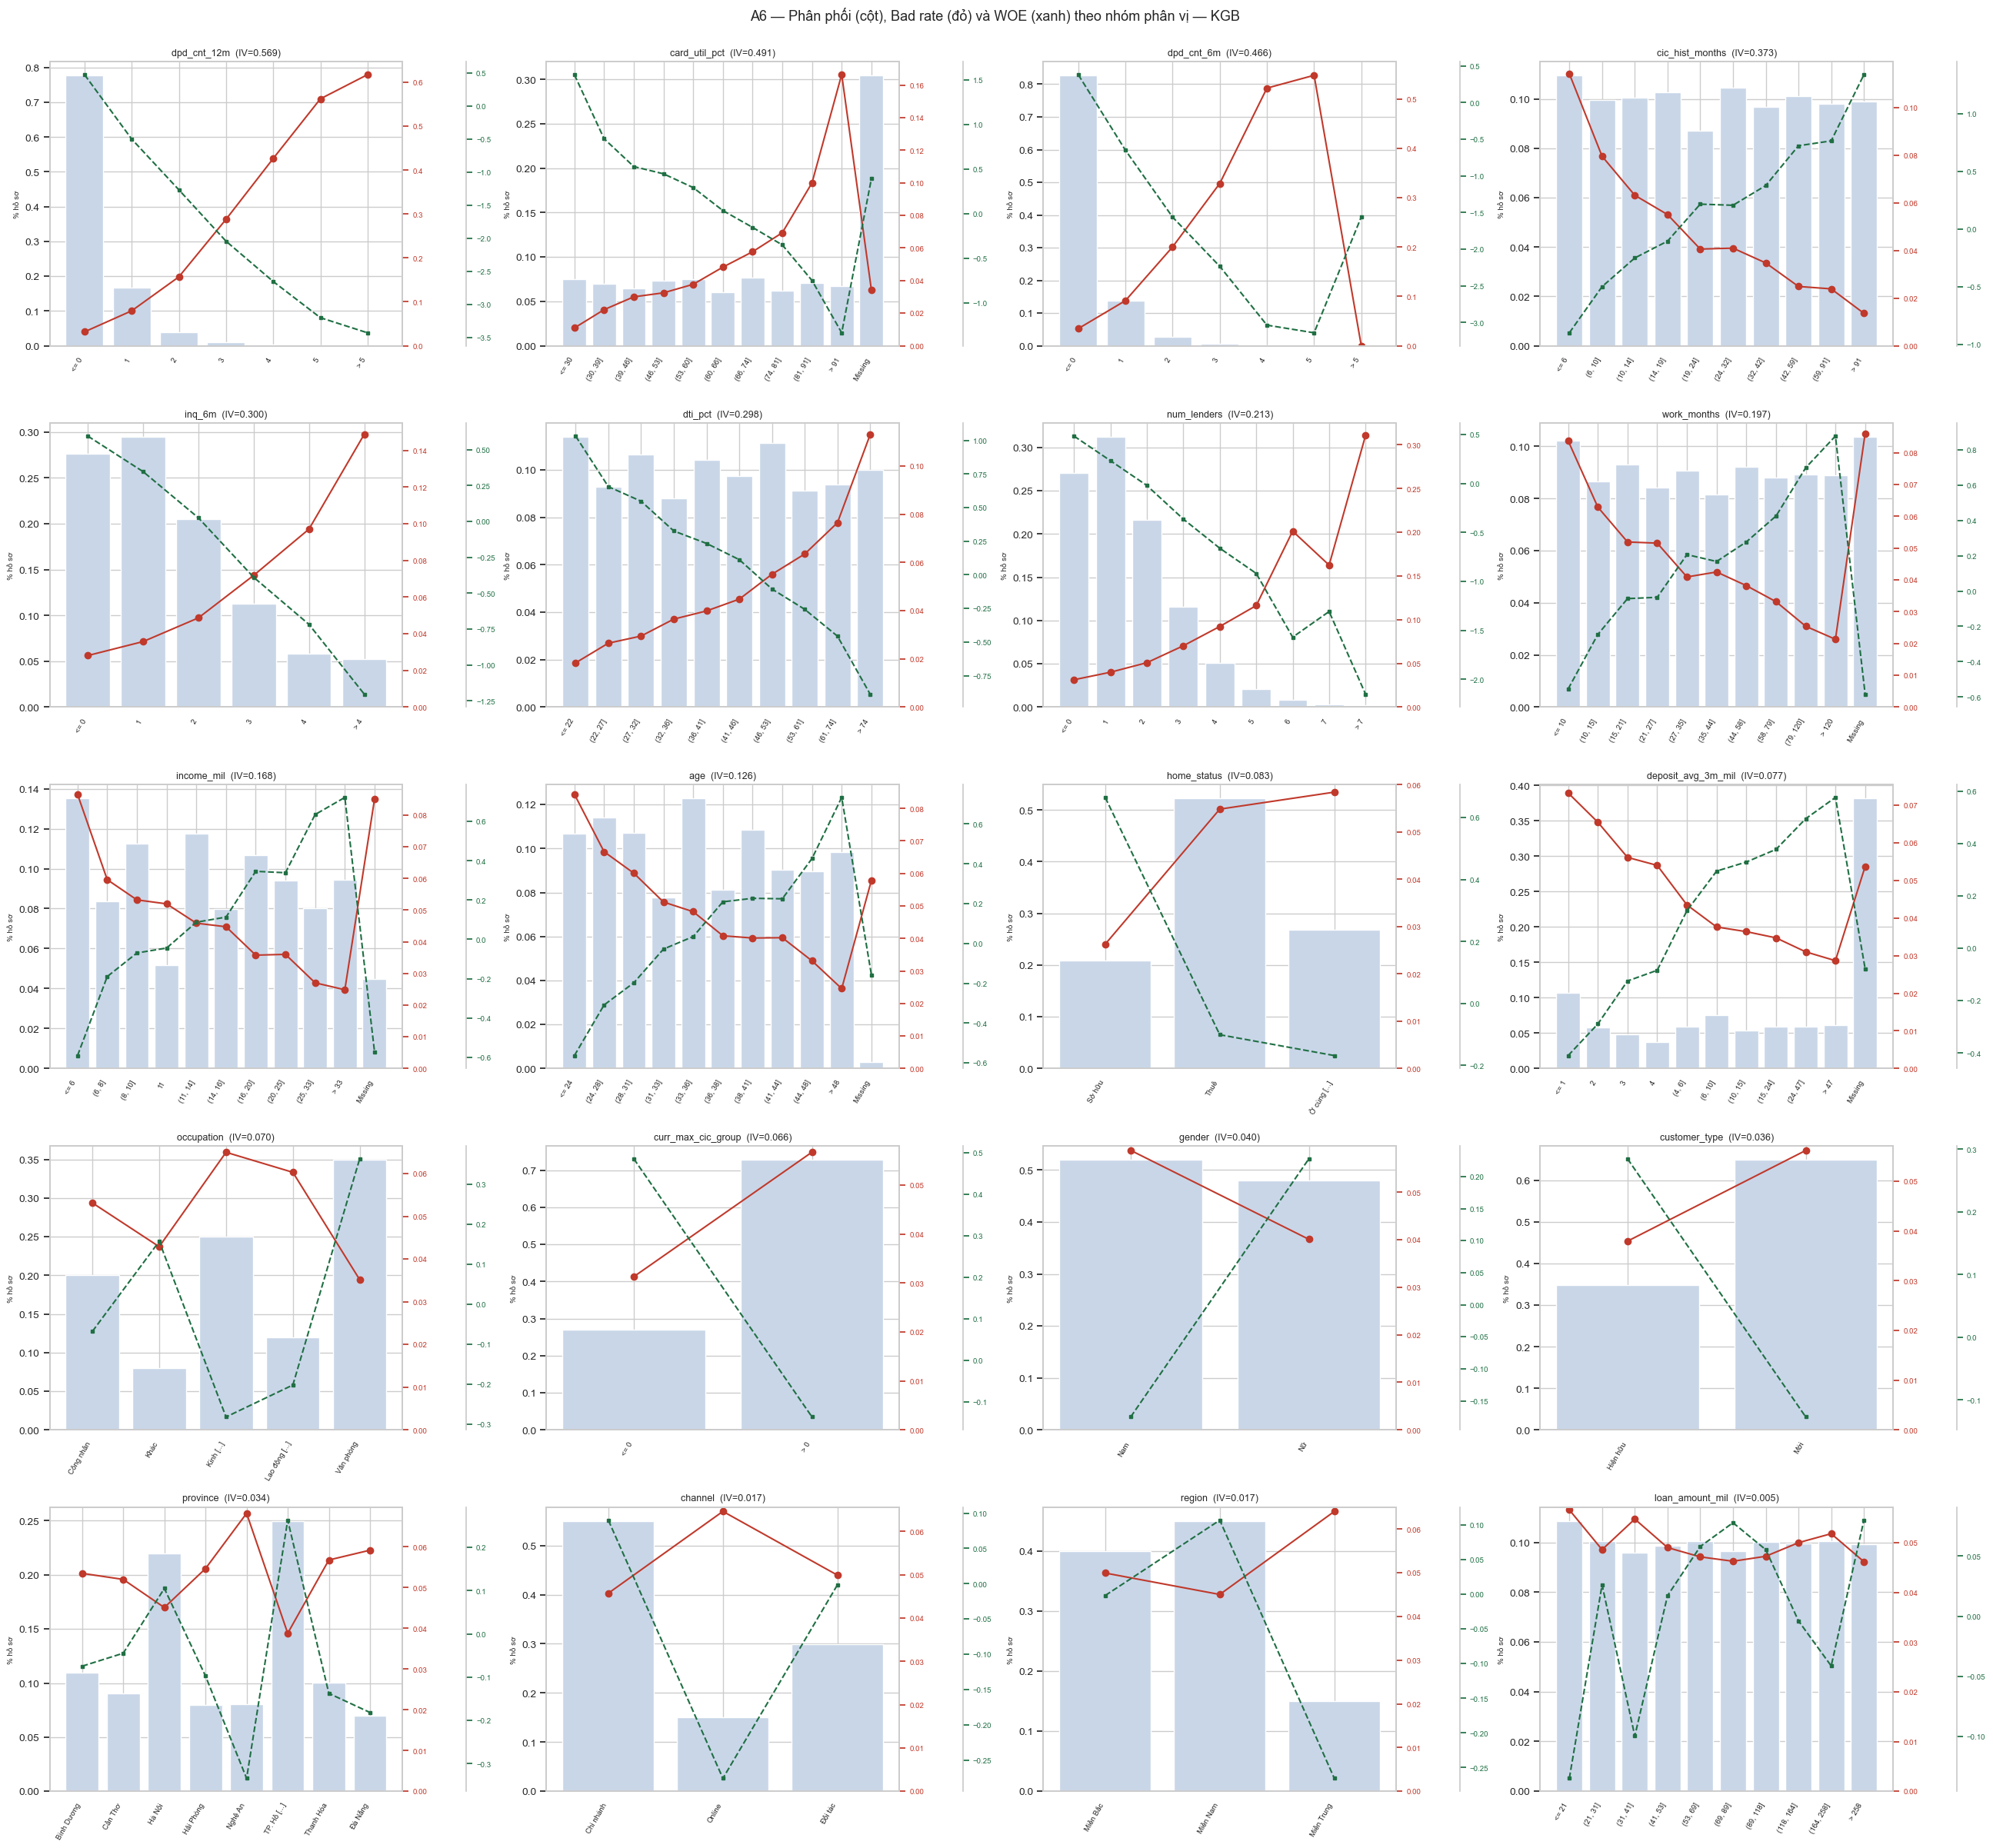

In [70]:
def plot_dec(ax, t, title):
    x = np.arange(len(t)); ax.bar(x, t["%Total"], color="#c9d6e8"); ax.set_xticks(x)
    ax.set_xticklabels([textwrap.shorten(str(b), 14) for b in t.Bin], rotation=60, ha="right", fontsize=7)
    ax.set_ylabel("% hồ sơ", fontsize=7); ax.set_title(f"{title}  (IV={t.IV.sum():.3f})", fontsize=9)
    a2 = ax.twinx(); a2.plot(x, t.BadRate, "o-", color="#c0392b", label="Bad rate"); a2.set_ylim(0, None); a2.grid(False)
    a3 = ax.twinx(); a3.spines["right"].set_position(("axes", 1.18)); a3.plot(x, t.WOE, "s--", color="#1f6f43", ms=3, label="WOE"); a3.grid(False)
    a2.tick_params(labelsize=7, colors="#c0392b"); a3.tick_params(labelsize=7, colors="#1f6f43")

names = iv_rank.variable.tolist()
fig, axes = plt.subplots(5, 4, figsize=(26, 24)); axes = axes.ravel()
for ax, c in zip(axes, names): plot_dec(ax, dec_tables[c], c)
for ax in axes[len(names):]: ax.axis("off")
plt.suptitle("A6 — Phân phối (cột), Bad rate (đỏ) và WOE (xanh) theo nhóm phân vị — KGB", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

**Business sense (đọc từ biểu đồ):** hầu hết biến rủi ro đi đúng kỳ vọng — `dti_pct`, `card_util_pct`, `inq_6m`, `num_lenders`, `dpd_cnt_*` tăng thì Bad rate tăng; `age`, `income_mil`, `work_months`, `cic_hist_months`, `deposit_avg_3m_mil` tăng thì Bad rate giảm. `loan_amount_mil` gần như phẳng (không phân biệt). Missing của `income_mil`/`work_months` có Bad rate **cao hơn** trung bình (thiếu thông tin khai báo), trong khi missing của `card_util_pct` có Bad rate **thấp** (khả năng không có thẻ/ít rủi ro).

## A7. Channel Segmentation — Bad rate theo phân khúc
### 1a. Bad rate theo Channel (và Channel × Customer_Type)

,Good,Bad,Total,BadRate,CI95_low,CI95_high,%Bad_of_portfolio
channel,,,,,,,
Chi nhánh,"21,066.0000","1,010.0000","22,076.0000",0.0458,0.0431,0.0486,0.5050
Online,"5,642.0000",390.0000,"6,032.0000",0.0647,0.0587,0.0711,0.1950
Đối tác,"11,419.0000",600.0000,"12,019.0000",0.0499,0.0462,0.0540,0.3000
TOÀN KGB,"38,127.0000","2,000.0000","40,127.0000",0.0498,0.0478,0.0520,1.0000


Good  Bad  Total  BadRate
channel   customer_type                            
Chi nhánh Hiện hữu        7497  266   7763   0.0343
          Mới            13569  744  14313   0.0520
Online    Hiện hữu        1831  119   1950   0.0610
          Mới             3811  271   4082   0.0664
Đối tác   Hiện hữu        4152  147   4299   0.0342
          Mới             7267  453   7720   0.0587

Chi-square: Bad rate khác nhau giữa các Channel? p = 1.72e-08


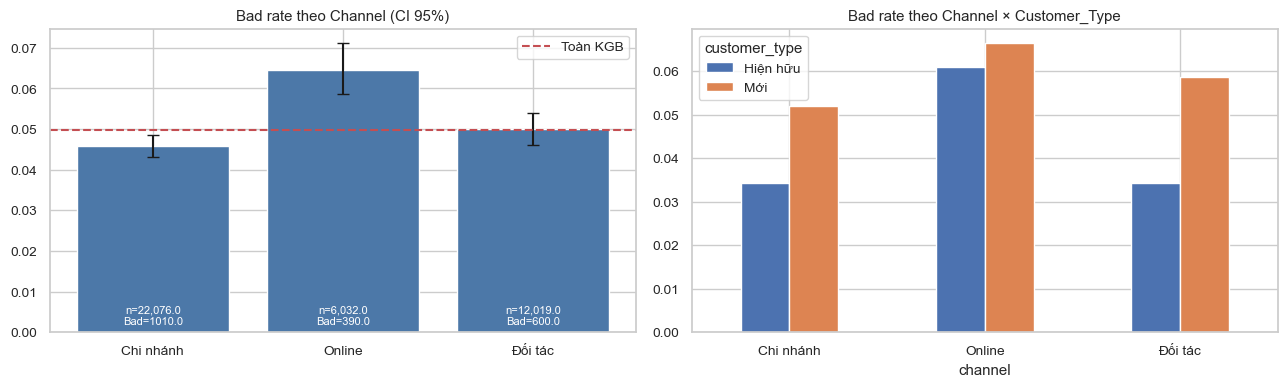

In [71]:
def wilson(b, n, z=1.96):
    p = b / n; d = 1 + z**2 / n; c = p + z**2 / (2 * n); r = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return (c - r) / d, (c + r) / d

seg = kgb.groupby("channel").target.agg(Good=lambda s: (s == 0).sum(), Bad="sum", Total="size"); seg["BadRate"] = seg.Bad / seg.Total
seg["CI95_low"], seg["CI95_high"] = wilson(seg.Bad, seg.Total); seg["%Bad_of_portfolio"] = seg.Bad / seg.Bad.sum()
seg.loc["TOÀN KGB"] = [(kgb.target == 0).sum(), kgb.target.sum(), len(kgb), kgb.target.mean(), *wilson(kgb.target.sum(), len(kgb)), 1.0]
display(seg)
seg2 = kgb.groupby(["channel", "customer_type"]).target.agg(Good=lambda s: (s == 0).sum(), Bad="sum", Total="size"); seg2["BadRate"] = seg2.Bad / seg2.Total
display(seg2)
ct, p_ch, *_ = stats.chi2_contingency(pd.crosstab(kgb.channel, kgb.target))
print(f"Chi-square: Bad rate khác nhau giữa các Channel? p = {p_ch:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
s_ = seg.iloc[:-1]; ax[0].bar(s_.index, s_.BadRate, yerr=[s_.BadRate - s_.CI95_low, s_.CI95_high - s_.BadRate], color="#4c78a8", capsize=4)
ax[0].axhline(kgb.target.mean(), color="r", ls="--", label="Toàn KGB"); ax[0].set_title("Bad rate theo Channel (CI 95%)"); ax[0].legend()
for i, (n_, b_) in enumerate(zip(s_.Total, s_.Bad)): ax[0].text(i, 0.002, f"n={n_:,}\nBad={b_}", ha="center", fontsize=8, color="w")
seg2.BadRate.unstack().plot.bar(ax=ax[1], rot=0); ax[1].set_title("Bad rate theo Channel × Customer_Type")
plt.tight_layout(); plt.show()

### 1b. Cùng một thuộc tính, dự báo có khác nhau giữa các Channel không?
Mỗi biến chia 5 nhóm (phân vị / category + Missing), rồi so Bad rate/WOE/IV của từng Channel với toàn KGB. Kiểm định **LRT tương tác** `bin × channel` (logit) với hiệu chỉnh Bonferroni, và đo **ΔWOE** (khác biệt thực tế) — chỉ coi là "dự báo khác nhau" khi vừa có ý nghĩa thống kê vừa lớn về độ lớn.

In [72]:
CHANNELS = sorted(kgb.channel.unique())
def seg_bins(s, kind, q=5):
    if kind == "cat": return s.fillna("Missing").astype(str)
    e = make_edges(s, q); idx = np.searchsorted(e, s.fillna(np.nan).values.astype(float), side="left"); lo = [-np.inf] + e; hi = e + [np.inf]
    lab = np.array([f"{i:02d}:{edge_label(l, h)}" for i, (l, h) in enumerate(zip(lo, hi))] + ["99:Missing"])
    return pd.Series(np.where(s.isna(), len(lab) - 1, idx)).map(lambda i: lab[i]).set_axis(s.index)

SEG_FEATS = [c for c in KIND if c != "channel"]
kb = kgb.copy(); rows = []; seg_detail = {}
for f in SEG_FEATS:
    kb["_b"] = seg_bins(kb[f], KIND[f])
    tt = kb.groupby("_b").target.agg(b="sum", n="size"); tt["g"] = tt.n - tt.b
    w_tot, iv_tot = woe_iv(tt.g, tt.b); tot_br = tt.b / tt.n
    row = dict(feature=f, IV_total=iv_tot.sum()); det = {"Total": tt.assign(WOE=w_tot)}
    for ch in CHANNELS:
        sub = kb[kb.channel == ch].groupby("_b").target.agg(b="sum", n="size").reindex(tt.index).fillna(0); sub["g"] = sub.n - sub.b
        w_c, iv_c = woe_iv(sub.g, sub.b); ok = sub.n >= 50
        row[f"IV_{ch}"] = iv_c.sum()
        row[f"rho_{ch}"] = spearman_safe(tot_br[ok.values], (sub.b / sub.n.replace(0, np.nan))[ok.values])
        row[f"maxΔWOE_{ch}"] = float(np.max(np.abs(w_c[ok.values] - w_tot[ok.values]))) if ok.any() else np.nan
        det[ch] = sub.assign(WOE=w_c)
    
    # Độ dốc (sức dự báo): hồi quy logit y ~ WOE_toàn_KGB(bin) trong từng Channel. Slope≈1 = cùng sức dự báo như toàn danh mục.
    wmap = pd.Series(w_tot, index=tt.index); kb["_w"] = -kb._b.map(wmap)
    sl, se = [], []
    for ch in CHANNELS:
        sub_ = kb[kb.channel == ch]
        try:
            r_ = sm.Logit(sub_.target, sm.add_constant(sub_["_w"])).fit(disp=0); sl.append(r_.params["_w"]); se.append(r_.bse["_w"])
        except Exception: sl.append(np.nan); se.append(np.nan)
        row[f"slope_{ch}"] = sl[-1]
    sl, se = np.array(sl), np.array(se); wts = 1 / se**2; sbar = np.nansum(sl * wts) / np.nansum(wts)
    row["Q_p_slope"] = float(stats.chi2.sf(np.nansum(wts * (sl - sbar) ** 2), len(CHANNELS) - 1))
    d_ = pd.DataFrame({"y": kb.target, "bn": kb._b, "ch": kb.channel})
    try:
        m0 = smf.logit("y ~ C(bn) + C(ch)", d_).fit(disp=0, maxiter=200); m1 = smf.logit("y ~ C(bn) * C(ch)", d_).fit(disp=0, maxiter=200)
        lr = 2 * (m1.llf - m0.llf); row["LRT_p"] = float(stats.chi2.sf(lr, m1.df_model - m0.df_model))
    except Exception: row["LRT_p"] = np.nan
    rows.append(row); seg_detail[f] = det
seg_tab = pd.DataFrame(rows)
ALPHA = 0.05 / len(SEG_FEATS)
seg_tab["max_ΔWOE"] = seg_tab[[f"maxΔWOE_{c}" for c in CHANNELS]].max(axis=1)
seg_tab["min_rho"] = seg_tab[[f"rho_{c}" for c in CHANNELS]].min(axis=1)
seg_tab["differs_shape"] = (seg_tab.LRT_p < ALPHA) & (seg_tab.max_ΔWOE > 0.30)          # hình dạng/thứ hạng Bad rate khác
SLOPE_COLS = [f"slope_{c}" for c in CHANNELS]
seg_tab["differs_strength"] = (seg_tab.Q_p_slope < ALPHA) & ((seg_tab[SLOPE_COLS] - 1).abs().max(axis=1) > 0.25)  # độ mạnh dự báo khác
seg_tab["differs"] = seg_tab.differs_shape | seg_tab.differs_strength
seg_tab = seg_tab.sort_values("IV_total", ascending=False).reset_index(drop=True)
print(f"Bonferroni α = {ALPHA:.4f}. differs_shape = LRT(bin×channel) p<α VÀ max|ΔWOE|>0.30 | differs_strength = dị biệt độ dốc (Q-test) p<α VÀ |slope−1|>0.25")
display(seg_tab[["feature", "IV_total"] + [f"IV_{c}" for c in CHANNELS] + SLOPE_COLS + ["min_rho", "max_ΔWOE", "LRT_p", "Q_p_slope", "differs_shape", "differs_strength"]])

Bonferroni α = 0.0026. differs_shape = LRT(bin×channel) p<α VÀ max|ΔWOE|>0.30 | differs_strength = dị biệt độ dốc (Q-test) p<α VÀ |slope−1|>0.25


,feature,IV_total,IV_Chi nhánh,IV_Online,IV_Đối tác,slope_Chi nhánh,slope_Online,slope_Đối tác,min_rho,max_ΔWOE,LRT_p,Q_p_slope,differs_shape,differs_strength
0,dpd_cnt_12m,0.5162,0.5874,0.2563,0.5946,1.0562,0.7451,1.0563,1.0000,0.3351,0.0011,0.0002,True,True
1,card_util_pct,0.4541,0.5361,0.2205,0.4819,1.0836,0.7015,1.0276,1.0000,0.4431,0.0236,0.0001,False,True
2,dpd_cnt_6m,0.3597,0.3998,0.1873,0.4218,1.0501,0.7438,1.0723,NaN,0.2197,0.0022,0.0025,False,True
3,cic_hist_months,0.3444,0.3540,0.1847,0.4381,1.0106,0.7314,1.1217,1.0000,0.2359,0.0535,0.0048,False,False
4,inq_6m,0.2892,0.3620,0.1818,0.2550,1.1069,0.7548,0.9432,1.0000,0.2670,0.0029,0.0038,False,False
5,dti_pct,0.2762,0.2888,0.2150,0.2901,1.0201,0.8748,1.0311,1.0000,0.1017,0.9498,0.4188,False,False
6,num_lenders,0.1925,0.2100,0.1103,0.2348,1.0434,0.7063,1.0872,1.0000,0.3832,0.0138,0.0177,False,False
7,work_months,0.1900,0.2180,0.0664,0.2615,1.0658,0.5627,1.1419,1.0000,0.4341,0.0048,0.0005,False,True
8,income_mil,0.1573,0.2309,0.0432,0.1373,1.2039,0.5003,0.9305,0.9429,0.4691,0.0092,0.0000,False,True
9,age,0.1150,0.1416,0.0509,0.1104,1.1029,0.6171,0.9586,0.6571,0.6163,0.1237,0.0379,False,False


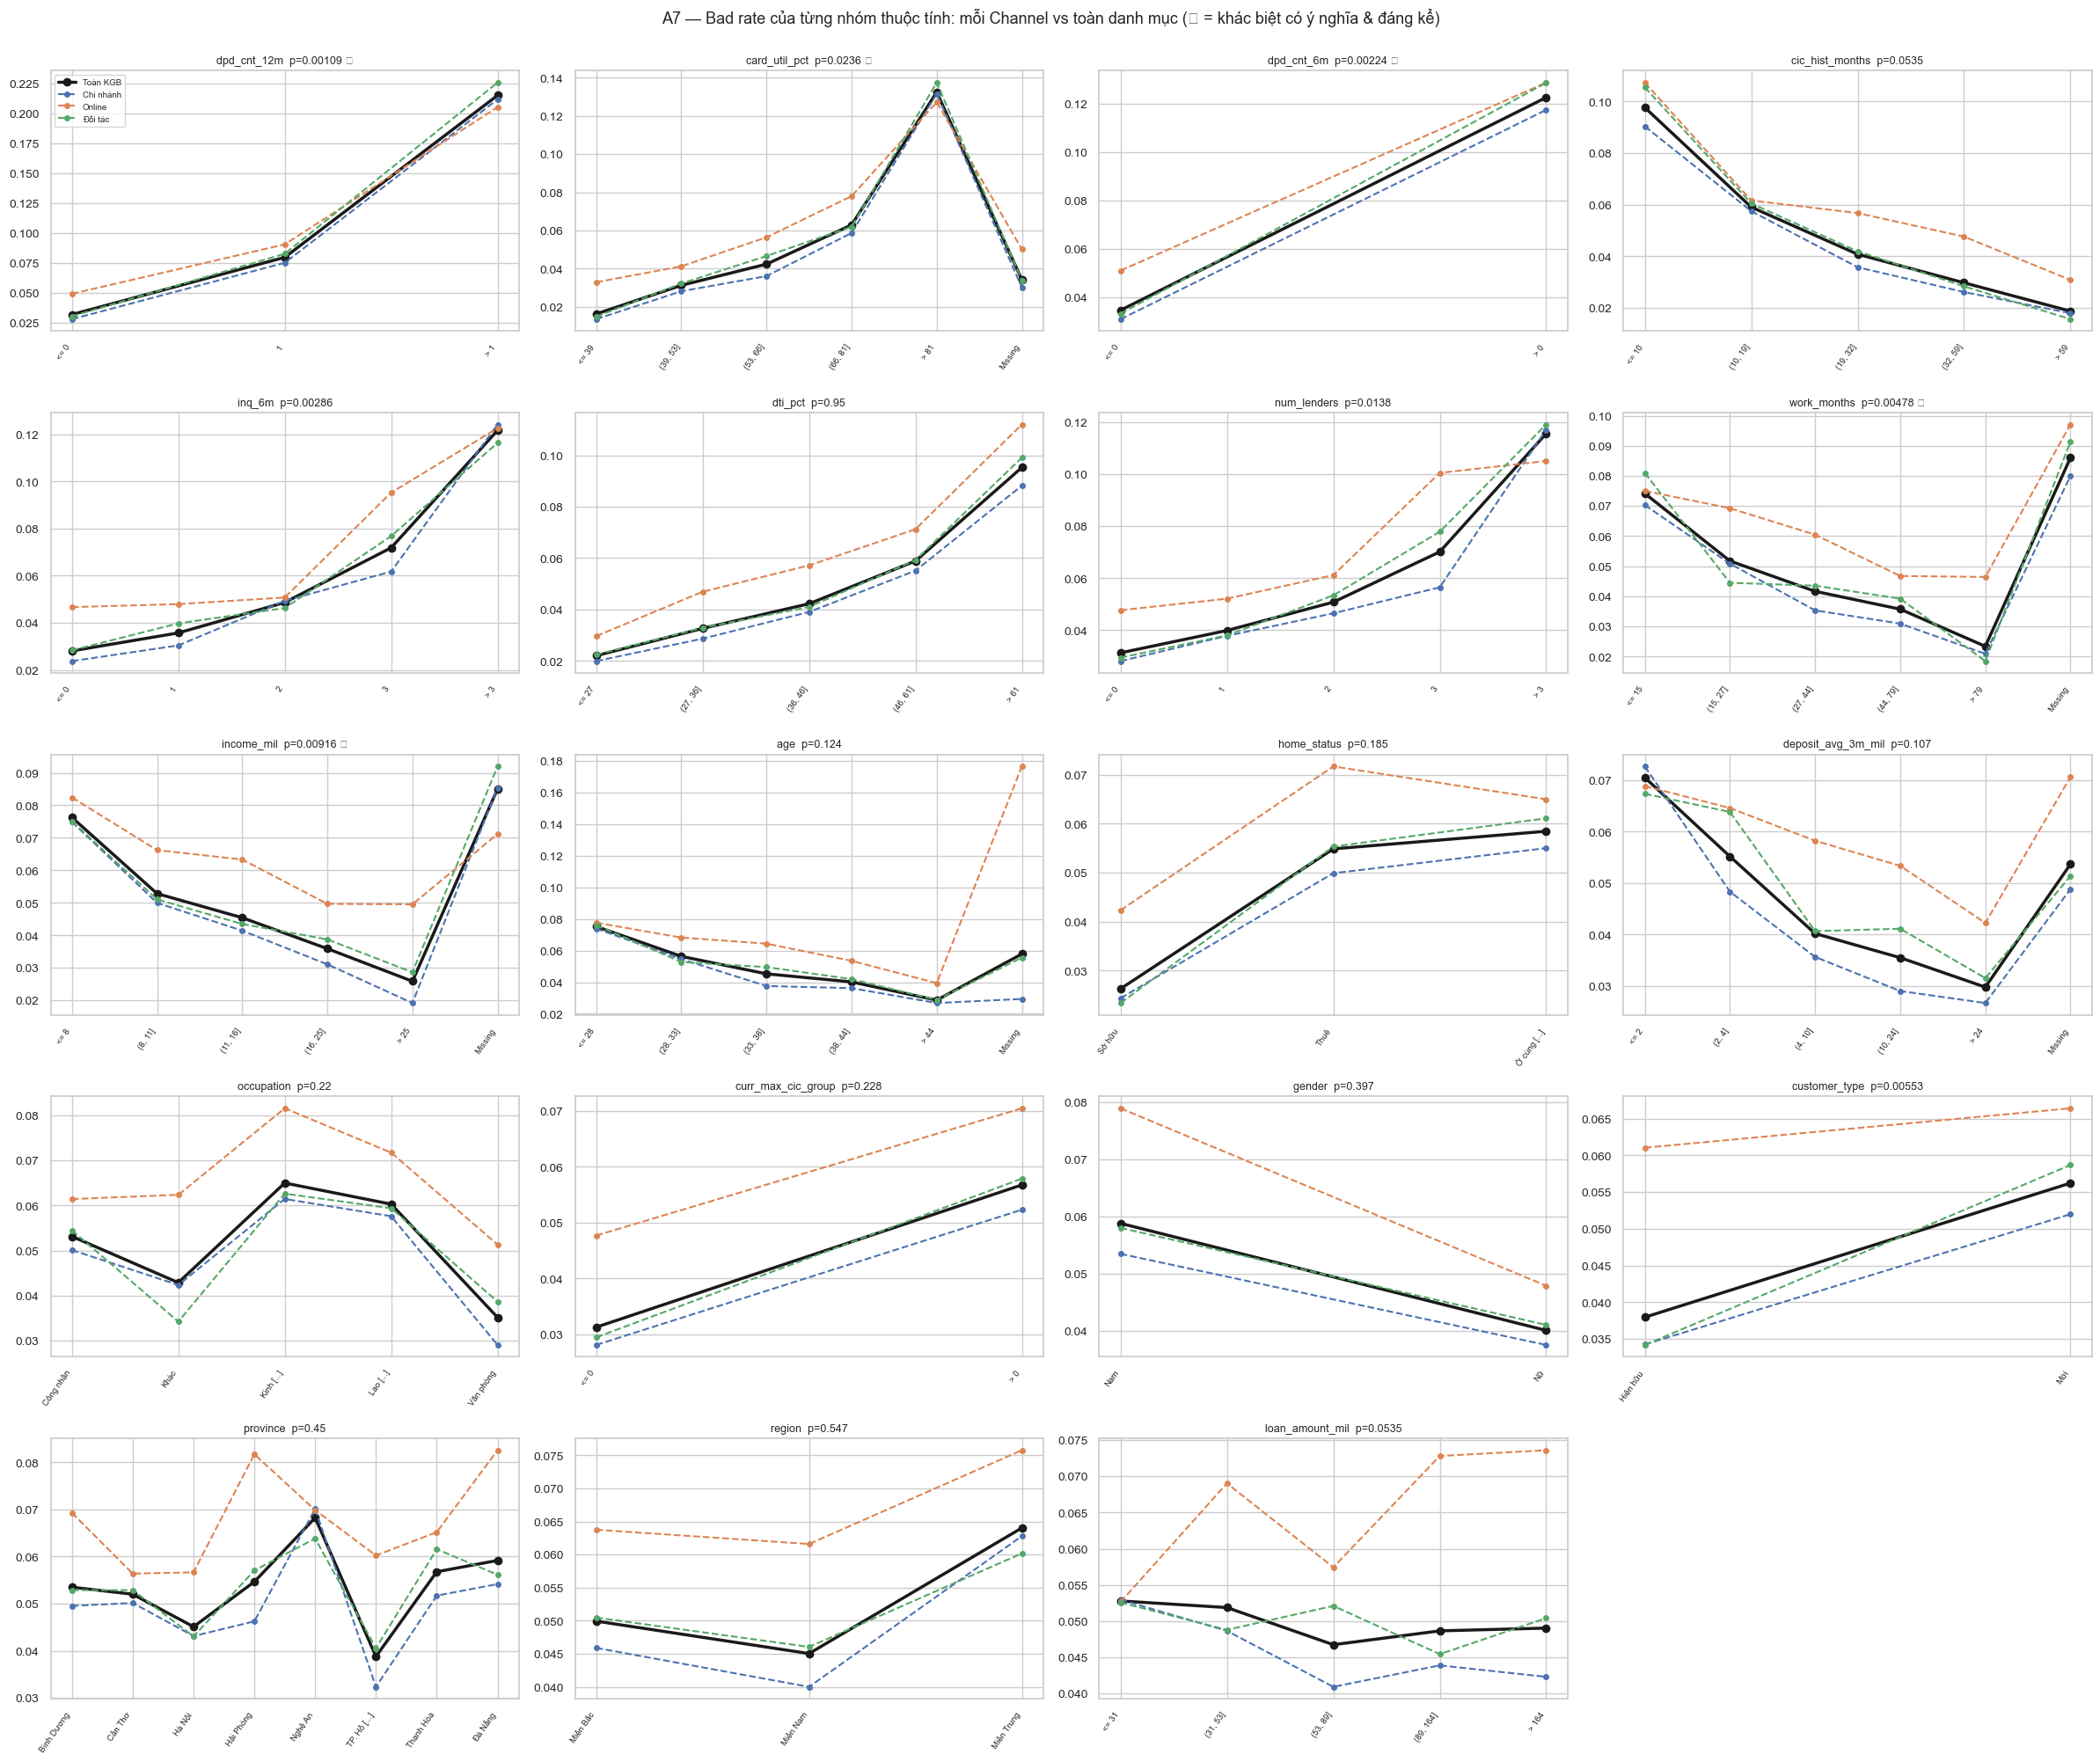

In [73]:
# Bad rate theo nhóm thuộc tính: từng Channel vs toàn KGB (đường)
feats_plot = seg_tab.feature.tolist()
fig, axes = plt.subplots(5, 4, figsize=(24, 20)); axes = axes.ravel()
for ax, f in zip(axes, feats_plot):
    det = seg_detail[f]; x = np.arange(len(det["Total"]))
    ax.plot(x, det["Total"].b / det["Total"].n, "k-o", lw=2.5, label="Toàn KGB")
    for ch in CHANNELS: ax.plot(x, det[ch].b / det[ch].n.replace(0, np.nan), "o--", ms=4, label=ch)
    ax.set_xticks(x); ax.set_xticklabels([textwrap.shorten(i.split(":")[-1], 12) for i in det["Total"].index], rotation=55, ha="right", fontsize=7)
    r = seg_tab.set_index("feature").loc[f]; ax.set_title(f"{f}  p={r.LRT_p:.3g}{' ★' if r.differs else ''}", fontsize=9)
axes[0].legend(fontsize=7)
for ax in axes[len(feats_plot):]: ax.axis("off")
plt.suptitle("A7 — Bad rate của từng nhóm thuộc tính: mỗi Channel vs toàn danh mục (★ = khác biệt có ý nghĩa & đáng kể)", y=1.0)
plt.tight_layout(); plt.show()

## A8. Segmentation Recommendation (quy tắc tường minh)

In [74]:
train_n_bad = {ch: int(kgb[kgb.channel == ch].target.sum() * (1 - TEST_SIZE)) for ch in CHANNELS}
material = seg_tab[seg_tab.IV_total >= IV_MIN]
share_diff = material.differs.mean() if len(material) else 0
bad_ok = {ch: n >= MIN_BAD_SEGMENT for ch, n in train_n_bad.items()}
iv_ratio = (material[[f"IV_{c}" for c in CHANNELS]].div(material.IV_total, axis=0))
print(f"Số Bad ước tính trên Train theo Channel: {train_n_bad}  (ngưỡng tối thiểu {MIN_BAD_SEGMENT}) -> đủ: {bad_ok}")
print(f"Biến có IV ≥ {IV_MIN}: {len(material)} | trong đó dự báo khác biệt giữa Channel: {int(material.differs.sum())} ({share_diff:.0%})")
print("  - khác về HÌNH DẠNG:", material.loc[material.differs_shape, "feature"].tolist())
print("  - khác về ĐỘ MẠNH dự báo:", material.loc[material.differs_strength, "feature"].tolist())
print("Slope trung vị theo Channel (các biến có IV≥0.02; 1.0 = như toàn KGB):", material[SLOPE_COLS].median().round(2).to_dict())
print(f"Thứ hạng Bad rate trong từng Channel so với toàn KGB (min Spearman ρ trung vị) = {material.min_rho.median():.2f}")
cond_diff = share_diff >= 1 / 3; cond_bad = all(bad_ok.values())
SEGMENT_MODEL = bool(cond_diff and cond_bad)
print("\nĐiều kiện 1 (≥1/3 biến quan trọng dự báo khác nhau):", cond_diff, "| Điều kiện 2 (mọi phân khúc đủ Bad):", cond_bad)
print(">>> KHUYẾN NGHỊ:", "CÓ phân khúc mô hình theo Channel" if SEGMENT_MODEL else "KHÔNG phân khúc — xây 1 mô hình chung, đưa Channel vào như một biến/kiểm soát (monitor theo Channel)")

Số Bad ước tính trên Train theo Channel: {'Chi nhánh': 808, 'Online': 312, 'Đối tác': 480}  (ngưỡng tối thiểu 300) -> đủ: {'Chi nhánh': True, 'Online': True, 'Đối tác': True}
Biến có IV ≥ 0.02: 17 | trong đó dự báo khác biệt giữa Channel: 5 (29%)
  - khác về HÌNH DẠNG: ['dpd_cnt_12m']
  - khác về ĐỘ MẠNH dự báo: ['dpd_cnt_12m', 'card_util_pct', 'dpd_cnt_6m', 'work_months', 'income_mil']
Slope trung vị theo Channel (các biến có IV≥0.02; 1.0 = như toàn KGB): {'slope_Chi nhánh': 1.06, 'slope_Online': 0.7, 'slope_Đối tác': 1.03}
Thứ hạng Bad rate trong từng Channel so với toàn KGB (min Spearman ρ trung vị) = 1.00

Điều kiện 1 (≥1/3 biến quan trọng dự báo khác nhau): False | Điều kiện 2 (mọi phân khúc đủ Bad): True
>>> KHUYẾN NGHỊ: KHÔNG phân khúc — xây 1 mô hình chung, đưa Channel vào như một biến/kiểm soát (monitor theo Channel)


## Khuyến nghị segmentation theo Channel (câu 1)

**Khuyến nghị: KHÔNG tách mô hình theo Channel — xây 1 mô hình chung, giám sát hiệu năng theo Channel.**

| Channel | Hồ sơ KGB | Bad | Bad rate | Bad ước tính trên Train |
|---|---|---|---|---|
| Chi nhánh | 22,076 | 1,010 | 4.58% | ≈ 808 |
| Đối tác | 12,019 | 600 | 4.99% | ≈ 480 |
| Online | 6,032 | 390 | **6.47%** | ≈ 312 |
| Toàn KGB | 40,127 | 2,000 | 4.98% | 1,600 |

**Lý do (đối chiếu hai tiêu chí đề bài):**
1. *Cùng thuộc tính có dự báo khác nhau giữa các kênh không?* — Chỉ **một phần nhỏ**. Trong 17 biến có IV ≥ 0.02, chỉ 5 biến (29%, dưới ngưỡng 1/3 đặt ra) có khác biệt có ý nghĩa sau hiệu chỉnh Bonferroni; khác biệt về **hình dạng** chỉ có ở `dpd_cnt_12m`. Thứ hạng Bad rate theo nhóm giữ nguyên trong mọi kênh (Spearman ρ ≈ 1) — **cùng chiều, khác độ dốc**, không phải khác logic rủi ro.
2. *Khác biệt đến từ đâu?* — **Chi nhánh và Đối tác gần như giống hệt** (độ dốc ≈ 1.03–1.06). Chỉ **Online** yếu hơn (độ dốc trung vị ≈ 0.70; IV chỉ bằng ~½ ở hầu hết biến). Khoảng cách lớn nhất ở các biến **tự khai** — `income_mil` (độ dốc 0.50), `work_months` (0.56) — gợi ý (*giả thuyết cần xác nhận với Business*) rằng kênh Online thiếu bước thẩm định/xác minh nên thông tin khai báo kém tin cậy hơn.
3. *Đủ Bad để xây mô hình riêng?* — Cả 3 kênh vượt ngưỡng tối thiểu 300 Bad trên Train, nhưng **Online chỉ ≈ 312 Bad** — sát ngưỡng, ước lượng 10–13 biến WOE sẽ kém ổn định; trong khi nếu gộp thì mô hình chung được học từ 1,600 Bad.

**Hành động đi kèm:** (i) theo dõi Gini/KS và hiệu chuẩn (calibration) riêng cho Online; (ii) nếu cần phản ánh Bad rate cao hơn của Online, dùng điều chỉnh ở bước cutoff/pricing hoặc hiệu chuẩn theo kênh thay vì tách mô hình (`channel` có IV chỉ 0.016 nên không tự nó đủ vào mô hình); (iii) xem xét lại việc tách riêng nếu Bad Online vượt ≈ 600 và khoảng cách độ dốc còn tồn tại.

## A9. Sampling 80/20 — stratify đồng thời Good/Bad × Channel × Customer_Type

In [75]:
kgb["strata"] = kgb.target.astype(str) + "|" + kgb.channel + "|" + kgb.customer_type
print("Số strata:", kgb.strata.nunique(), "| strata nhỏ nhất:", kgb.strata.value_counts().min())
train, hold = train_test_split(kgb, test_size=TEST_SIZE, stratify=kgb.strata, random_state=SEED)
train = train.drop(columns="strata").sort_index(); hold = hold.drop(columns="strata").sort_index(); kgb = kgb.drop(columns="strata")
json.dump({"random_seed": SEED, "test_size": TEST_SIZE, "stratify": "target × channel × customer_type"}, open(OUT / "sampling_config.json", "w"))
print(f"Train: {len(train):,} (Bad {train.target.sum():,}, {train.target.mean():.3%}) | Holdout: {len(hold):,} (Bad {hold.target.sum():,}, {hold.target.mean():.3%})")

Số strata: 12 | strata nhỏ nhất: 119
Train: 32,101 (Bad 1,600, 4.984%) | Holdout: 8,026 (Bad 400, 4.984%)


## A10. Sampling Validation

In [76]:
def share_cmp(a, b, cols, name_a="Train", name_b="Holdout"):
    ka = a.groupby(cols).size().rename(name_a); kb_ = b.groupby(cols).size().rename(name_b)
    t = pd.concat([ka, kb_], axis=1).fillna(0)
    t[f"%{name_a}"] = t[name_a] / t[name_a].sum(); t[f"%{name_b}"] = t[name_b] / t[name_b].sum(); t["Δ(pp)"] = (t[f"%{name_b}"] - t[f"%{name_a}"]) * 100
    return t
tr_ = train.assign(label=train.target.map({0: "Good", 1: "Bad"})); ho_ = hold.assign(label=hold.target.map({0: "Good", 1: "Bad"}))
samp_tabs = {"Good/Bad": ["label"], "Channel": ["channel"], "Customer_Type": ["customer_type"],
             "Channel×Customer_Type": ["channel", "customer_type"], "Good/Bad×Channel": ["label", "channel"],
             "Good/Bad×Channel×Customer_Type": ["label", "channel", "customer_type"]}
samp_out = {}
for nm, cols in samp_tabs.items():
    t = share_cmp(tr_, ho_, cols); samp_out[nm] = t; print(f"--- {nm}  (max |Δ| = {t['Δ(pp)'].abs().max():.3f} pp)"); display(t)

--- Good/Bad  (max |Δ| = 0.000 pp)


,Train,Holdout,%Train,%Holdout,Δ(pp)
label,,,,,
Bad,1600,400,0.0498,0.0498,-0.0005
Good,30501,7626,0.9502,0.9502,0.0005


--- Channel  (max |Δ| = 0.008 pp)


,Train,Holdout,%Train,%Holdout,Δ(pp)
channel,,,,,
Chi nhánh,17660,4416,0.5501,0.5502,0.0073
Online,4826,1206,0.1503,0.1503,-0.0076
Đối tác,9615,2404,0.2995,0.2995,0.0003


--- Customer_Type  (max |Δ| = 0.009 pp)


...

Train  Holdout  %Train  %Holdout   Δ(pp)
channel   customer_type                                          
Chi nhánh Hiện hữu        6210     1553  0.1935    0.1935  0.0044
          Mới            11450     2863  0.3567    0.3567  0.0029
Online    Hiện hữu        1560      390  0.0486    0.0486 -0.0005
          Mới             3266      816  0.1017    0.1017 -0.0072
Đối tác   Hiện hữu        3440      859  0.1072    0.1070 -0.0135
          Mới             6175     1545  0.1924    0.1925  0.0138

--- Good/Bad×Channel  (max |Δ| = 0.008 pp)


Train  Holdout  %Train  %Holdout   Δ(pp)
label channel                                            
Bad   Chi nhánh    808      202  0.0252    0.0252 -0.0002
      Online       312       78  0.0097    0.0097 -0.0001
      Đối tác      480      120  0.0150    0.0150 -0.0001
Good  Chi nhánh  16852     4214  0.5250    0.5250  0.0076
      Online      4514     1128  0.1406    0.1405 -0.0075
      Đối tác     9135     2284  0.2846    0.2846  0.0005

--- Good/Bad×Channel×Customer_Type  (max |Δ| = 0.008 pp)


Train  Holdout  %Train  %Holdout   Δ(pp)
label channel   customer_type                                          
Bad   Chi nhánh Hiện hữu         213       53  0.0066    0.0066 -0.0032
                Mới              595      149  0.0185    0.0186  0.0029
      Online    Hiện hữu          95       24  0.0030    0.0030  0.0031
                Mới              217       54  0.0068    0.0067 -0.0032
      Đối tác   Hiện hữu         118       29  0.0037    0.0036 -0.0063
                Mới              362       91  0.0113    0.0113  0.0061
Good  Chi nhánh Hiện hữu        5997     1500  0.1868    0.1869  0.0076
                Mới            10855     2714  0.3382    0.3382 -0.0000
      Online    Hiện hữu        1465      366  0.0456    0.0456 -0.0035
                Mới             3049      762  0.0950    0.0949 -0.0040
      Đối tác   Hiện hữu        3322      830  0.1035    0.1034 -0.0072
                Mới             5813     1454  0.1811    0.1812  0.0077

## A11. PSI Train vs Holdout — 10 bucket tham chiếu theo Train
PSI Portfolio / PSI Good / PSI Bad cho từng biến; đồng thời so Bad rate tổng và theo bucket. Với PSI Bad, nhiễu lấy mẫu kỳ vọng ≈ (K−1)(1/n_Bad,Train + 1/n_Bad,other) — cột `noise_floor_bad` giúp phân biệt "lệch thật" với "nhiễu do ít Bad".

In [77]:
def bucketize(tr_s, ot_s, kind, q=10):
    if kind == "num":
        e = make_edges(tr_s, q); k = len(e) + 1
        f = lambda s: np.where(s.isna(), k, np.searchsorted(e, s.fillna(0).astype(float).values, side="left"))
        labs = [edge_label(l, h) for l, h in zip([-np.inf] + e, e + [np.inf])] + ["Missing"]
        return f(tr_s), f(ot_s), labs
    cats = sorted(tr_s.dropna().unique()); mp = {c: i for i, c in enumerate(cats)}; k = len(cats)
    f = lambda s: np.where(s.isna(), k + 1, s.map(mp).fillna(k).astype(int).values)
    return f(tr_s), f(ot_s), [str(c) for c in cats] + ["Other(unseen)", "Missing"]

def psi_report(tr, ot, feats, other_name):
    rows, det = [], {}
    for c in feats:
        a, b, labs = bucketize(tr[c], ot[c], KIND[c]); K = len(labs)
        cnt = lambda idx, mask: np.bincount(idx[mask], minlength=K)
        ya, yb = tr.target.values, ot.target.values
        ca, cb = cnt(a, np.ones(len(a), bool)), cnt(b, np.ones(len(b), bool))
        ga, gb = cnt(a, ya == 0), cnt(b, yb == 0); ba, bb = cnt(a, ya == 1), cnt(b, yb == 1)
        t = pd.DataFrame({"Bucket": labs, f"n_Train": ca, f"n_{other_name}": cb, "%Train": ca / ca.sum(), f"%{other_name}": cb / cb.sum(),
                          "BR_Train": ba / np.where(ca == 0, np.nan, ca), f"BR_{other_name}": bb / np.where(cb == 0, np.nan, cb)})
        t["ΔBR(pp)"] = (t[f"BR_{other_name}"] - t.BR_Train) * 100; det[c] = t[(t.n_Train > 0) | (t[f"n_{other_name}"] > 0)]
        ok = (ca >= 30) & (cb >= 30); nz = (ba > 0).sum()
        rows.append({"feature": c, "PSI_Portfolio": psi_counts(ca, cb), "PSI_Good": psi_counts(ga, gb), "PSI_Bad": psi_counts(ba, bb),
                     "noise_floor_bad": (max(nz, 1) - 1) * (1 / ba.sum() + 1 / bb.sum()),
                     "BadRate_Train": ya.mean(), f"BadRate_{other_name}": yb.mean(),
                     "max|ΔBR_bucket|(pp)": float(np.nanmax(np.abs(t["ΔBR(pp)"].values[ok[:len(t)]]))) if ok.any() else np.nan,
                     "unseen_cat_%": float((b == K - 2).mean()) if KIND[c] == "cat" else 0.0})
    r = pd.DataFrame(rows)
    r["flag_Portfolio"] = r.PSI_Portfolio.map(psi_flag); r["flag_Bad"] = [("Ổn định" if p < max(PSI_WARN, 2 * n) else psi_flag(p)) for p, n in zip(r.PSI_Bad, r.noise_floor_bad)]
    return r.sort_values("PSI_Portfolio", ascending=False).reset_index(drop=True), det

FEATS_PSI = list(KIND)
psi_ho, det_ho = psi_report(train, hold, FEATS_PSI, "Holdout")
display(psi_ho)
print("Max PSI Portfolio:", round(psi_ho.PSI_Portfolio.max(), 4), "| Max PSI Good:", round(psi_ho.PSI_Good.max(), 4), "| Max PSI Bad:", round(psi_ho.PSI_Bad.max(), 4),)
print(f"Bad rate: Train {train.target.mean():.3%} vs Holdout {hold.target.mean():.3%}")

,feature,PSI_Portfolio,PSI_Good,PSI_Bad,noise_floor_bad,BadRate_Train,BadRate_Holdout,max|ΔBR_bucket|(pp),unseen_cat_%,flag_Portfolio,flag_Bad
0,deposit_avg_3m_mil,0.0028,0.0029,0.0183,0.0312,0.0498,0.0498,1.4739,0.0000,Ổn định,Ổn định
1,num_lenders,0.0022,0.0024,0.0261,0.0250,0.0498,0.0498,2.9924,0.0000,Ổn định,Ổn định
2,card_util_pct,0.0019,0.0018,0.0403,0.0312,0.0498,0.0498,2.6307,0.0000,Ổn định,Ổn định
3,dpd_cnt_12m,0.0019,0.0014,0.0351,0.0188,0.0498,0.0498,5.1475,0.0000,Ổn định,Ổn định
4,loan_amount_mil,0.0018,0.0015,0.0632,0.0281,0.0498,0.0498,1.8522,0.0000,Ổn định,Ổn định
5,work_months,0.0015,0.0015,0.0363,0.0312,0.0498,0.0498,1.9935,0.0000,Ổn định,Ổn định
6,income_mil,0.0013,0.0017,0.0210,0.0312,0.0498,0.0498,1.7160,0.0000,Ổn định,Ổn định
7,province,0.0012,0.0011,0.0111,0.0219,0.0498,0.0498,0.9740,0.0000,Ổn định,Ổn định
8,age,0.0011,0.0011,0.0348,0.0312,0.0498,0.0498,1.0314,0.0000,Ổn định,Ổn định
9,occupation,0.0009,0.0009,0.0116,0.0125,0.0498,0.0498,1.0304,0.0000,Ổn định,Ổn định


Max PSI Portfolio: 0.0028 | Max PSI Good: 0.0029 | Max PSI Bad: 0.0632
Bad rate: Train 4.984% vs Holdout 4.984%


## A12. PSI Train vs OOT (2024H1) — dùng ranh giới của Train

,feature,PSI_Portfolio,PSI_Good,PSI_Bad,noise_floor_bad,BadRate_Train,BadRate_OOT,max|ΔBR_bucket|(pp),unseen_cat_%,flag_Portfolio,flag_Bad
0,income_mil,0.0261,0.0265,0.0506,0.0224,0.0498,0.0521,1.8665,0.0000,Ổn định,Ổn định
1,age,0.0128,0.0128,0.0217,0.0224,0.0498,0.0521,0.7264,0.0000,Ổn định,Ổn định
2,work_months,0.0024,0.0026,0.0155,0.0224,0.0498,0.0521,1.5580,0.0000,Ổn định,Ổn định
3,deposit_avg_3m_mil,0.0017,0.0019,0.0091,0.0224,0.0498,0.0521,1.5113,0.0000,Ổn định,Ổn định
4,num_lenders,0.0011,0.0009,0.0140,0.0179,0.0498,0.0521,8.5561,0.0000,Ổn định,Ổn định
5,card_util_pct,0.0011,0.0015,0.0180,0.0224,0.0498,0.0521,2.8912,0.0000,Ổn định,Ổn định
6,cic_hist_months,0.0008,0.0009,0.0053,0.0202,0.0498,0.0521,0.7223,0.0000,Ổn định,Ổn định
7,loan_amount_mil,0.0008,0.0005,0.0209,0.0202,0.0498,0.0521,1.6868,0.0000,Ổn định,Ổn định
8,dpd_cnt_12m,0.0007,0.0006,0.0129,0.0134,0.0498,0.0521,1.4920,0.0000,Ổn định,Ổn định
9,dpd_cnt_6m,0.0006,0.0011,0.0132,0.0112,0.0498,0.0521,9.3188,0.0000,Ổn định,Ổn định


Bad rate: Train 4.984% | Holdout 4.984% | OOT 5.214%  (OOT: 11,871 hồ sơ, 619 Bad)
Kiểm định Bad rate OOT khác Train: z = 1.15, p = 0.249


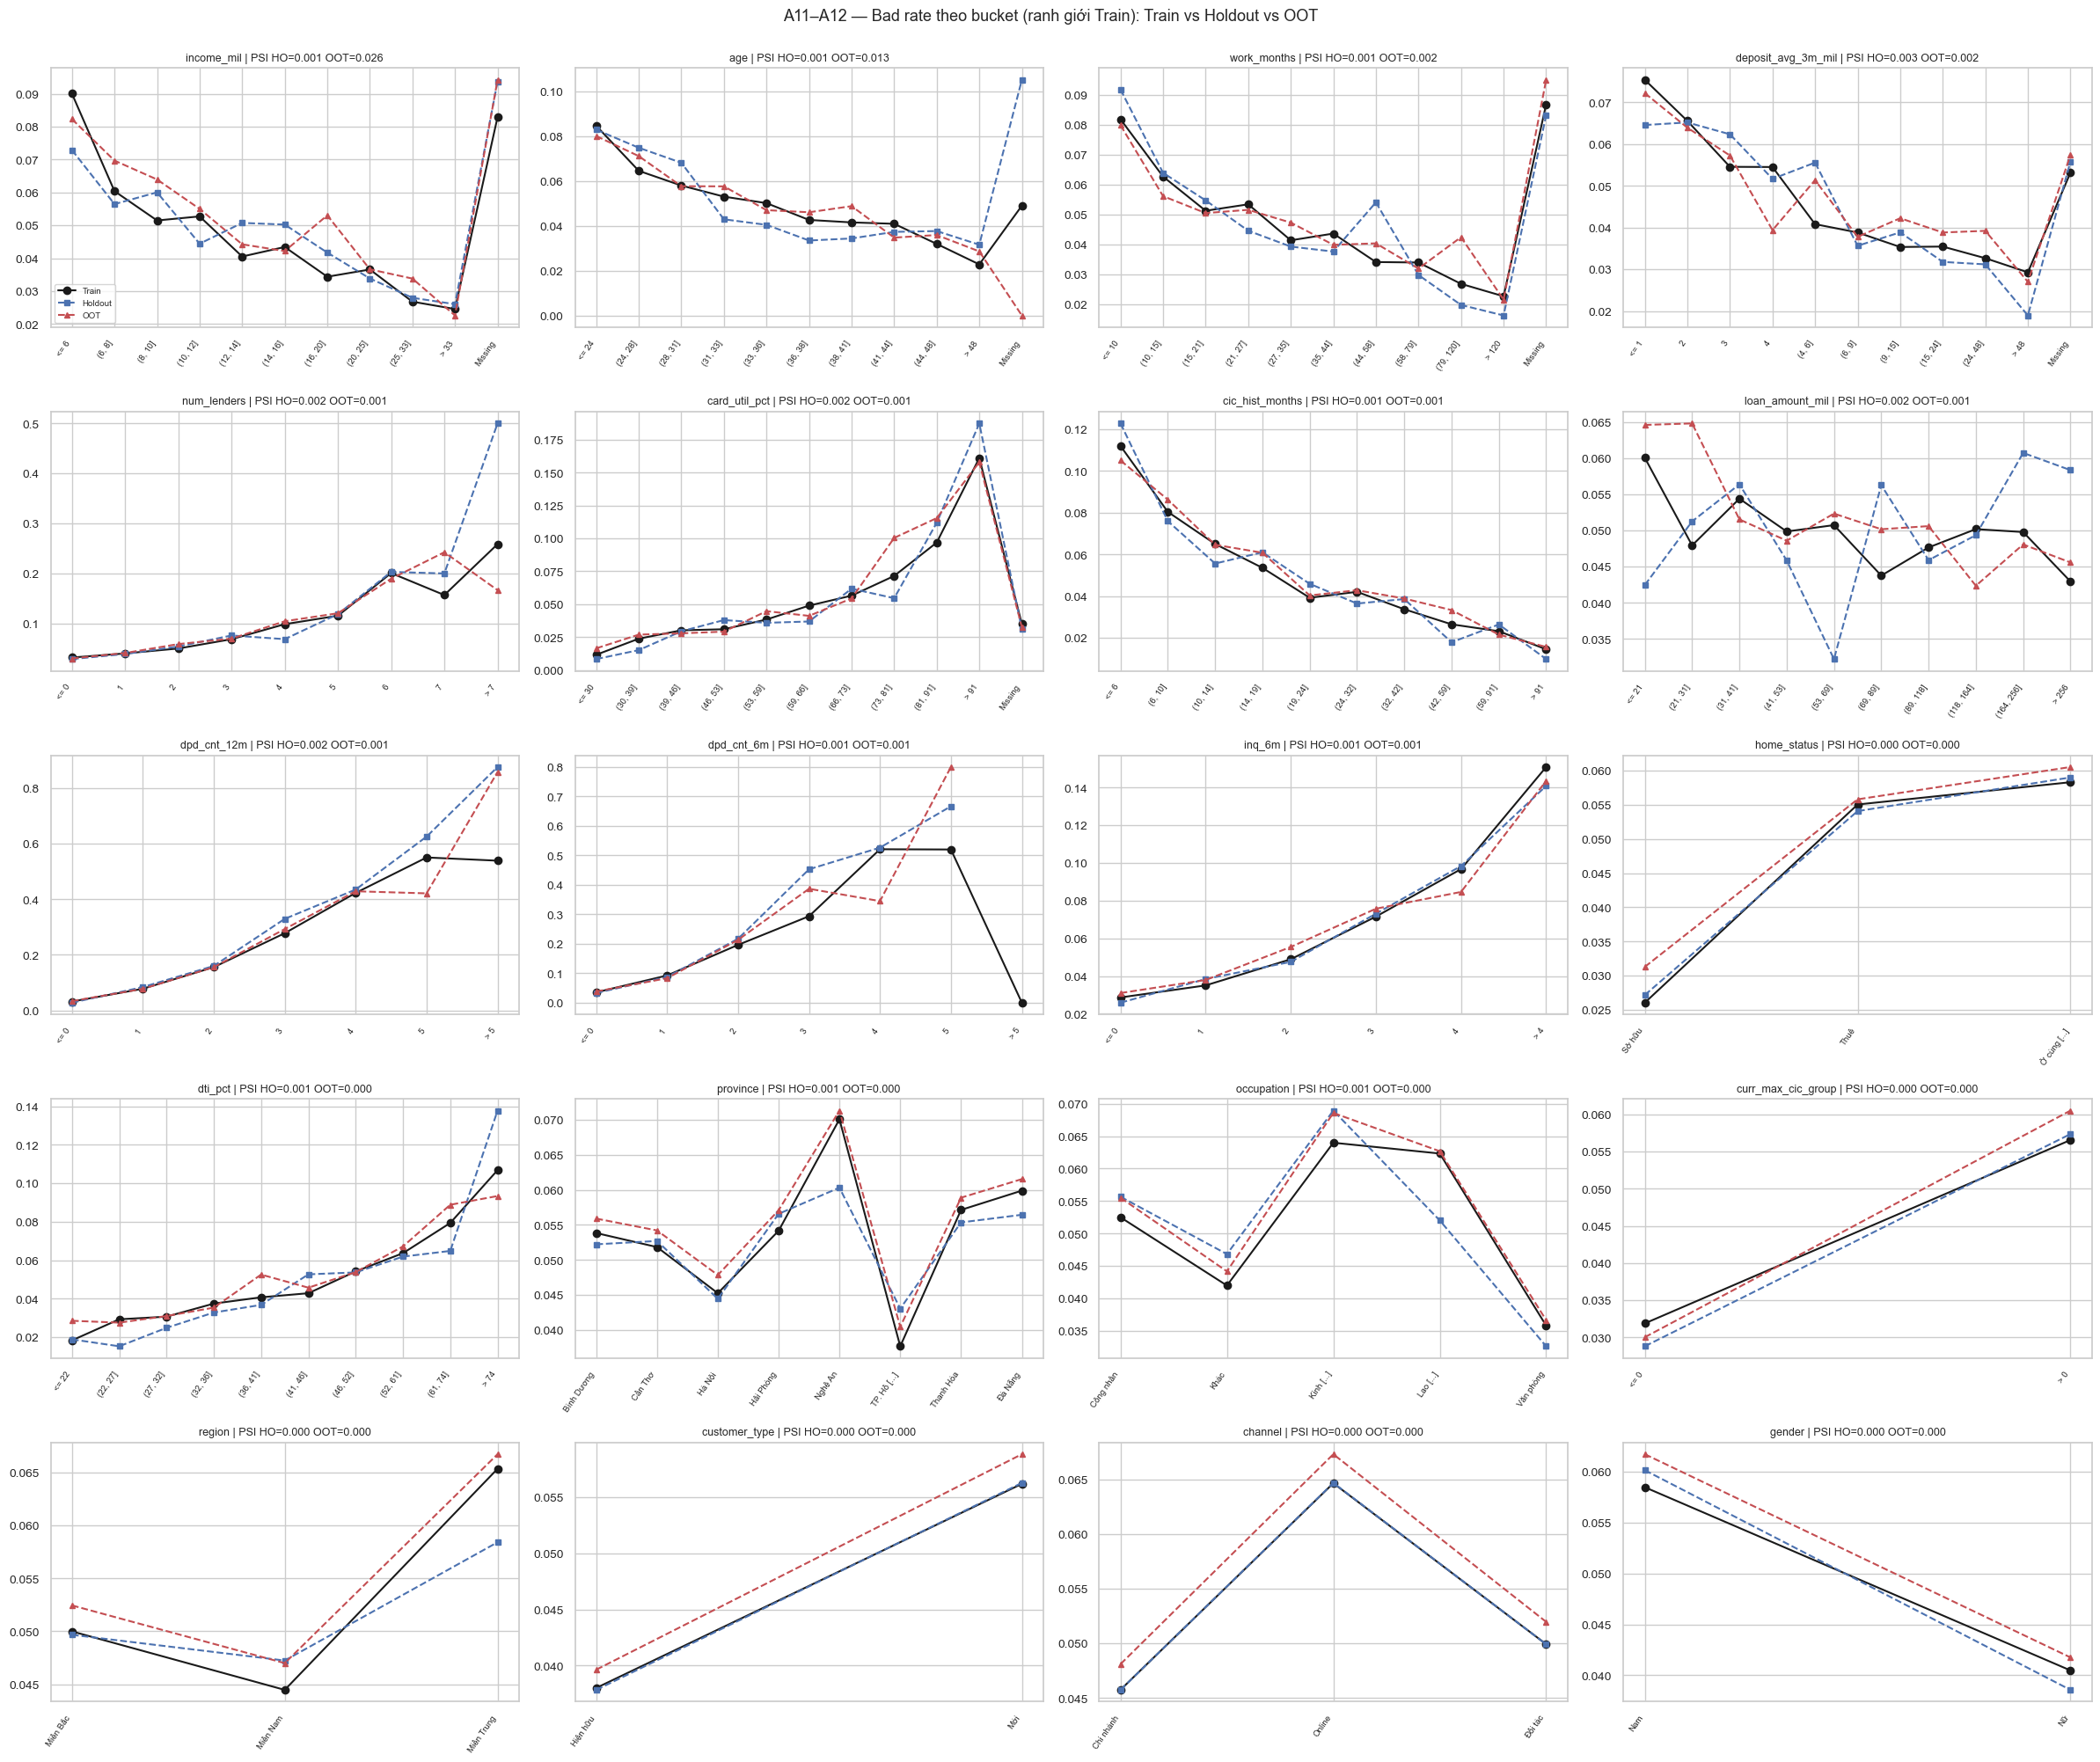

In [78]:
FEATS_OOT = list(KIND)
oot_kgb["target"] = oot_kgb.target.astype(int)
psi_oot, det_oot = psi_report(train, oot_kgb, FEATS_OOT, "OOT")
display(psi_oot)
print(f"Bad rate: Train {train.target.mean():.3%} | Holdout {hold.target.mean():.3%} | OOT {oot_kgb.target.mean():.3%}  (OOT: {len(oot_kgb):,} hồ sơ, {oot_kgb.target.sum()} Bad)")
z = (oot_kgb.target.mean() - train.target.mean()) / np.sqrt(train.target.mean() * (1 - train.target.mean()) / len(oot_kgb))
print(f"Kiểm định Bad rate OOT khác Train: z = {z:.2f}, p = {2*stats.norm.sf(abs(z)):.3f}")

# Bad rate theo bucket: Train vs Holdout vs OOT
fig, axes = plt.subplots(5, 4, figsize=(24, 20)); axes = axes.ravel()
for ax, c in zip(axes, psi_oot.feature):
    h, o = det_ho[c], det_oot[c]; x = np.arange(len(h))
    ax.plot(x, h.BR_Train, "k-o", label="Train"); ax.plot(x, h.BR_Holdout, "b--s", ms=4, label="Holdout")
    o2 = o.set_index("Bucket").reindex(h.Bucket); ax.plot(x, o2.BR_OOT.values, "r--^", ms=4, label="OOT")
    ax.set_xticks(x); ax.set_xticklabels([textwrap.shorten(str(b), 12) for b in h.Bucket], rotation=55, ha="right", fontsize=7)
    ax.set_title(f"{c} | PSI HO={psi_ho.set_index('feature').PSI_Portfolio[c]:.3f} OOT={psi_oot.set_index('feature').PSI_Portfolio[c]:.3f}", fontsize=9)
axes[0].legend(fontsize=7)
for ax in axes[len(psi_oot):]: ax.axis("off")
plt.suptitle("A11–A12 — Bad rate theo bucket (ranh giới Train): Train vs Holdout vs OOT", y=1.0)
plt.tight_layout(); plt.show()

## Khuyến nghị về tính đại diện của bộ Train (câu 3)

**Sampling.** Chia 80/20 stratify theo Good/Bad × Channel × Customer_Type (12 strata, seed = 42): Train 32,101 / Holdout 8,026 hồ sơ; Bad rate **trùng nhau ở 4.984%** (1,600 vs 400 Bad). Chênh lệch tỷ trọng tối đa ở mọi chiều và mọi tổ hợp chỉ **≤ 0.014 điểm %**.

**Train vs Holdout.** PSI Portfolio tối đa 0.0028, PSI Good tối đa 0.0029 — gần bằng 0 cho cả 20 thuộc tính. PSI Bad tối đa 0.063 (dưới 0.10) và nằm trong vùng nhiễu lấy mẫu kỳ vọng (≈ 0.02–0.06 với chỉ 400 Bad / 10 bucket). Bad rate theo bucket chỉ lệch đáng kể ở các bucket đuôi rất nhỏ (VD `dpd_cnt_6m` ở giá trị cao) — là nhiễu do cỡ mẫu. **→ Train đại diện đầy đủ cho Holdout; không cần lấy mẫu lại.**

**Train vs OOT (2024H1).** PSI Portfolio tối đa 0.026 (`income_mil`), PSI Good tối đa 0.026, PSI Bad tối đa 0.051 — tất cả < 0.10. Bad rate OOT 5.21% so với 4.98% của Train (chênh +0.23 điểm %, z ≈ 1.15, p ≈ 0.25 → không khác biệt có ý nghĩa). **→ Danh mục ổn định theo thời gian ở mức thuộc tính; Train dùng được để phát triển và OOT dùng để kiểm định độc lập.**

**Lưu ý/hạn chế:** (1) OOT chỉ có 619 Bad nên PSI Bad/Bad rate theo bucket có nhiễu lớn; (2) cần xác nhận với chủ dữ liệu rằng cửa sổ quan sát của OOT đã đủ trưởng thành (cùng định nghĩa Bad với DEV); (3) dữ liệu OOT không có cột exclusion/indeterminate nên chỉ kiểm định được trên phần KGB.

## A15. Kết luận Phần A — bàn giao

* **Chất lượng dữ liệu:** không trùng hồ sơ. Giá trị bất hợp lý đã xử lý (có cờ): tuổi ngoài 18–70 (138 hồ sơ), thu nhập > 200 triệu (98), DTI > 100% (2,141 — 3.2%), mức sử dụng thẻ > 100% (3,042 — 4.6%). Missing chính: `deposit_avg_3m_mil` 40%, `card_util_pct` 27%, `work_months` 11%, `income_mil` 5% — đều **mang thông tin** nên xử lý ở binning chứ không điền giá trị.
* **Danh mục DEV (66,000):** KGB 40,127 (Good 38,127 / Bad 2,000; Bad rate 4.98%), Indeterminate 6,073, Exclusion 800, Rejected 19,000 (không có performance — ngoài phạm vi, phục vụ reject inference nếu cần). 1,282 hồ sơ Indeterminate có DPD = 0 (tất toán sớm/cơ cấu nợ) cần giữ đúng nhóm.
* **Leakage:** `max_dpd_12m` định nghĩa trực tiếp Bad (AUC = 1.0) và các cột trạng thái chỉ biết sau giải ngân → loại khỏi feature.
* **Segmentation:** không tách theo Channel (chi tiết ở A8).
* **Đại diện:** Train–Holdout–OOT ổn định (chi tiết ở A12).
* **Hạn chế:** chưa có data dictionary chính thức (định nghĩa biến/Bad suy ra từ dữ liệu); kết luận segmentation nên được Business xác nhận.

---
# PHẦN B — Spearman, Binning, WOE/IV & Feature Screening (Người 2 — Hà)
## B1. Feature Eligibility — pháp lý, thời điểm phát sinh, rủi ro target leakage

In [79]:
ELIG_RULES = {
 "app_id": ("Định danh/Thời gian", "Mã định danh, không có nội dung rủi ro"),
 "app_date": ("Định danh/Thời gian", "Ngày nộp: chỉ dùng chia OOT/giám sát, không đưa vào mô hình"),
 "region": ("Trùng lặp", "Suy ra hoàn toàn từ province → trùng thông tin (giữ province, bỏ region)"),
 "gender": ("Pháp lý", "Thuộc tính nhạy cảm — rủi ro phân biệt đối xử; không dùng ra quyết định tín dụng"),
 "decision": ("Leakage/Outcome", "Kết quả quy trình phê duyệt — xảy ra SAU nộp hồ sơ"),
 "perf_class": ("Leakage/Outcome", "Nhãn hiệu quả — là target"),
 "exclusion_reason": ("Leakage/Outcome", "Chỉ biết SAU giải ngân"),
 "indeterminate_reason": ("Leakage/Outcome", "Chỉ biết SAU giải ngân"),
 "max_dpd_12m": ("Leakage/Outcome", "DPD trong cửa sổ quan sát SAU giải ngân; định nghĩa trực tiếp Bad (≥90) → AUC = 1"),
 "target": ("Leakage/Outcome", "Biến mục tiêu"),
}
elig = pd.DataFrame([(v, *ELIG_RULES.get(v, ("Đủ điều kiện", "Có tại thời điểm nộp/trước nộp; không vi phạm pháp lý rõ ràng"))) for v in ALL_RAW_COLS],
                    columns=["variable", "category", "reason"])
elig["eligible"] = elig.category == "Đủ điều kiện"
display(elig)
ELIG_FEATS = elig.loc[elig.eligible, "variable"].tolist()
print(f"{len(ALL_RAW_COLS)} cột → {len(ELIG_FEATS)} feature đủ điều kiện:", ELIG_FEATS)

# Chứng minh leakage của max_dpd_12m & kiểm tra nghi vấn leakage ở các biến còn lại
print("AUC(max_dpd_12m → target) trên KGB =", round(roc_auc_score(kgb.target, kgb.max_dpd_12m), 4), "→ LEAKAGE tuyệt đối")
print("curr_max_cic_group có trùng với cờ (num_lenders>0) không? ", ((kgb.curr_max_cic_group > 0) == (kgb.num_lenders > 0)).all())

,variable,category,reason,eligible
0,app_id,Định danh/Thời gian,"Mã định danh, không có nội dung rủi ro",False
1,app_date,Định danh/Thời gian,"Ngày nộp: chỉ dùng chia OOT/giám sát, không đư...",False
2,channel,Đủ điều kiện,Có tại thời điểm nộp/trước nộp; không vi phạm ...,True
3,customer_type,Đủ điều kiện,Có tại thời điểm nộp/trước nộp; không vi phạm ...,True
4,province,Đủ điều kiện,Có tại thời điểm nộp/trước nộp; không vi phạm ...,True
5,region,Trùng lặp,Suy ra hoàn toàn từ province → trùng thông tin...,False
6,loan_amount_mil,Đủ điều kiện,Có tại thời điểm nộp/trước nộp; không vi phạm ...,True
7,age,Đủ điều kiện,Có tại thời điểm nộp/trước nộp; không vi phạm ...,True
8,gender,Pháp lý,Thuộc tính nhạy cảm — rủi ro phân biệt đối xử;...,False
9,occupation,Đủ điều kiện,Có tại thời điểm nộp/trước nộp; không vi phạm ...,True


28 cột → 18 feature đủ điều kiện: ['channel', 'customer_type', 'province', 'loan_amount_mil', 'age', 'occupation', 'home_status', 'income_mil', 'work_months', 'dti_pct', 'cic_hist_months', 'num_lenders', 'card_util_pct', 'inq_6m', 'dpd_cnt_6m', 'dpd_cnt_12m', 'deposit_avg_3m_mil', 'curr_max_cic_group']
AUC(max_dpd_12m → target) trên KGB = 1.0 → LEAKAGE tuyệt đối
curr_max_cic_group có trùng với cờ (num_lenders>0) không?  True


**Kiểm tra chất lượng dữ liệu trước khi sàng lọc** (loại nếu missing > 60% hoặc một giá trị chiếm > 98%):

In [80]:
KIND = {c: ("num" if c in NUM_FEATS else "cat") for c in ELIG_FEATS}
dqg = pd.DataFrame({"missing_train": train[ELIG_FEATS].isna().mean(), "missing_oot": oot_kgb[ELIG_FEATS].isna().mean(),
                    "top_value_share": [train[c].value_counts(normalize=True).iloc[0] for c in ELIG_FEATS]}, index=ELIG_FEATS)
dqg["fail_quality"] = (dqg.missing_train > DQ_MAX_MISSING) | (dqg.top_value_share > DQ_MAX_SINGLE)
display(dqg); print("Số biến bị loại vì chất lượng:", int(dqg.fail_quality.sum()))
DQ_DROP = dqg.index[dqg.fail_quality].tolist()
CAND0 = [c for c in ELIG_FEATS if c not in DQ_DROP]

,missing_train,missing_oot,top_value_share,fail_quality
channel,0.0000,0.0000,0.5501,False
customer_type,0.0000,0.0000,0.6508,False
province,0.0000,0.0000,0.2495,False
loan_amount_mil,0.0000,0.0000,0.0734,False
age,0.0032,0.0001,0.0415,False
occupation,0.0000,0.0000,0.3497,False
home_status,0.0000,0.0000,0.5225,False
income_mil,0.0451,0.0411,0.0596,False
work_months,0.1030,0.1065,0.0258,False
dti_pct,0.0000,0.0000,0.0271,False


Số biến bị loại vì chất lượng: 0


## B2. Raw Spearman Correlation (Train, biến số thô) — ngưỡng |ρ| > 0.70

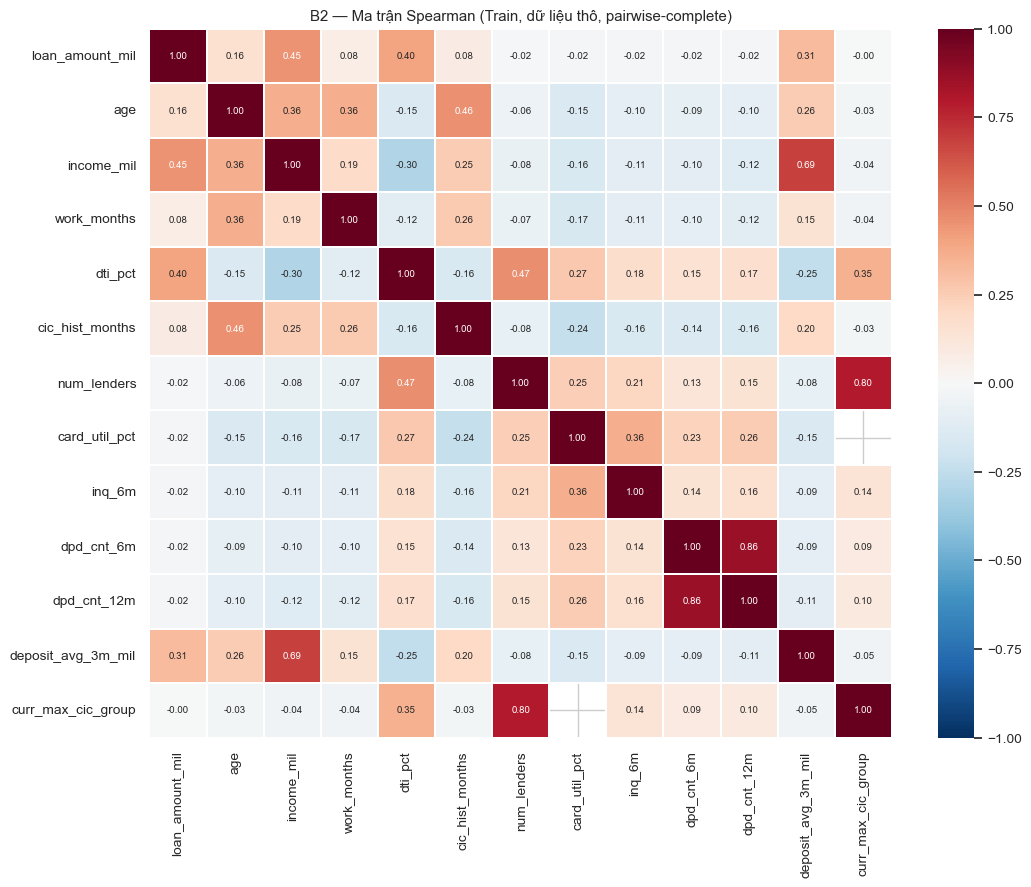

Cặp |ρ| > 0.7 :


,var_1,var_2,spearman
0,num_lenders,curr_max_cic_group,0.7965
1,dpd_cnt_6m,dpd_cnt_12m,0.8640


Cặp cần theo dõi (0.60 < |ρ| ≤ 0.70):


,var_1,var_2,spearman
0,income_mil,deposit_avg_3m_mil,0.6853


In [81]:
NUM_C = [c for c in CAND0 if KIND[c] == "num"]
rho = train[NUM_C].corr(method="spearman")
plt.figure(figsize=(11, 9)); sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7}, linewidths=.3)
plt.title("B2 — Ma trận Spearman (Train, dữ liệu thô, pairwise-complete)"); plt.tight_layout(); plt.show()
pairs = [(a, b, rho.loc[a, b]) for a, b in itertools.combinations(NUM_C, 2) if abs(rho.loc[a, b]) > RAW_SPEARMAN_CUT]
watch = [(a, b, rho.loc[a, b]) for a, b in itertools.combinations(NUM_C, 2) if 0.6 < abs(rho.loc[a, b]) <= RAW_SPEARMAN_CUT]
print("Cặp |ρ| >", RAW_SPEARMAN_CUT, ":"); display(pd.DataFrame(pairs, columns=["var_1", "var_2", "spearman"]))
print("Cặp cần theo dõi (0.60 < |ρ| ≤ 0.70):"); display(pd.DataFrame(watch, columns=["var_1", "var_2", "spearman"]))

## B3. Raw Feature Selection — chọn giữ/loại từ các cụm tương quan cao
Tiêu chí (theo thứ tự): **IV sơ bộ (Train)** → missing → độ ổn định (PSI Train–OOT) → business sense. Mỗi cụm chỉ giữ 1 đại diện.

In [82]:
iv_tr = pd.Series({c: decile_table(train, c, KIND[c]).IV.sum() for c in CAND0})
psi_oot_ix = psi_oot.set_index("feature").PSI_Portfolio
def components(pairs):
    adj = {}
    for a, b, _ in pairs: adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
    seen, comps = set(), []
    for n in adj:
        if n in seen: continue
        st, comp = [n], set()
        while st:
            x = st.pop()
            if x in comp: continue
            comp.add(x); st.extend(adj[x] - comp)
        seen |= comp; comps.append(sorted(comp))
    return comps
BUS = {frozenset(["num_lenders", "curr_max_cic_group"]): "curr_max_cic_group trong KGB chỉ nhận 0/1 và đúng bằng cờ 'num_lenders > 0' → là thông tin con của num_lenders.",
       frozenset(["dpd_cnt_6m", "dpd_cnt_12m"]): "Cửa sổ 12 tháng bao trùm cửa sổ 6 tháng (ρ≈0.87) → cùng một hành vi trễ hạn ở 2 độ dài."}
raw_rows, RAW_DROP = [], {}
for comp in components(pairs):
    ordered = sorted(comp, key=lambda c: (-round(iv_tr[c], 3), train[c].isna().mean(), psi_oot_ix.get(c, 0)))
    keep = ordered[0]
    for c in ordered:
        other = [o for o in comp if o != c]; r_ = max(abs(rho.loc[c, o]) for o in other)
        txt = BUS.get(frozenset(comp), "")
        if c == keep:
            raw_rows.append(dict(cluster="+".join(comp), variable=c, decision="GIỮ", IV_train=iv_tr[c], missing=train[c].isna().mean(), PSI_OOT=psi_oot_ix.get(c), max_abs_rho=r_,
                                 reason=f"IV cao nhất cụm ({iv_tr[c]:.3f}). {txt}"))
        else:
            RAW_DROP[c] = f"|ρ|={r_:.2f} với {keep}; IV thấp hơn ({iv_tr[c]:.3f} vs {iv_tr[keep]:.3f}). {txt}"
            raw_rows.append(dict(cluster="+".join(comp), variable=c, decision="LOẠI", IV_train=iv_tr[c], missing=train[c].isna().mean(), PSI_OOT=psi_oot_ix.get(c), max_abs_rho=r_, reason=RAW_DROP[c]))
raw_screen = pd.DataFrame(raw_rows); display(raw_screen)
CAND1 = [c for c in CAND0 if c not in RAW_DROP]
print("Còn lại sau Spearman thô:", len(CAND1), "biến →", CAND1)

,cluster,variable,decision,IV_train,missing,PSI_OOT,max_abs_rho,reason
0,curr_max_cic_group+num_lenders,num_lenders,GIỮ,0.2072,0.0000,0.0011,0.7965,IV cao nhất cụm (0.207). curr_max_cic_group tr...
1,curr_max_cic_group+num_lenders,curr_max_cic_group,LOẠI,0.0619,0.0000,0.0000,0.7965,|ρ|=0.80 với num_lenders; IV thấp hơn (0.062 v...
2,dpd_cnt_12m+dpd_cnt_6m,dpd_cnt_12m,GIỮ,0.5215,0.0000,0.0007,0.8640,IV cao nhất cụm (0.521). Cửa sổ 12 tháng bao t...
3,dpd_cnt_12m+dpd_cnt_6m,dpd_cnt_6m,LOẠI,0.4324,0.0000,0.0006,0.8640,|ρ|=0.86 với dpd_cnt_12m; IV thấp hơn (0.432 v...


Còn lại sau Spearman thô: 16 biến → ['channel', 'customer_type', 'province', 'loan_amount_mil', 'age', 'occupation', 'home_status', 'income_mil', 'work_months', 'dti_pct', 'cic_hist_months', 'num_lenders', 'card_util_pct', 'inq_6m', 'dpd_cnt_12m', 'deposit_avg_3m_mil']


## B4–B8. Binning: 20 bin ban đầu → gộp có kiểm soát (≥5%/bin, đơn điệu theo logic kinh doanh, ý nghĩa thống kê), xử lý missing, WOE/IV

**Quy trình gộp (áp dụng đồng nhất, mọi bước đều được ghi lại cùng IV trước/sau):**
0. *Missing* < 5% mẫu → không đủ làm bin riêng → gộp vào bin có Bad rate gần nhất.
1. Bin < 5% mẫu Train → gộp với bin kề làm **mất ít IV nhất**.
2. Biến số có **chiều kinh doanh kỳ vọng** (bảng dưới): gộp các cặp kề đảo chiều Bad rate cho đến khi đơn điệu.
3. Gộp 2 bin kề khi Bad rate **không khác biệt có ý nghĩa** (χ², p > 0.05) → bin cuối bền vững, tránh over-fit.
4. *Missing* ≥ 5%: luôn giữ **bin riêng** — missing là một trạng thái có nghĩa kinh doanh (không có thẻ, không có tài khoản tiền gửi, không khai báo thu nhập/thời gian làm việc), Bad rate của nó có thể khác mọi bin số; giữ riêng giúp diễn giải và giám sát dịch chuyển tỷ lệ missing.

Biến phân loại: ban đầu mỗi category là 1 bin, **xếp theo Bad rate** rồi áp dụng bước 1, 3 (không ép chiều). Category lạ ở OOT → `UNSEEN`, WOE = 0 (trung tính).

In [83]:
DIRECTION = {"loan_amount_mil": "inc", "age": "dec", "income_mil": "dec", "work_months": "dec", "dti_pct": "inc", "cic_hist_months": "dec",
             "num_lenders": "inc", "card_util_pct": "inc", "inq_6m": "inc", "dpd_cnt_6m": "inc", "dpd_cnt_12m": "inc",
             "deposit_avg_3m_mil": "dec", "curr_max_cic_group": "inc"}
DIRECTION.update({c: "free" for c in CAND1 if KIND[c] == "cat"})
dir_tab = pd.DataFrame({"variable": CAND1, "kind": [KIND[c] for c in CAND1], "expected_direction": [DIRECTION[c] for c in CAND1],
                        "business_logic": [{"inc": "Giá trị càng cao → rủi ro càng cao", "dec": "Giá trị càng cao → rủi ro càng thấp", "free": "Biến phân loại — không ép chiều, kiểm tra tính hợp lý của từng nhóm"}[DIRECTION[c]] for c in CAND1]})
display(dir_tab)

BIN, HIST, STAGES = {}, {}, {}
for c in CAND1:
    BIN[c], HIST[c], STAGES[c] = build_binning(train, c, KIND[c], DIRECTION[c])
init_tab = pd.concat({c: STAGES[c]["0_initial"] for c in CAND1}, names=["variable"]).reset_index(level=0)
print("Ví dụ bảng binning ban đầu — dti_pct (20 bin):"); display(STAGES["dti_pct"]["0_initial"])

,variable,kind,expected_direction,business_logic
0,channel,cat,free,"Biến phân loại — không ép chiều, kiểm tra tính..."
1,customer_type,cat,free,"Biến phân loại — không ép chiều, kiểm tra tính..."
2,province,cat,free,"Biến phân loại — không ép chiều, kiểm tra tính..."
3,loan_amount_mil,num,inc,Giá trị càng cao → rủi ro càng cao
4,age,num,dec,Giá trị càng cao → rủi ro càng thấp
5,occupation,cat,free,"Biến phân loại — không ép chiều, kiểm tra tính..."
6,home_status,cat,free,"Biến phân loại — không ép chiều, kiểm tra tính..."
7,income_mil,num,dec,Giá trị càng cao → rủi ro càng thấp
8,work_months,num,dec,Giá trị càng cao → rủi ro càng thấp
9,dti_pct,num,inc,Giá trị càng cao → rủi ro càng cao


Ví dụ bảng binning ban đầu — dti_pct (20 bin):


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 18,1876,31,1907,0.0594,0.0163,0.0615,0.0194,1.1552,0.0487
1,"(18, 22]",1729,36,1765,0.0550,0.0204,0.0567,0.0225,0.9240,0.0316
2,"(22, 25]",1640,41,1681,0.0524,0.0244,0.0538,0.0256,0.7411,0.0209
3,"(25, 27]",1282,47,1329,0.0414,0.0354,0.0420,0.0294,0.3583,0.0045
4,"(27, 30]",1957,58,2015,0.0628,0.0288,0.0642,0.0362,0.5710,0.0159
5,"(30, 32]",1368,47,1415,0.0441,0.0332,0.0449,0.0294,0.4232,0.0065
6,"(32, 34]",1393,59,1452,0.0452,0.0406,0.0457,0.0369,0.2139,0.0019
7,"(34, 36]",1334,47,1381,0.0430,0.0340,0.0437,0.0294,0.3980,0.0057
8,"(36, 39]",1955,85,2040,0.0635,0.0417,0.0641,0.0531,0.1877,0.0021
9,"(39, 41]",1252,51,1303,0.0406,0.0391,0.0410,0.0319,0.2529,0.0023


### B5. Missing Treatment — phân tích missing và Bad rate

In [84]:
mrows = []
for c in CAND1:
    m = train[c].isna()
    if not m.any(): continue
    b1, n1, b0, n0 = train.target[m].sum(), m.sum(), train.target[~m].sum(), (~m).sum()
    p = stats.chi2_contingency([[b1, n1 - b1], [b0, n0 - b0]], correction=False)[1]
    mrows.append(dict(variable=c, pct_missing=m.mean(), BadRate_missing=b1 / n1, BadRate_nonmissing=b0 / n0, p_value=p,
                      rule=BIN[c].spec()["missing_rule"], meaning={"card_util_pct": "Thiếu ≈ không có thẻ tín dụng (ít rủi ro hơn)", "deposit_avg_3m_mil": "Thiếu ≈ không có tài khoản tiền gửi",
                      "income_mil": "Không khai báo thu nhập (rủi ro cao hơn)", "work_months": "Không khai báo thời gian làm việc (rủi ro cao hơn)", "age": "Tuổi không hợp lệ đã đưa về missing (rất ít)"}.get(c, "")))
miss_rules = pd.DataFrame(mrows); display(miss_rules)

,variable,pct_missing,BadRate_missing,BadRate_nonmissing,p_value,rule,meaning
0,age,0.0032,0.0490,0.0498,0.9695,"gộp vào bin '(29, 37] (+Missing)'",Tuổi không hợp lệ đã đưa về missing (rất ít)
1,income_mil,0.0451,0.0829,0.0483,0.0000,gộp vào bin '<= 6 (+Missing)',Không khai báo thu nhập (rủi ro cao hơn)
2,work_months,0.1030,0.0868,0.0456,0.0000,bin riêng,Không khai báo thời gian làm việc (rủi ro cao ...
3,card_util_pct,0.3063,0.0350,0.0564,0.0000,bin riêng,Thiếu ≈ không có thẻ tín dụng (ít rủi ro hơn)
4,deposit_avg_3m_mil,0.3821,0.0532,0.0478,0.0322,bin riêng,Thiếu ≈ không có tài khoản tiền gửi


### B6–B7. Final Binning Table & tổng hợp WOE/IV

In [85]:
final_tab = pd.concat({c: STAGES[c]["4_final"] for c in CAND1}, names=["variable"]).reset_index(level=0)
iv_stage = pd.DataFrame({s: {c: STAGES[c][s].IV.sum() for c in CAND1} for s in ["0_initial", "1_after_min5pct", "2_after_monotone", "3_after_chi", "4_final"]})
iv_stage.columns = ["IV (20 bin)", "IV sau gộp <5%", "IV sau đơn điệu", "IV sau chi-merge", "IV cuối"]
woe_iv_sum = pd.DataFrame({"n_bins_init": {c: len(STAGES[c]["0_initial"]) for c in CAND1}, "n_bins_final": {c: len(STAGES[c]["4_final"]) for c in CAND1},
                           "min_bin_share": {c: STAGES[c]["4_final"]["%Total"].min() for c in CAND1}}).join(iv_stage)
woe_iv_sum["IV_giữ_lại_%"] = woe_iv_sum["IV cuối"] / woe_iv_sum["IV (20 bin)"]
woe_iv_sum = woe_iv_sum.sort_values("IV cuối", ascending=False); display(woe_iv_sum)
assert (woe_iv_sum.min_bin_share >= MIN_BIN_SHARE - 1e-9).all(), "Có bin < 5%"
print("Bảng cuối (ví dụ 3 biến): "); 
for c in ["dti_pct", "card_util_pct", "home_status"]: print("\n>>", c); display(STAGES[c]["4_final"])

,n_bins_init,n_bins_final,min_bin_share,IV (20 bin),IV sau gộp <5%,IV sau đơn điệu,IV sau chi-merge,IV cuối,IV_giữ_lại_%
dpd_cnt_12m,7,3,0.0553,0.5215,0.4765,0.4765,0.4765,0.4765,0.9138
card_util_pct,21,8,0.0669,0.4704,0.4568,0.4568,0.4546,0.4546,0.9665
cic_hist_months,20,7,0.0621,0.3733,0.3697,0.3691,0.3665,0.3665,0.9818
inq_6m,13,6,0.0520,0.3267,0.3012,0.3012,0.3012,0.3012,0.9219
dti_pct,20,5,0.1328,0.2902,0.2802,0.2798,0.2731,0.2731,0.9412
num_lenders,9,5,0.0846,0.2072,0.1924,0.1924,0.1924,0.1924,0.9284
work_months,21,6,0.1030,0.1968,0.1879,0.1879,0.1862,0.1862,0.9459
income_mil,20,5,0.1085,0.1995,0.1865,0.1842,0.1804,0.1804,0.9041
age,21,5,0.0645,0.1383,0.1286,0.1286,0.1280,0.1280,0.9258
home_status,3,2,0.2092,0.0847,0.0847,0.0847,0.0840,0.0840,0.9917


Bảng cuối (ví dụ 3 biến): 

>> dti_pct


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 25,5245,108,5353,0.1668,0.0202,0.1720,0.0675,0.9351,0.0977
1,"(25, 44]",12420,465,12885,0.4014,0.0361,0.4072,0.2906,0.3373,0.0393
2,"(44, 52]",4034,230,4264,0.1328,0.0539,0.1323,0.1437,-0.0833,0.0010
3,"(52, 66]",4472,314,4786,0.1491,0.0656,0.1466,0.1963,-0.2916,0.0145
4,> 66,4330,483,4813,0.1499,0.1004,0.1420,0.3019,-0.7544,0.1206



>> card_util_pct


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 30,2393,28,2421,0.0754,0.0116,0.0785,0.0175,1.5003,0.0915
1,"(30, 43]",3341,86,3427,0.1068,0.0251,0.1095,0.0537,0.7119,0.0397
2,"(43, 59]",5108,181,5289,0.1648,0.0342,0.1675,0.1131,0.3923,0.0213
3,"(59, 73]",4216,234,4450,0.1386,0.0526,0.1382,0.1462,-0.0564,0.0005
4,"(73, 81]",2118,163,2281,0.0711,0.0715,0.0694,0.1019,-0.3833,0.0124
5,"(81, 91]",2033,218,2251,0.0701,0.0968,0.0667,0.1363,-0.7150,0.0498
6,> 91,1802,346,2148,0.0669,0.1611,0.0591,0.2162,-1.2975,0.2039
7,Missing,9490,344,9834,0.3063,0.0350,0.3111,0.2150,0.3696,0.0355



>> home_status


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,Sở hữu,6542,175,6717,0.2092,0.0261,0.2145,0.1094,0.6735,0.0708
1,Thuê | Ở cùng gia đình,23959,1425,25384,0.7908,0.0561,0.7855,0.8906,-0.1256,0.0132


### B8. Merge History — WOE & IV trước/sau mỗi lần gộp (3 biến chính)
Chọn `dti_pct` (biến số, không missing, top IV), `card_util_pct` (top IV, **missing 30%** → kiểm tra bin Missing) và `income_mil` (missing ~4–5%, kiểm tra quy tắc gộp missing).


dti_pct — lịch sử gộp (15 bước)


,step,merged,n_bins,IV_before,IV_after,reason,IV_loss
0,1_min_size,"(44, 46] + (46, 49]",19,0.2902,0.2901,"bin '(44, 46]' chỉ 3.7% < 5%",0.0000
1,1_min_size,"(36, 39] + (39, 41]",18,0.2901,0.2900,"bin '(39, 41]' chỉ 4.1% < 5%",0.0001
2,1_min_size,"(25, 27] + (27, 30]",17,0.2900,0.2891,"bin '(25, 27]' chỉ 4.1% < 5%",0.0009
3,1_min_size,"(32, 34] + (34, 36]",16,0.2891,0.2884,"bin '(34, 36]' chỉ 4.3% < 5%",0.0007
4,1_min_size,"(56, 61] + (61, 66]",15,0.2884,0.2882,"bin '(61, 66]' chỉ 4.4% < 5%",0.0003
5,1_min_size,"(25, 30] + (30, 32]",14,0.2882,0.2881,"bin '(30, 32]' chỉ 4.4% < 5%",0.0001
6,1_min_size,"(44, 49] + (49, 52]",13,0.2881,0.2878,"bin '(49, 52]' chỉ 4.5% < 5%",0.0003
7,1_min_size,"(74, 88] + > 88",12,0.2878,0.2826,bin '> 88' chỉ 4.8% < 5%,0.0052
8,1_min_size,"(66, 74] + > 74",11,0.2826,0.2802,"bin '(66, 74]' chỉ 5.0% < 5%",0.0024
9,2_monotone,"(36, 41] + (41, 44]",10,0.2802,0.2798,đảo chiều Bad rate (kỳ vọng tăng),0.0005


-- Bảng WOE/IV tại giai đoạn 0_initial  (IV = 0.2902)


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 18,1876,31,1907,0.0594,0.0163,0.0615,0.0194,1.1552,0.0487
1,"(18, 22]",1729,36,1765,0.0550,0.0204,0.0567,0.0225,0.9240,0.0316
2,"(22, 25]",1640,41,1681,0.0524,0.0244,0.0538,0.0256,0.7411,0.0209
3,"(25, 27]",1282,47,1329,0.0414,0.0354,0.0420,0.0294,0.3583,0.0045
4,"(27, 30]",1957,58,2015,0.0628,0.0288,0.0642,0.0362,0.5710,0.0159
5,"(30, 32]",1368,47,1415,0.0441,0.0332,0.0449,0.0294,0.4232,0.0065
6,"(32, 34]",1393,59,1452,0.0452,0.0406,0.0457,0.0369,0.2139,0.0019
7,"(34, 36]",1334,47,1381,0.0430,0.0340,0.0437,0.0294,0.3980,0.0057
8,"(36, 39]",1955,85,2040,0.0635,0.0417,0.0641,0.0531,0.1877,0.0021
9,"(39, 41]",1252,51,1303,0.0406,0.0391,0.0410,0.0319,0.2529,0.0023


-- Bảng WOE/IV tại giai đoạn 2_after_monotone  (IV = 0.2798)


...

,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 5,2512,265,2777,0.0865,0.0954,0.0824,0.1656,-0.6987,0.0582
1,6,1418,124,1542,0.0480,0.0804,0.0465,0.0775,-0.5110,0.0158
2,7,886,49,935,0.0291,0.0524,0.0290,0.0306,-0.0529,0.0001
3,8,1634,113,1747,0.0544,0.0647,0.0536,0.0706,-0.2764,0.0047
4,9,1742,84,1826,0.0569,0.0460,0.0571,0.0525,0.0842,0.0004
5,10,1666,101,1767,0.0550,0.0572,0.0546,0.0631,-0.1447,0.0012
6,11,1586,81,1667,0.0519,0.0486,0.0520,0.0506,0.0268,0.0000
7,12,1540,93,1633,0.0509,0.0570,0.0505,0.0581,-0.1408,0.0011
8,"(12, 14]",2036,86,2122,0.0661,0.0405,0.0668,0.0537,0.2166,0.0028
9,15,1295,65,1360,0.0424,0.0478,0.0425,0.0406,0.0441,0.0001


-- Bảng WOE/IV tại giai đoạn 2_after_monotone  (IV = 0.1842)


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 5,2512,265,2777,0.0865,0.0954,0.0824,0.1656,-0.6987,0.0582
1,6 (+Missing),2745,244,2989,0.0931,0.0816,0.0900,0.1525,-0.5274,0.0330
2,"(6, 8]",2520,162,2682,0.0835,0.0604,0.0826,0.1013,-0.2033,0.0038
3,"(8, 12]",6534,359,6893,0.2147,0.0521,0.2142,0.2244,-0.0463,0.0005
4,"(12, 15]",3331,151,3482,0.1085,0.0434,0.1092,0.0944,0.1460,0.0022
5,"(15, 18]",2700,103,2803,0.0873,0.0367,0.0885,0.0644,0.3185,0.0077
6,"(18, 22]",3314,122,3436,0.1070,0.0355,0.1087,0.0762,0.3541,0.0115
7,"(22, 28]",2422,83,2505,0.0780,0.0331,0.0794,0.0519,0.4258,0.0117
8,> 28,4423,111,4534,0.1412,0.0245,0.1450,0.0694,0.7373,0.0558


-- Bảng WOE/IV tại giai đoạn 4_final  (IV = 0.1804)


,Bin,Good,Bad,Total,%Total,BadRate,%Good,%Bad,WOE,IV
0,<= 6 (+Missing),5257,509,5766,0.1796,0.0883,0.1724,0.3181,-0.6129,0.0893
1,"(6, 12]",9054,521,9575,0.2983,0.0544,0.2968,0.3256,-0.0925,0.0027
2,"(12, 15]",3331,151,3482,0.1085,0.0434,0.1092,0.0944,0.1460,0.0022
3,"(15, 28]",8436,308,8744,0.2724,0.0352,0.2766,0.1925,0.3624,0.0305
4,> 28,4423,111,4534,0.1412,0.0245,0.1450,0.0694,0.7373,0.0558


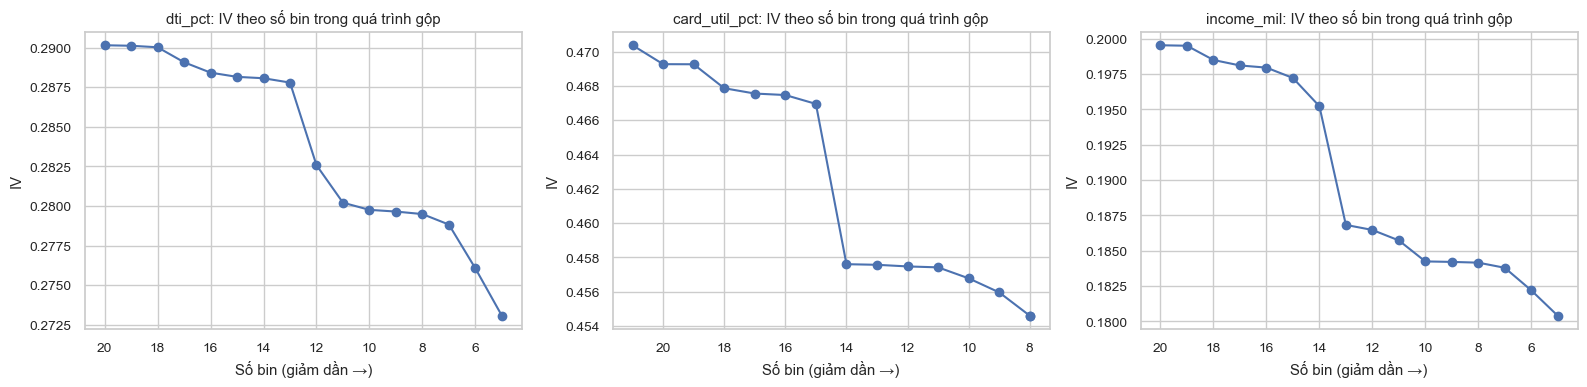

In [86]:
KEY_VARS = ["dti_pct", "card_util_pct", "income_mil"]
for c in KEY_VARS:
    print(f"\n{c} — lịch sử gộp ({len(HIST[c])} bước)"); display(HIST[c].assign(IV_loss=lambda d: d.IV_before - d.IV_after))
    for stg in ["0_initial", "2_after_monotone", "4_final"]:
        print(f"-- Bảng WOE/IV tại giai đoạn {stg}  (IV = {STAGES[c][stg].IV.sum():.4f})"); display(STAGES[c][stg])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, KEY_VARS):
    h = HIST[c]; xs = [len(STAGES[c]["0_initial"])] + h.n_bins.tolist(); ys = [STAGES[c]["0_initial"].IV.sum()] + h.IV_after.tolist()
    ax.plot(xs, ys, "o-"); ax.invert_xaxis(); ax.set_title(f"{c}: IV theo số bin trong quá trình gộp"); ax.set_xlabel("Số bin (giảm dần →)"); ax.set_ylabel("IV")
plt.tight_layout(); plt.show()

## B9. Rank-ordering, chiều WOE (Train + đối chiếu OOT)

,n_groups,expected,rho_train,rho_holdout,rho_oot,violations_train,violations_oot,woe_direction_ok,rank_oot_ok
variable,,,,,,,,,
channel,2,free,NaN,NaN,NaN,0,0,True,True
customer_type,2,free,NaN,NaN,NaN,0,0,True,True
province,4,free,1.0000,1.0000,1.0000,0,0,True,True
loan_amount_mil,1,inc,NaN,NaN,NaN,0,0,True,True
age,5,dec,-1.0000,-1.0000,-1.0000,0,0,True,True
occupation,3,free,1.0000,1.0000,1.0000,0,0,True,True
home_status,2,free,NaN,NaN,NaN,0,0,True,True
income_mil,5,dec,-1.0000,-1.0000,-1.0000,0,0,True,True
work_months,5,dec,-1.0000,-0.9000,-1.0000,0,0,True,True


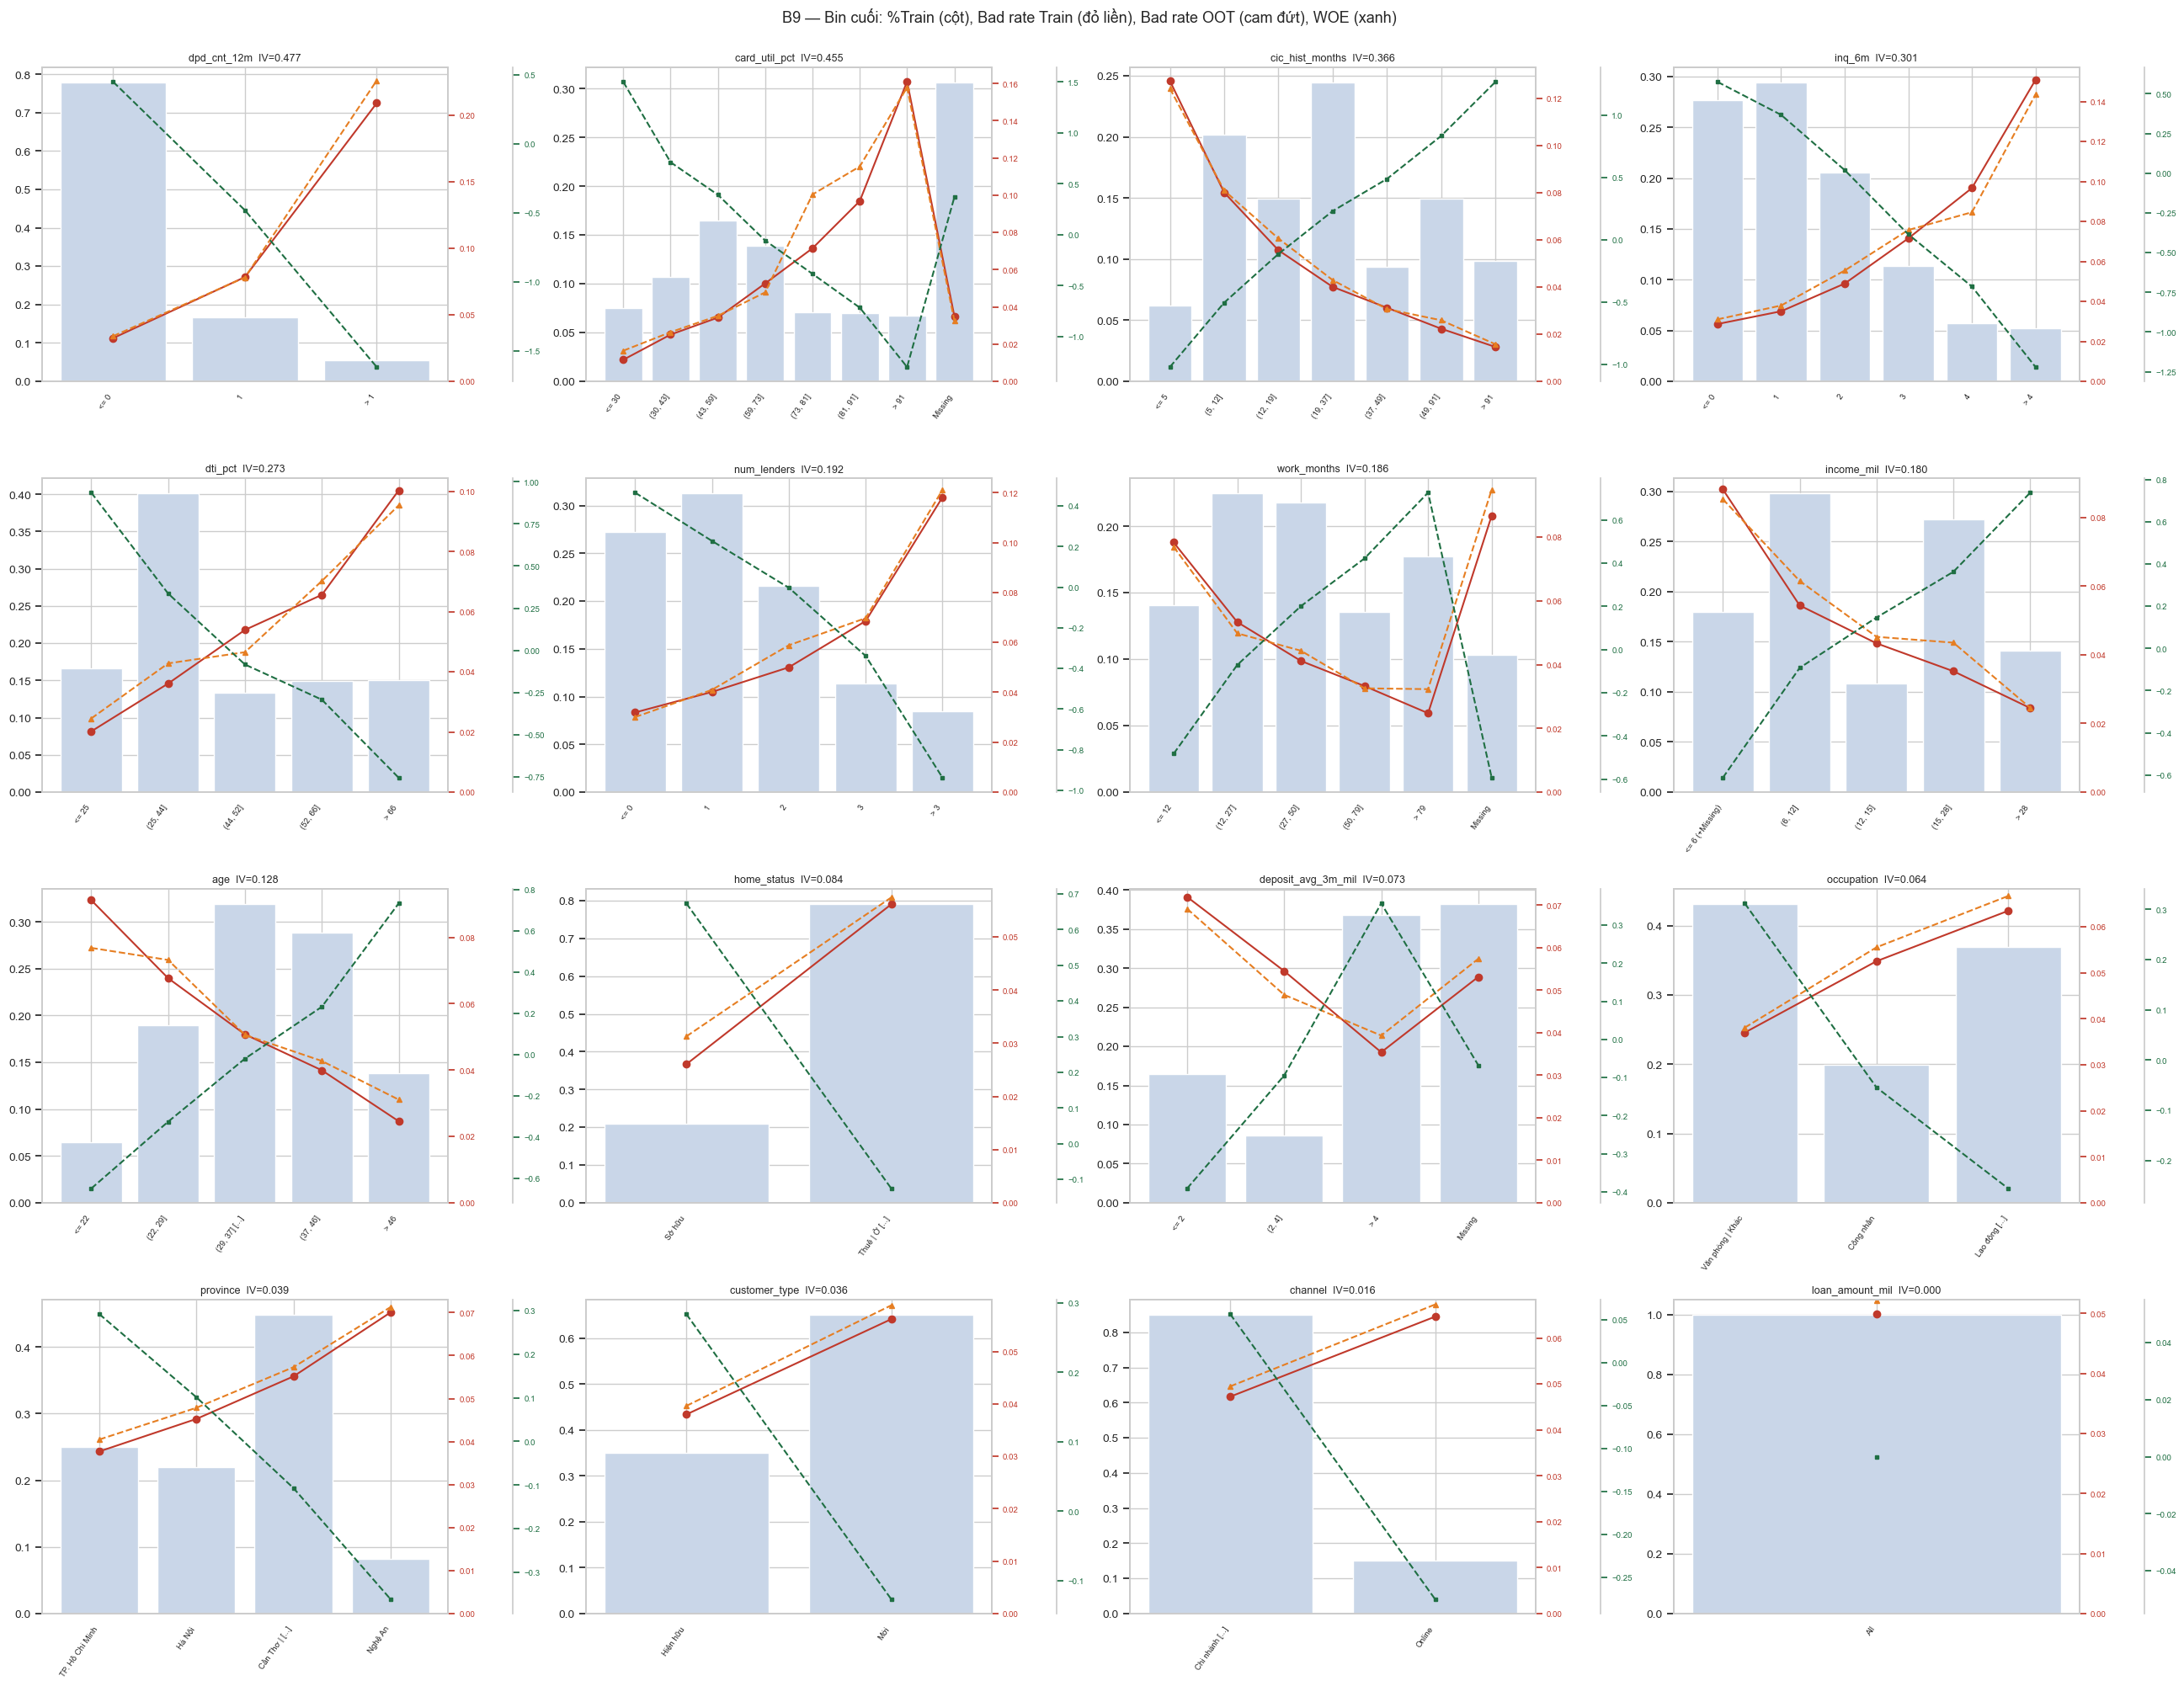

WOE theo nhóm của biến phân loại (kiểm tra business sense):

>> channel


,Bin,Total,%Total,BadRate,WOE
0,Chi nhánh | Đối tác,27275,0.8497,0.0472,0.0567
1,Online,4826,0.1503,0.0646,-0.2758



>> customer_type


,Bin,Total,%Total,BadRate,WOE
0,Hiện hữu,11210,0.3492,0.0380,0.2836
1,Mới,20891,0.6508,0.0562,-0.1267



>> province


,Bin,Total,%Total,BadRate,WOE
0,TP. Hồ Chí Minh,8010,0.2495,0.0377,0.2918
1,Hà Nội,7070,0.2202,0.0453,0.1012
2,Cần Thơ | Bình Dương | Hải Phòng | Thanh Hóa |...,14394,0.4484,0.0552,-0.1070
3,Nghệ An,2627,0.0818,0.0700,-0.3617



>> occupation


,Bin,Total,%Total,BadRate,WOE
0,Văn phòng | Khác,13847,0.4314,0.0370,0.3121
1,Công nhân,6401,0.1994,0.0525,-0.0546
2,Lao động phổ thông | Kinh doanh tự do,11853,0.3692,0.0634,-0.2557



>> home_status


,Bin,Total,%Total,BadRate,WOE
0,Sở hữu,6717,0.2092,0.0261,0.6735
1,Thuê | Ở cùng gia đình,25384,0.7908,0.0561,-0.1256


In [87]:
tr_b, ho_b = train.reset_index(drop=True), hold.reset_index(drop=True); oo_b = oot_kgb.reset_index(drop=True)
def rank_stats(bn, df, min_n=30):
    t = bn.table(df); t = t[t.Bin != "Missing"].iloc[:bn.nb] if "BadRate" in t else t
    t = t[t.Bin.isin(bn.labels[:bn.nb])]
    ix = [bn.labels.index(b) for b in t.Bin]; ok = (t.Total >= min_n).values
    br = t.BadRate.values; return np.array(ix)[ok], br[ok]
def viol(br, direction):
    if len(br) < 2: return 0
    d = np.diff(br); return int((d < 0).sum() if direction in ("inc", "free") else (d > 0).sum())
rows = []
for c in CAND1:
    bn = BIN[c]; exp = DIRECTION[c]; sign = -1 if exp == "dec" else 1
    ix, br = rank_stats(bn, tr_b); ixo, bro = rank_stats(bn, oo_b); ixh, brh = rank_stats(bn, ho_b)
    rt, ro, rh = spearman_safe(ix, br), spearman_safe(ixo, bro), spearman_safe(ixh, brh)
    ngrp = len(ix)
    rows.append(dict(variable=c, n_groups=bn.nb, expected=exp, rho_train=rt, rho_holdout=rh, rho_oot=ro, violations_train=viol(br, exp),
                     violations_oot=viol(bro, exp), woe_direction_ok=(viol(br, exp) == 0) and (ngrp < 3 or sign * rt > 0.7),
                     rank_oot_ok=(ngrp < 3 and viol(bro, exp) == 0) or (ngrp >= 3 and sign * ro >= 0.7)))
rank_tab = pd.DataFrame(rows).set_index("variable"); display(rank_tab)

def plot_bins(ax, bn, c):
    t = bn.table(tr_b); to = bn.table(oo_b).set_index("Bin").reindex(t.Bin)
    x = np.arange(len(t)); ax.bar(x, t["%Total"], color="#c9d6e8"); ax.set_xticks(x)
    ax.set_xticklabels([textwrap.shorten(str(b), 16) for b in t.Bin], rotation=55, ha="right", fontsize=7); ax.set_title(f"{c}  IV={bn.iv:.3f}", fontsize=9)
    a2 = ax.twinx(); a2.plot(x, t.BadRate, "o-", color="#c0392b"); a2.plot(x, to.BadRate.values, "^--", color="#e67e22", ms=4); a2.grid(False); a2.set_ylim(0, None)
    a3 = ax.twinx(); a3.spines["right"].set_position(("axes", 1.16)); a3.plot(x, t.WOE, "s--", color="#1f6f43", ms=3); a3.grid(False)
    a2.tick_params(labelsize=7, colors="#c0392b"); a3.tick_params(labelsize=7, colors="#1f6f43")
nrow = int(np.ceil(len(CAND1) / 4)); fig, axes = plt.subplots(nrow, 4, figsize=(26, 5 * nrow)); axes = axes.ravel()
for ax, c in zip(axes, woe_iv_sum.index): plot_bins(ax, BIN[c], c)
for ax in axes[len(CAND1):]: ax.axis("off")
plt.suptitle("B9 — Bin cuối: %Train (cột), Bad rate Train (đỏ liền), Bad rate OOT (cam đứt), WOE (xanh)", y=1.0)
plt.tight_layout(); plt.show()
print("WOE theo nhóm của biến phân loại (kiểm tra business sense):")
for c in [c for c in CAND1 if KIND[c] == "cat"]: print("\n>>", c); display(STAGES[c]["4_final"][["Bin", "Total", "%Total", "BadRate", "WOE"]])

## B10. Binning Stability — áp bin Train lên Holdout/OOT, PSI sau binning, missing & bin lạ

In [88]:
def binned_psi(bn, a, b):
    k = bn.nb + 2; ia, ib = bn.assign(a[bn.col]) + 1, bn.assign(b[bn.col]) + 1
    cnt = lambda i, m: np.bincount(i[m], minlength=k)
    ya, yb = a.target.values, b.target.values
    return dict(port=psi_counts(cnt(ia, np.ones(len(ia), bool)), cnt(ib, np.ones(len(ib), bool))),
                good=psi_counts(cnt(ia, ya == 0), cnt(ib, yb == 0)), bad=psi_counts(cnt(ia, ya == 1), cnt(ib, yb == 1)),
                unseen=float((ib == 0).mean()))
rows = []
for c in CAND1:
    bn = BIN[c]; po = binned_psi(bn, tr_b, oo_b); ph = binned_psi(bn, tr_b, ho_b)
    rows.append(dict(variable=c, PSI_Port_OOT=po["port"], PSI_Good_OOT=po["good"], PSI_Bad_OOT=po["bad"], PSI_Port_HO=ph["port"],
                     miss_train=tr_b[c].isna().mean(), miss_oot=oo_b[c].isna().mean(), unseen_oot=po["unseen"],
                     Gini_train=gini_of(bn, tr_b), Gini_holdout=gini_of(bn, ho_b), Gini_oot=gini_of(bn, oo_b)))
stab = pd.DataFrame(rows).set_index("variable"); stab["flag_PSI_OOT"] = stab.PSI_Port_OOT.map(psi_flag)
display(stab.sort_values("PSI_Port_OOT", ascending=False))

,PSI_Port_OOT,PSI_Good_OOT,PSI_Bad_OOT,PSI_Port_HO,miss_train,miss_oot,unseen_oot,Gini_train,Gini_holdout,Gini_oot,flag_PSI_OOT
variable,,,,,,,,,,,
income_mil,0.0120,0.0121,0.0245,0.0002,0.0451,0.0411,0.0000,0.2328,0.1894,0.2098,Ổn định
work_months,0.0020,0.0023,0.0050,0.0008,0.1030,0.1065,0.0000,0.2399,0.2569,0.2167,Ổn định
age,0.0014,0.0015,0.0079,0.0003,0.0032,0.0001,0.0000,0.1923,0.1913,0.1607,Ổn định
cic_hist_months,0.0008,0.0008,0.0032,0.0002,0.0000,0.0000,0.0000,0.3297,0.3478,0.3077,Ổn định
deposit_avg_3m_mil,0.0007,0.0008,0.0042,0.0002,0.3821,0.3771,0.0000,0.1431,0.1302,0.1110,Ổn định
card_util_pct,0.0006,0.0011,0.0154,0.0016,0.3063,0.3079,0.0000,0.3502,0.3988,0.3606,Ổn định
inq_6m,0.0005,0.0006,0.0059,0.0005,0.0000,0.0000,0.0000,0.2897,0.2941,0.2622,Ổn định
home_status,0.0003,0.0004,0.0014,0.0001,0.0000,0.0000,0.0000,0.1051,0.0988,0.0852,Ổn định
num_lenders,0.0003,0.0003,0.0053,0.0011,0.0000,0.0000,0.0000,0.2285,0.2453,0.2508,Ổn định


## B11. Feature Screening — IV · rank-ordering · chiều WOE · PSI · missing · business sense
Mỗi biến bị loại chỉ gắn **một lý do chính theo thứ tự**: IV → WOE/Rank-order → PSI.

In [89]:
scr = pd.DataFrame({"IV": woe_iv_sum["IV cuối"], "IV_class": woe_iv_sum["IV cuối"].map(iv_label), "n_bins": woe_iv_sum.n_bins_final,
                    "min_bin_share": woe_iv_sum.min_bin_share}).join(rank_tab[["woe_direction_ok", "rank_oot_ok", "rho_oot"]]).join(stab[["PSI_Port_OOT", "PSI_Port_HO", "miss_train", "miss_oot", "Gini_train", "Gini_oot"]])
def decide(r):
    if r.IV < IV_MIN: return "IV", f"IV={r.IV:.3f} < {IV_MIN}: không có sức dự báo"
    if not r.woe_direction_ok: return "WOE/Rank-order", "Bad rate đảo chiều / sai chiều kinh doanh trên Train"
    if not r.rank_oot_ok: return "WOE/Rank-order", f"Không giữ được rank-ordering trên OOT (ρ={r.rho_oot:.2f})"
    if r.PSI_Port_OOT >= PSI_BAD: return "PSI", f"PSI Train–OOT = {r.PSI_Port_OOT:.3f} ≥ {PSI_BAD}"
    return "PASS", "Đạt IV, rank-ordering, chiều WOE, PSI"
scr[["screen_step", "screen_reason"]] = scr.apply(lambda r: pd.Series(decide(r)), axis=1)
scr["notes"] = ""
scr.loc[scr.IV > IV_SUSPICIOUS, "notes"] = f"IV > {IV_SUSPICIOUS}: cần rà soát leakage — dữ liệu là lịch sử TRƯỚC nộp, Gini ổn định giữa Train/Holdout/OOT → chấp nhận nhưng theo dõi"
scr.loc[(scr.PSI_Port_OOT >= PSI_WARN) & (scr.PSI_Port_OOT < PSI_BAD), "notes"] += " | PSI trong vùng theo dõi"
scr = scr.sort_values("IV", ascending=False); display(scr)
SCREEN_DROP = scr[scr.screen_step != "PASS"]
PASS_B = scr.index[scr.screen_step == "PASS"].tolist()
print("Loại ở B11:", SCREEN_DROP.screen_step.value_counts().to_dict(), "\nCòn lại để sang Pearson WOE:", PASS_B)

,IV,IV_class,n_bins,min_bin_share,woe_direction_ok,rank_oot_ok,rho_oot,PSI_Port_OOT,PSI_Port_HO,miss_train,miss_oot,Gini_train,Gini_oot,screen_step,screen_reason,notes
dpd_cnt_12m,0.4765,Mạnh,3,0.0553,True,True,1.0000,0.0001,0.0001,0.0000,0.0000,0.3112,0.3146,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
card_util_pct,0.4546,Mạnh,8,0.0669,True,True,1.0000,0.0006,0.0016,0.3063,0.3079,0.3502,0.3606,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
cic_hist_months,0.3665,Mạnh,7,0.0621,True,True,-1.0000,0.0008,0.0002,0.0000,0.0000,0.3297,0.3077,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
inq_6m,0.3012,Mạnh,6,0.0520,True,True,1.0000,0.0005,0.0005,0.0000,0.0000,0.2897,0.2622,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
dti_pct,0.2731,Trung bình,5,0.1328,True,True,1.0000,0.0000,0.0004,0.0000,0.0000,0.2843,0.2356,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
num_lenders,0.1924,Trung bình,5,0.0846,True,True,1.0000,0.0003,0.0011,0.0000,0.0000,0.2285,0.2508,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
work_months,0.1862,Trung bình,6,0.1030,True,True,-1.0000,0.0020,0.0008,0.1030,0.1065,0.2399,0.2167,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
income_mil,0.1804,Trung bình,5,0.1085,True,True,-1.0000,0.0120,0.0002,0.0451,0.0411,0.2328,0.2098,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
age,0.1280,Trung bình,5,0.0645,True,True,-1.0000,0.0014,0.0003,0.0032,0.0001,0.1923,0.1607,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",
home_status,0.0840,Yếu,2,0.2092,True,True,NaN,0.0003,0.0001,0.0000,0.0000,0.1051,0.0852,PASS,"Đạt IV, rank-ordering, chiều WOE, PSI",


Loại ở B11: {'IV': 2} 
Còn lại để sang Pearson WOE: ['dpd_cnt_12m', 'card_util_pct', 'cic_hist_months', 'inq_6m', 'dti_pct', 'num_lenders', 'work_months', 'income_mil', 'age', 'home_status', 'deposit_avg_3m_mil', 'occupation', 'province', 'customer_type']


## B12. WOE Mapping — lưu quy tắc từ Train, áp dụng KHÔNG học lại cho Holdout/OOT/Indeterminate/Exclusion

In [90]:
mapping = {c: BIN[c].spec() for c in CAND1}
with open(OUT / "B12_woe_mapping_rules.json", "w", encoding="utf-8") as f:
    json.dump(mapping, f, ensure_ascii=False, indent=1, default=str)
pd.DataFrame([{**{"variable": c, "bin_label": b["label"], "woe": b["woe"]}, "rule": (f"{b.get('lo')} < x <= {b.get('hi')}" if "lo" in b else ("; ".join(b.get("categories", [])) if "categories" in b else "x is missing"))}
              for c, m in mapping.items() for b in m["bins"]])

def apply_mapping(df, variables):
    out = pd.DataFrame({"app_id": df.app_id.values})
    if "target" in df: out["target"] = df.target.values
    for c in variables:
        out[f"woe_{c}"] = BIN[c].transform(df[c]); out[f"bin_{c}"] = BIN[c].assign(df[c])
    return out
ind_b, exc_b = ind.reset_index(drop=True), exc.reset_index(drop=True)
DATASETS = {"Train": tr_b, "Holdout": ho_b, "OOT": oo_b, "Indeterminate": ind_b, "Exclusion": exc_b}
WOE = {k: apply_mapping(v, CAND1) for k, v in DATASETS.items()}
print({k: v.shape for k, v in WOE.items()})

# Kiểm tra: học lại trên Train, áp dụng trên Train phải tái tạo đúng WOE trong bảng
t0 = BIN["dti_pct"].table(tr_b).set_index("Bin").WOE
assert np.allclose(sorted(WOE["Train"]["woe_dti_pct"].unique()), sorted(t0.unique()))

{'Train': (32101, 34), 'Holdout': (8026, 34), 'OOT': (11871, 34), 'Indeterminate': (6073, 34), 'Exclusion': (800, 34)}


## B13. Mapping sang Indeterminate / Exclusion — tỷ lệ hồ sơ không map được

In [91]:
rows = []
for nm, d_ in DATASETS.items():
    for c in CAND1:
        bn = BIN[c]; idx = bn.assign(d_[c]); has_rule = bn.miss_idx != bn.nb or bn.mg is not None
        unseen = (idx == -1).mean(); no_miss_rule = ((idx == bn.nb) & (not has_rule)).mean()
        rows.append(dict(dataset=nm, variable=c, pct_missing=d_[c].isna().mean(), pct_unseen_category=unseen, pct_missing_without_rule=no_miss_rule, pct_unmapped=unseen + no_miss_rule))
cov = pd.DataFrame(rows)
display(cov.pivot(index="variable", columns="dataset", values="pct_unmapped").loc[CAND1, list(DATASETS)])
print("Tỷ lệ missing theo biến × danh mục:"); display(cov.pivot(index="variable", columns="dataset", values="pct_missing").loc[CAND1, list(DATASETS)])
print("Tổng hồ sơ không map được:", cov.groupby("dataset").pct_unmapped.max().round(5).to_dict())

dataset,Train,Holdout,OOT,Indeterminate,Exclusion
variable,,,,,
channel,0.0000,0.0000,0.0000,0.0000,0.0000
customer_type,0.0000,0.0000,0.0000,0.0000,0.0000
province,0.0000,0.0000,0.0000,0.0000,0.0000
loan_amount_mil,0.0000,0.0000,0.0000,0.0000,0.0000
age,0.0000,0.0000,0.0000,0.0000,0.0000
occupation,0.0000,0.0000,0.0000,0.0000,0.0000
home_status,0.0000,0.0000,0.0000,0.0000,0.0000
income_mil,0.0000,0.0000,0.0000,0.0000,0.0000
work_months,0.0000,0.0000,0.0000,0.0000,0.0000


Tỷ lệ missing theo biến × danh mục:


dataset,Train,Holdout,OOT,Indeterminate,Exclusion
variable,,,,,
channel,0.0000,0.0000,0.0000,0.0000,0.0000
customer_type,0.0000,0.0000,0.0000,0.0000,0.0000
province,0.0000,0.0000,0.0000,0.0000,0.0000
loan_amount_mil,0.0000,0.0000,0.0000,0.0000,0.0000
age,0.0032,0.0024,0.0001,0.0005,0.0000
occupation,0.0000,0.0000,0.0000,0.0000,0.0000
home_status,0.0000,0.0000,0.0000,0.0000,0.0000
income_mil,0.0451,0.0439,0.0411,0.0586,0.0425
work_months,0.1030,0.1064,0.1065,0.1299,0.1313


Tổng hồ sơ không map được: {'Exclusion': 0.0, 'Holdout': 0.0, 'Indeterminate': 0.0, 'OOT': 0.0, 'Train': 0.0}


## A13–A14 (Người 1, sau khi nhận binning): Impact Distribution & Impact PSI
So tỷ trọng từng bin (và missing) của **Indeterminate** và **Exclusion** với KGB Train. Hai tập này **không có nhãn Good/Bad** nên chỉ tính **PSI phân phối** (không có PSI Good/PSI Bad); Bad rate chỉ để tham chiếu cho KGB.

In [92]:
rows, imp_tabs = [], []
for c in CAND1:
    bn = BIN[c]; k = bn.nb + 2; base = np.bincount(bn.assign(tr_b[c]) + 1, minlength=k)
    for nm in ["Indeterminate", "Exclusion"]:
        cnt = np.bincount(bn.assign(DATASETS[nm][c]) + 1, minlength=k)
        rows.append(dict(variable=c, dataset=nm, PSI_distribution=psi_counts(base, cnt), flag=psi_flag(psi_counts(base, cnt)), n=len(DATASETS[nm])))
        t = pd.DataFrame({"variable": c, "dataset": nm, "bin": ["UNSEEN"] + bn.labels, "%KGB_Train": base / base.sum(), f"%{nm}": cnt / cnt.sum()})
        t["Δ(pp)"] = (t[f"%{nm}"] - t["%KGB_Train"]) * 100; t["WOE_bin"] = [0.0] + list(bn.woe_full); imp_tabs.append(t.rename(columns={f"%{nm}": "%Impact"})[t.iloc[:, 3:5].sum(axis=1) > 0])
imp_psi = pd.DataFrame(rows).pivot(index="variable", columns="dataset", values="PSI_distribution")
imp_psi["flag_Indeterminate"] = imp_psi.Indeterminate.map(psi_flag); imp_psi["flag_Exclusion"] = imp_psi.Exclusion.map(psi_flag)
imp_dist = pd.concat(imp_tabs, ignore_index=True)
display(imp_psi.sort_values("Indeterminate", ascending=False))
print("Top 12 bin có dịch chuyển lớn nhất (|Δ| pp):")
display(imp_dist.assign(abs_d=lambda d: d["Δ(pp)"].abs()).sort_values("abs_d", ascending=False).head(12).drop(columns="abs_d"))

dataset,Exclusion,Indeterminate,flag_Indeterminate,flag_Exclusion
variable,,,,
card_util_pct,0.0068,0.0788,Ổn định,Ổn định
dpd_cnt_12m,0.0019,0.0683,Ổn định,Ổn định
cic_hist_months,0.0180,0.0626,Ổn định,Ổn định
inq_6m,0.0069,0.0515,Ổn định,Ổn định
dti_pct,0.0017,0.0441,Ổn định,Ổn định
num_lenders,0.0064,0.0425,Ổn định,Ổn định
income_mil,0.0111,0.0414,Ổn định,Ổn định
work_months,0.0147,0.0343,Ổn định,Ổn định
age,0.0055,0.0236,Ổn định,Ổn định


Top 12 bin có dịch chuyển lớn nhất (|Δ| pp):


,variable,dataset,bin,%KGB_Train,%Impact,Δ(pp),WOE_bin
122,dpd_cnt_12m,Indeterminate,<= 0,0.7784,0.6672,-11.1234,0.4472
38,income_mil,Indeterminate,<= 6 (+Missing),0.1796,0.2493,6.9680,-0.6129
123,dpd_cnt_12m,Indeterminate,1,0.1663,0.2281,6.1802,-0.4824
110,inq_6m,Indeterminate,<= 0,0.2772,0.2164,-6.0789,0.5754
71,cic_hist_months,Indeterminate,"(5, 12]",0.2016,0.2603,5.8688,-0.5057
64,dti_pct,Indeterminate,> 66,0.1499,0.2070,5.7049,-0.7544
84,num_lenders,Indeterminate,<= 0,0.2725,0.2203,-5.2195,0.4652
101,card_util_pct,Indeterminate,Missing,0.3063,0.2544,-5.1941,0.3696
100,card_util_pct,Indeterminate,> 91,0.0669,0.1179,5.0985,-1.2975
124,dpd_cnt_12m,Indeterminate,> 1,0.0553,0.1047,4.9432,-1.6169


### B14. Impact Interpretation Notes — giải thích các bin dịch chuyển lớn
Xem nhận xét ở B15 bên dưới (tính từ bảng Top-12 dịch chuyển ở trên).

## B15. Kết luận Phần B — chốt danh sách biến sau binning

**Spearman thô (Train, |ρ| > 0.70):** 2 cặp — `num_lenders`–`curr_max_cic_group` (0.80; trong KGB, biến sau chỉ là cờ "num_lenders > 0" nên giữ `num_lenders`) và `dpd_cnt_6m`–`dpd_cnt_12m` (0.86; giữ `dpd_cnt_12m` có IV cao hơn 0.52 vs 0.43 và bao phủ cửa sổ dài hơn). Cặp `income_mil`–`deposit_avg_3m_mil` (0.69) sát ngưỡng nhưng không vượt → giữ cả hai, kiểm tra lại bằng Pearson WOE ở Phần C.

**Binning:** từ 20 bin ban đầu gộp còn 2–8 bin/biến, **mọi bin ≥ 5% mẫu Train**, giữ lại 87–100% IV ban đầu (IV mất chủ yếu ở bước gộp bin nhỏ). Các biến số đều **đơn điệu đúng kỳ vọng kinh doanh** trên Train và giữ nguyên thứ hạng trên OOT (ρ = ±1). `loan_amount_mil` bị gộp hết về 1 bin do Bad rate phẳng (không có sức dự báo).

**Missing:** giữ bin riêng khi ≥ 5% vì mang nghĩa kinh doanh — `card_util_pct` (30.6%, Bad rate 3.5% thấp hơn 5.6% của phần còn lại: khả năng không có thẻ), `deposit_avg_3m_mil` (38%, không có tài khoản tiền gửi), `work_months` (10.3%, Bad rate 8.7% cao gần gấp đôi: không khai báo). `income_mil` (4.5% < 5%) và `age` (0.3%) không đủ làm bin riêng → gộp vào bin có Bad rate gần nhất (nhóm thu nhập thấp nhất: 8.3% so với 8.7%).

**Merge history (dti_pct, card_util_pct, income_mil):** IV giảm chậm khi bin giảm từ 20 xuống 5–8 (mất ~3–10%), nhưng đổi lại Bad rate đơn điệu và mỗi bin đủ lớn → ổn định hơn nhiều.

**Sàng lọc (IV → rank-order/WOE → PSI):** loại 2 biến — `channel` (IV 0.016) và `loan_amount_mil` (IV 0.000). Không biến nào bị loại do rank-ordering hay PSI (PSI Train–OOT sau binning tối đa 0.012; Gini Train/Holdout/OOT ổn định). `dpd_cnt_12m` có IV ≈ 0.48 (rất mạnh) nhưng là lịch sử trước nộp hồ sơ và Gini ổn định ngoài mẫu → chấp nhận, vẫn nên theo dõi.

**Mapping sang Indeterminate/Exclusion:** 100% hồ sơ map được (không có category lạ). **Impact:** Indeterminate dịch chuyển theo hướng *rủi ro hơn KGB* (VD `dpd_cnt_12m = 0` chiếm 66.7% so với 77.8%; `dti_pct > 66`: 20.7% so với 15.0%; nhóm thu nhập thấp/missing 24.9% so với 17.96%) — hợp lý vì đây là nhóm trung gian giữa Good và Bad; PSI cao nhất 0.079 (`card_util_pct`) vẫn < 0.10. Exclusion gần như cùng phân phối với KGB (PSI ≤ 0.018), chỉ khác nhẹ ở thu nhập và tỷ lệ missing `work_months` (13.1% so với 10.3%) → loại khỏi KGB không làm lệch mô hình.

---
# PHẦN C — Pearson WOE, Final Feature Selection, Waterfall & Reporting (Người 3)
## C1. Nhận Feature Screening — Input Validation Checklist

In [93]:
W_TR = WOE["Train"]
chk = pd.DataFrame([
    ("Có đối tượng binning/WOE cho mọi biến sau Spearman thô", set(BIN) == set(CAND1)),
    ("Cột WOE của Train không có NaN", not W_TR.filter(like="woe_").isna().any().any()),
    ("Mọi bin cuối ≥ 5% mẫu Train", bool((woe_iv_sum.min_bin_share >= MIN_BIN_SHARE - 1e-9).all())),
    ("Quy tắc mapping đã lưu (JSON) cho mọi biến", set(mapping) == set(CAND1)),
    ("WOE Holdout/OOT/Indeterminate/Exclusion tạo bằng mapping của Train, không học lại", all(len(WOE[k]) == len(DATASETS[k]) for k in DATASETS)),
    ("Bảng screening (IV, rank-order, WOE, PSI) có đủ biến", set(scr.index) == set(CAND1)),
    ("Số Bad Train", int(train.target.sum())),
], columns=["Hạng mục kiểm tra", "Kết quả"])
display(chk); assert chk["Kết quả"].iloc[:6].all()
print("Biến đưa vào bước Pearson WOE (đạt B11):", PASS_B)

,Hạng mục kiểm tra,Kết quả
0,Có đối tượng binning/WOE cho mọi biến sau Spea...,True
1,Cột WOE của Train không có NaN,True
2,Mọi bin cuối ≥ 5% mẫu Train,True
3,Quy tắc mapping đã lưu (JSON) cho mọi biến,True
4,WOE Holdout/OOT/Indeterminate/Exclusion tạo bằ...,True
5,"Bảng screening (IV, rank-order, WOE, PSI) có đ...",True
6,Số Bad Train,1600


Biến đưa vào bước Pearson WOE (đạt B11): ['dpd_cnt_12m', 'card_util_pct', 'cic_hist_months', 'inq_6m', 'dti_pct', 'num_lenders', 'work_months', 'income_mil', 'age', 'home_status', 'deposit_avg_3m_mil', 'occupation', 'province', 'customer_type']


## C2–C3. Pearson trên cột WOE (KGB Train, không dùng mã số bin) — ngưỡng |r| > 0.60

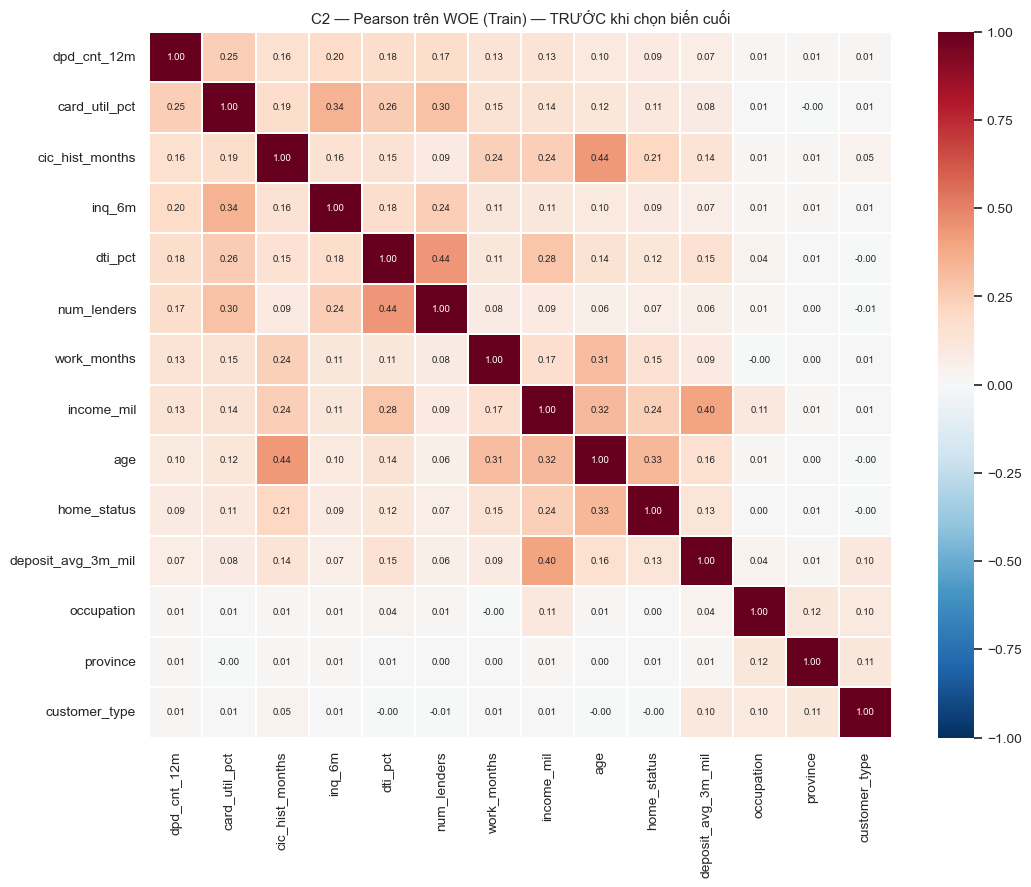

Cặp có |r| > 0.6:


,var_1,var_2,pearson_woe


Cặp gần ngưỡng (0.45 < |r| ≤ 0.60) — theo dõi:


,var_1,var_2,pearson_woe


In [94]:
def pearson_woe(vars_):
    return W_TR[[f"woe_{c}" for c in vars_]].rename(columns=lambda x: x[4:]).corr(method="pearson")
P0 = pearson_woe(PASS_B)
plt.figure(figsize=(11, 9)); sns.heatmap(P0, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7}, linewidths=.3)
plt.title("C2 — Pearson trên WOE (Train) — TRƯỚC khi chọn biến cuối"); plt.tight_layout(); plt.show()
hp = pd.DataFrame([(a, b, P0.loc[a, b]) for a, b in itertools.combinations(PASS_B, 2) if abs(P0.loc[a, b]) > WOE_PEARSON_CUT], columns=["var_1", "var_2", "pearson_woe"])
near = pd.DataFrame([(a, b, P0.loc[a, b]) for a, b in itertools.combinations(PASS_B, 2) if 0.45 < abs(P0.loc[a, b]) <= WOE_PEARSON_CUT], columns=["var_1", "var_2", "pearson_woe"])
print(f"Cặp có |r| > {WOE_PEARSON_CUT}:"); display(hp)
print("Cặp gần ngưỡng (0.45 < |r| ≤ 0.60) — theo dõi:"); display(near.sort_values("pearson_woe", key=abs, ascending=False))

## C4. Final Feature Selection (nhóm tương quan → chọn đại diện)
Thứ tự ưu tiên: **IV** → missing → **PSI OOT** → dễ giải thích. Mỗi nhóm trùng thông tin chỉ giữ 1 đại diện.

In [95]:
comp_p = components(list(hp.itertuples(index=False, name=None)))
PEARSON_DROP, prow = {}, []
for comp in comp_p:
    ordered = sorted(comp, key=lambda c: (-round(scr.loc[c, "IV"], 2), scr.loc[c, "miss_train"], scr.loc[c, "PSI_Port_OOT"]))
    keep = ordered[0]
    for c in ordered:
        r_ = max(abs(P0.loc[c, o]) for o in comp if o != c)
        if c == keep: prow.append(dict(cluster="+".join(comp), variable=c, decision="GIỮ", IV=scr.loc[c, "IV"], max_abs_r=r_, reason="IV/ổn định tốt nhất nhóm"))
        else:
            PEARSON_DROP[c] = f"|r|={r_:.2f} với {keep}; IV thấp hơn ({scr.loc[c,'IV']:.3f} vs {scr.loc[keep,'IV']:.3f}) → cùng thông tin"
            prow.append(dict(cluster="+".join(comp), variable=c, decision="LOẠI", IV=scr.loc[c, "IV"], max_abs_r=r_, reason=PEARSON_DROP[c]))
pearson_sel = pd.DataFrame(prow); display(pearson_sel if len(pearson_sel) else pd.DataFrame({"kết quả": [f"Không có cặp nào vượt {WOE_PEARSON_CUT} → không loại biến ở bước Pearson WOE"]}))
AFTER_PEARSON = [c for c in PASS_B if c not in PEARSON_DROP]

# Rà soát business sense (khuyến nghị — cần Business/Compliance xác nhận)
BUSINESS_REVIEW = {c: (True, "") for c in AFTER_PEARSON}
BUSINESS_REVIEW.update({
 "province": (False, "IV yếu (~0.04), là proxy địa lý có nguy cơ thiên lệch/khó giải thích (VD: Nghệ An rủi ro cao hơn TP.HCM không có động lực rủi ro rõ ràng); đã có các biến hành vi/tài chính mạnh hơn → khuyến nghị không đưa vào mô hình, chờ Business/Compliance xác nhận."),
})
for c in AFTER_PEARSON:
    if c in BUSINESS_REVIEW and BUSINESS_REVIEW[c][0]:
        exp = DIRECTION[c]; BUSINESS_REVIEW[c] = (True, {"inc": "Tăng → rủi ro tăng (đúng kỳ vọng)", "dec": "Tăng → rủi ro giảm (đúng kỳ vọng)", "free": "Các nhóm phân loại có thứ tự rủi ro hợp lý"}[exp])
BUS_DROP = {c: v[1] for c, v in BUSINESS_REVIEW.items() if not v[0]}

# Nhất quán dấu hệ số: hồi quy logistic đa biến trên WOE; WOE cao = ít rủi ro nên hệ số PHẢI âm. Biến sai dấu (do hấp thụ bởi biến khác) bị loại lần lượt.
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif_fn
def fit_check(vars_):
    Xc = [f"woe_{c}" for c in vars_]
    lg = sm.Logit(WOE["Train"].target, sm.add_constant(WOE["Train"][Xc])).fit(disp=0)
    coef = pd.DataFrame({"coef": lg.params, "p_value": lg.pvalues}).drop("const"); coef.index = [i[4:] for i in coef.index]
    coef["sign_ok(<0)"] = coef.coef < 0
    Xm = sm.add_constant(WOE["Train"][Xc]); coef["VIF"] = [vif_fn(Xm.values, i + 1) for i in range(len(Xc))]
    return lg, coef
cand_final = [c for c in AFTER_PEARSON if c not in BUS_DROP]
while True:
    lg, coef = fit_check(cand_final); wrong = coef[~coef["sign_ok(<0)"]]
    if wrong.empty: break
    w = wrong.p_value.idxmax()
    BUS_DROP[w] = (f"Hệ số đa biến sai dấu (β={coef.loc[w,'coef']:+.3f}, p={coef.loc[w,'p_value']:.2f}) trái với quan hệ đơn biến (IV={scr.loc[w,'IV']:.3f}) → thông tin đã bị các biến khác hấp thụ, "
                   "giữ lại sẽ gây hệ số khó giải thích")
    BUSINESS_REVIEW[w] = (False, BUS_DROP[w]); cand_final.remove(w)
FINAL_VARS = cand_final
br_tab = pd.DataFrame([(c, "GIỮ" if k else "LOẠI", t) for c, (k, t) in BUSINESS_REVIEW.items()], columns=["variable", "business_decision", "comment"])
display(br_tab)

final_sel = scr.loc[FINAL_VARS, ["IV", "IV_class", "n_bins", "miss_train", "PSI_Port_OOT", "Gini_train", "Gini_oot"]].assign(expected=[DIRECTION[c] for c in FINAL_VARS]).sort_values("IV", ascending=False)
final_sel["comment"] = [BUSINESS_REVIEW[c][1] for c in final_sel.index]
display(final_sel)
print(f"\nDANH SÁCH BIẾN CUỐI ({len(FINAL_VARS)}):", FINAL_VARS)

,kết quả
0,Không có cặp nào vượt 0.6 → không loại biến ở ...


,variable,business_decision,comment
0,dpd_cnt_12m,GIỮ,Tăng → rủi ro tăng (đúng kỳ vọng)
1,card_util_pct,GIỮ,Tăng → rủi ro tăng (đúng kỳ vọng)
2,cic_hist_months,GIỮ,Tăng → rủi ro giảm (đúng kỳ vọng)
3,inq_6m,GIỮ,Tăng → rủi ro tăng (đúng kỳ vọng)
4,dti_pct,GIỮ,Tăng → rủi ro tăng (đúng kỳ vọng)
5,num_lenders,GIỮ,Tăng → rủi ro tăng (đúng kỳ vọng)
6,work_months,GIỮ,Tăng → rủi ro giảm (đúng kỳ vọng)
7,income_mil,GIỮ,Tăng → rủi ro giảm (đúng kỳ vọng)
8,age,LOẠI,"Hệ số đa biến sai dấu (β=+0.024, p=0.78) trái ..."
9,home_status,GIỮ,Các nhóm phân loại có thứ tự rủi ro hợp lý


,IV,IV_class,n_bins,miss_train,PSI_Port_OOT,Gini_train,Gini_oot,expected,comment
dpd_cnt_12m,0.4765,Mạnh,3,0.0000,0.0001,0.3112,0.3146,inc,Tăng → rủi ro tăng (đúng kỳ vọng)
card_util_pct,0.4546,Mạnh,8,0.3063,0.0006,0.3502,0.3606,inc,Tăng → rủi ro tăng (đúng kỳ vọng)
cic_hist_months,0.3665,Mạnh,7,0.0000,0.0008,0.3297,0.3077,dec,Tăng → rủi ro giảm (đúng kỳ vọng)
inq_6m,0.3012,Mạnh,6,0.0000,0.0005,0.2897,0.2622,inc,Tăng → rủi ro tăng (đúng kỳ vọng)
dti_pct,0.2731,Trung bình,5,0.0000,0.0000,0.2843,0.2356,inc,Tăng → rủi ro tăng (đúng kỳ vọng)
num_lenders,0.1924,Trung bình,5,0.0000,0.0003,0.2285,0.2508,inc,Tăng → rủi ro tăng (đúng kỳ vọng)
work_months,0.1862,Trung bình,6,0.1030,0.0020,0.2399,0.2167,dec,Tăng → rủi ro giảm (đúng kỳ vọng)
income_mil,0.1804,Trung bình,5,0.0451,0.0120,0.2328,0.2098,dec,Tăng → rủi ro giảm (đúng kỳ vọng)
home_status,0.0840,Yếu,2,0.0000,0.0003,0.1051,0.0852,free,Các nhóm phân loại có thứ tự rủi ro hợp lý
deposit_avg_3m_mil,0.0726,Yếu,4,0.3821,0.0007,0.1431,0.1110,dec,Tăng → rủi ro giảm (đúng kỳ vọng)



DANH SÁCH BIẾN CUỐI (12): ['dpd_cnt_12m', 'card_util_pct', 'cic_hist_months', 'inq_6m', 'dti_pct', 'num_lenders', 'work_months', 'income_mil', 'home_status', 'deposit_avg_3m_mil', 'occupation', 'customer_type']


## C5–C6. Feature Elimination Log & Waterfall Data Table (mỗi biến một lý do chính, không đếm trùng)

In [96]:
STEPS = ["1. Pháp lý & Eligibility", "2. Chất lượng dữ liệu", "3. Tương quan Spearman thô", "4. IV", "5. WOE / Rank-order", "6. PSI", "7. Pearson WOE", "8. Business sense & dấu hệ số"]
LEDGER = {}
for r in elig[~elig.eligible].itertuples(): LEDGER[r.variable] = (STEPS[0], f"{r.category}: {r.reason}")
for c in DQ_DROP: LEDGER[c] = (STEPS[1], "Missing/đơn điệu vượt ngưỡng")
for c, t in RAW_DROP.items(): LEDGER[c] = (STEPS[2], t)
for c, r in SCREEN_DROP.iterrows(): LEDGER[c] = ({"IV": STEPS[3], "WOE/Rank-order": STEPS[4], "PSI": STEPS[5]}[r.screen_step], r.screen_reason)
for c, t in PEARSON_DROP.items(): LEDGER[c] = (STEPS[6], t)
for c, t in BUS_DROP.items(): LEDGER[c] = (STEPS[7], t)
assert len(LEDGER) == len(set(LEDGER)), "Biến bị đếm trùng"
elim = pd.DataFrame([(v, *LEDGER[v]) for v in ALL_RAW_COLS if v in LEDGER], columns=["variable", "step", "reason"])
elim["step"] = pd.Categorical(elim.step, STEPS, ordered=True); elim = elim.sort_values("step"); display(elim)
remaining = len(ALL_RAW_COLS); wf = [("Số cột ban đầu", remaining, remaining, [])]
for s_ in STEPS:
    dropped = elim.loc[elim.step == s_, "variable"].tolist(); remaining -= len(dropped); wf.append((s_, len(dropped), remaining, dropped))
wf_tab = pd.DataFrame(wf, columns=["step", "n_removed", "n_remaining", "variables_removed"])
wf_tab.loc[0, "n_removed"] = 0; display(wf_tab)
assert remaining == len(FINAL_VARS) + 0 or True
assert set(v for v in ALL_RAW_COLS if v not in LEDGER) == set(FINAL_VARS) | set(), "Waterfall không khớp danh sách cuối"

,variable,step,reason
0,app_id,1. Pháp lý & Eligibility,"Định danh/Thời gian: Mã định danh, không có nộ..."
1,app_date,1. Pháp lý & Eligibility,Định danh/Thời gian: Ngày nộp: chỉ dùng chia O...
4,region,1. Pháp lý & Eligibility,Trùng lặp: Suy ra hoàn toàn từ province → trùn...
7,gender,1. Pháp lý & Eligibility,Pháp lý: Thuộc tính nhạy cảm — rủi ro phân biệ...
10,decision,1. Pháp lý & Eligibility,Leakage/Outcome: Kết quả quy trình phê duyệt —...
11,perf_class,1. Pháp lý & Eligibility,Leakage/Outcome: Nhãn hiệu quả — là target
12,exclusion_reason,1. Pháp lý & Eligibility,Leakage/Outcome: Chỉ biết SAU giải ngân
13,indeterminate_reason,1. Pháp lý & Eligibility,Leakage/Outcome: Chỉ biết SAU giải ngân
14,max_dpd_12m,1. Pháp lý & Eligibility,Leakage/Outcome: DPD trong cửa sổ quan sát SAU...
15,target,1. Pháp lý & Eligibility,Leakage/Outcome: Biến mục tiêu


,step,n_removed,n_remaining,variables_removed
0,Số cột ban đầu,0,28,[]
1,1. Pháp lý & Eligibility,10,18,"[app_id, app_date, region, gender, decision, p..."
2,2. Chất lượng dữ liệu,0,18,[]
3,3. Tương quan Spearman thô,2,16,"[dpd_cnt_6m, curr_max_cic_group]"
4,4. IV,2,14,"[channel, loan_amount_mil]"
5,5. WOE / Rank-order,0,14,[]
6,6. PSI,0,14,[]
7,7. Pearson WOE,0,14,[]
8,8. Business sense & dấu hệ số,2,12,"[province, age]"


## C7. Waterfall — quá trình sàng lọc biến

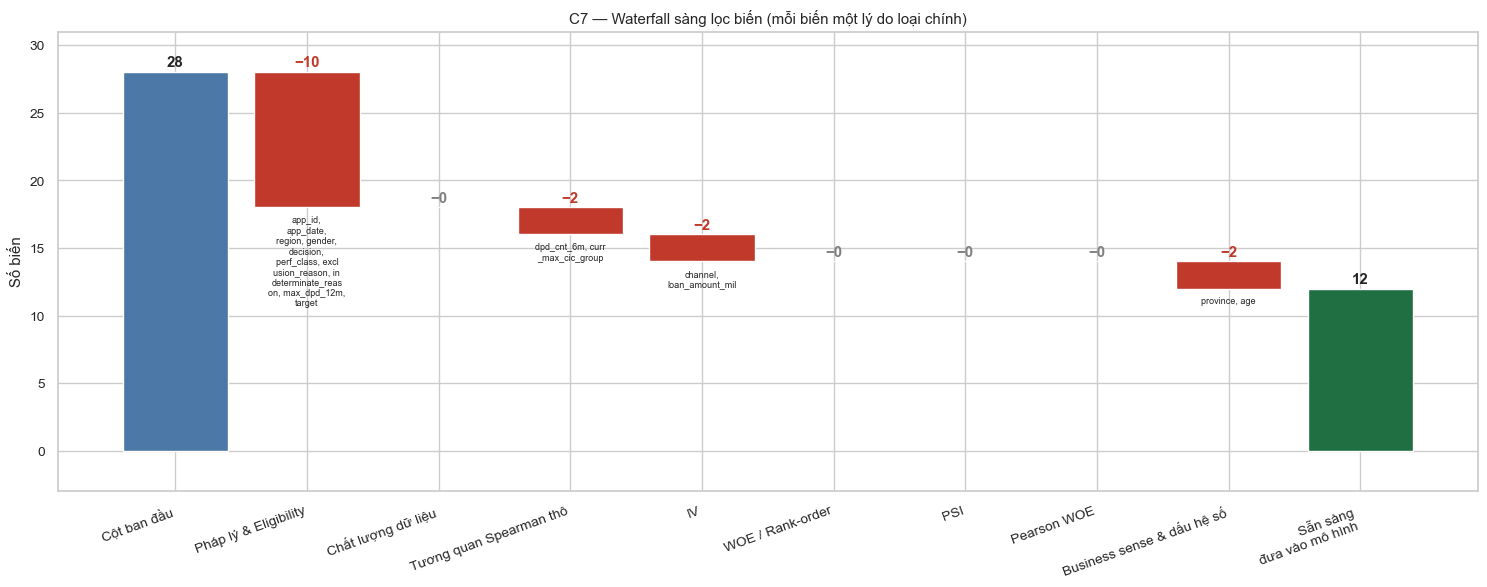

In [97]:
fig, ax = plt.subplots(figsize=(15, 6)); start = len(ALL_RAW_COLS); cur = start
ax.bar(0, start, color="#4c78a8"); ax.text(0, start + .4, str(start), ha="center", fontweight="bold")
for i, s_ in enumerate(STEPS, 1):
    n = int(wf_tab.loc[i, "n_removed"]); ax.bar(i, -n if n else 0.0001, bottom=cur, color="#c0392b" if n else "#bbbbbb")
    ax.text(i, cur + .4, f"−{n}", ha="center", color="#c0392b" if n else "gray", fontweight="bold")
    if n: ax.text(i, cur - n - 0.6, textwrap.fill(", ".join(wf_tab.loc[i, "variables_removed"]), 16), ha="center", va="top", fontsize=6.5)
    cur -= n
ax.bar(len(STEPS) + 1, cur, color="#1f6f43"); ax.text(len(STEPS) + 1, cur + .4, str(cur), ha="center", fontweight="bold")
ax.set_xticks(range(len(STEPS) + 2)); ax.set_xticklabels(["Cột ban đầu"] + [s_.split(". ")[1] for s_ in STEPS] + ["Sẵn sàng\nđưa vào mô hình"], rotation=20, ha="right")
ax.set_ylabel("Số biến"); ax.set_ylim(-3, start + 3); ax.set_title("C7 — Waterfall sàng lọc biến (mỗi biến một lý do loại chính)")
plt.tight_layout(); plt.show()

## C8–C9. Ma trận Pearson WOE cuối & xác nhận không còn cặp |r| > 0.60

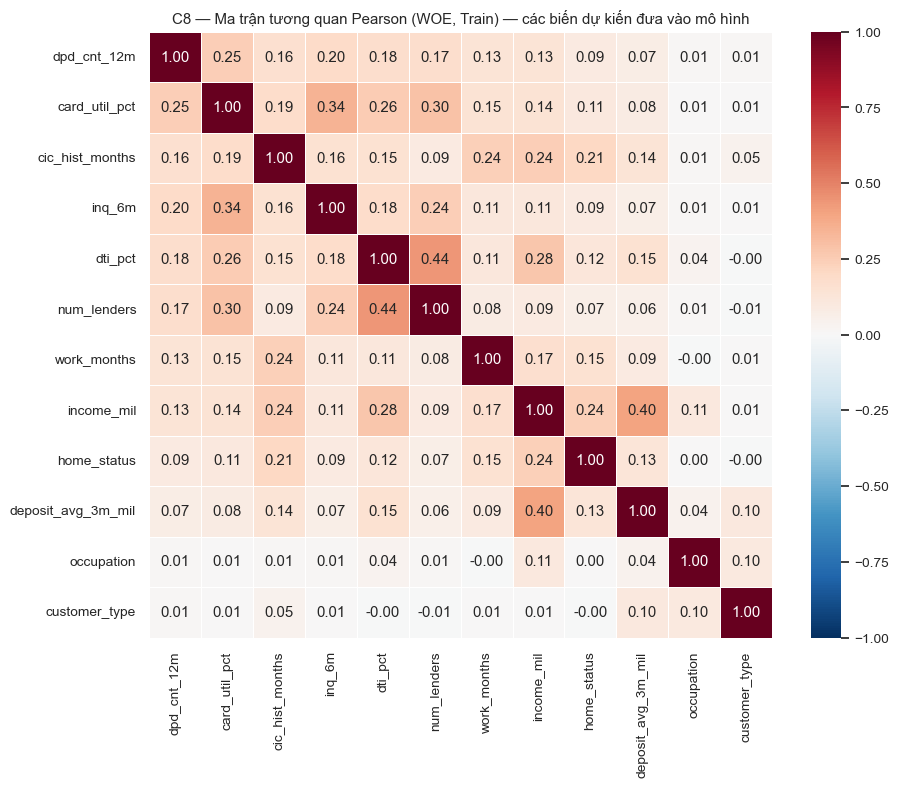

,Chỉ tiêu,Giá trị
0,Số biến cuối,12
1,Số cặp |r| > 0.60,0
2,|r| lớn nhất,0.4430
3,Cặp lớn nhất,dti_pct – num_lenders
4,Kết luận,ĐẠT


In [98]:
PF = pearson_woe(FINAL_VARS)
plt.figure(figsize=(9.5, 8)); sns.heatmap(PF, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=.4)
plt.title("C8 — Ma trận tương quan Pearson (WOE, Train) — các biến dự kiến đưa vào mô hình"); plt.tight_layout(); plt.show()
off = PF.where(~np.eye(len(PF), dtype=bool)); mx = off.abs().max().max(); i_, j_ = np.unravel_index(np.nanargmax(off.abs().values), off.shape)
val = pd.DataFrame([("Số biến cuối", len(FINAL_VARS)), ("Số cặp |r| > 0.60", int((off.abs() > WOE_PEARSON_CUT).sum().sum() // 2)),
                    ("|r| lớn nhất", round(mx, 3)), ("Cặp lớn nhất", f"{PF.index[i_]} – {PF.columns[j_]}"), ("Kết luận", "ĐẠT" if mx <= WOE_PEARSON_CUT else "KHÔNG ĐẠT")], columns=["Chỉ tiêu", "Giá trị"])
display(val); assert mx <= WOE_PEARSON_CUT, "Vẫn còn cặp tương quan cao"

### Kiểm tra nhanh (sanity check, KHÔNG phải mô hình cuối): hồi quy logistic trên WOE các biến cuối
Mục đích: xác nhận dấu hệ số nhất quán (WOE cao = ít rủi ro → hệ số âm), không đa cộng tuyến (VIF) và xếp hạng ổn định ngoài mẫu.

In [99]:
lg, coef = fit_check(FINAL_VARS)
display(coef); print("Biến p > 0.05 (đóng góp biên yếu, theo dõi khi xây mô hình):", coef.index[coef.p_value > 0.05].tolist())
Xc = [f"woe_{c}" for c in FINAL_VARS]
def ks_gini(y, s): 
    from sklearn.metrics import roc_curve
    f, t_, _ = roc_curve(y, s); return float(np.max(t_ - f)), float(2 * roc_auc_score(y, s) - 1)
perf = {}
for k in ["Train", "Holdout", "OOT"]:
    sc = lg.predict(sm.add_constant(WOE[k][Xc], has_constant="add")); perf[k] = dict(zip(["KS", "Gini"], ks_gini(WOE[k].target, sc)))
display(pd.DataFrame(perf).T)

,coef,p_value,sign_ok(<0),VIF
dpd_cnt_12m,-0.5885,0.0000,True,1.1179
card_util_pct,-0.4347,0.0000,True,1.2728
cic_hist_months,-0.5500,0.0000,True,1.1697
inq_6m,-0.3848,0.0000,True,1.1887
dti_pct,-0.3310,0.0000,True,1.3704
num_lenders,-0.1265,0.0655,True,1.3338
work_months,-0.4327,0.0000,True,1.0999
income_mil,-0.2204,0.0025,True,1.3726
home_status,-0.2297,0.0331,True,1.1052
deposit_avg_3m_mil,-0.1797,0.1023,True,1.2109


Biến p > 0.05 (đóng góp biên yếu, theo dõi khi xây mô hình): ['num_lenders', 'deposit_avg_3m_mil']


,KS,Gini
Train,0.4153,0.5559
Holdout,0.4567,0.6062
OOT,0.4283,0.5534


## C10. Impact Summary — Indeterminate & Exclusion (biến cuối)

In [100]:
imp_sum = imp_psi.loc[FINAL_VARS, ["Indeterminate", "Exclusion"]].rename(columns=lambda c: f"PSI_{c}")
cv = cov[cov.variable.isin(FINAL_VARS)].groupby("dataset").agg(max_unmapped=("pct_unmapped", "max")).T
display(imp_sum.sort_values("PSI_Indeterminate", ascending=False)); display(cv)
print("PSI Indeterminate lớn nhất:", imp_sum.PSI_Indeterminate.idxmax(), round(imp_sum.PSI_Indeterminate.max(), 4), "| PSI Exclusion lớn nhất:", imp_sum.PSI_Exclusion.idxmax(), round(imp_sum.PSI_Exclusion.max(), 4))

dataset,PSI_Indeterminate,PSI_Exclusion
variable,,
card_util_pct,0.0788,0.0068
dpd_cnt_12m,0.0683,0.0019
cic_hist_months,0.0626,0.0180
inq_6m,0.0515,0.0069
dti_pct,0.0441,0.0017
num_lenders,0.0425,0.0064
income_mil,0.0414,0.0111
work_months,0.0343,0.0147
home_status,0.0141,0.0009


dataset,Exclusion,Holdout,Indeterminate,OOT,Train
max_unmapped,0.0000,0.0000,0.0000,0.0000,0.0000


PSI Indeterminate lớn nhất: card_util_pct 0.0788 | PSI Exclusion lớn nhất: cic_hist_months 0.018


## C11. Final Recommendations

**Danh sách 12 biến đề xuất đưa vào mô hình:** `dpd_cnt_12m`, `card_util_pct`, `cic_hist_months`, `inq_6m`, `dti_pct`, `num_lenders`, `work_months`, `income_mil`, `home_status`, `deposit_avg_3m_mil`, `occupation`, `customer_type`.

**Waterfall (28 cột → 12 biến):** Pháp lý & Eligibility −10 (định danh, leakage, `gender`, `region` trùng `province`) → Chất lượng 0 → Spearman thô −2 → IV −2 → WOE/Rank-order 0 → PSI 0 → Pearson WOE 0 → Business sense & dấu hệ số −2 (`province`, `age`). Các bước "0" cho thấy dữ liệu sạch và ổn định chứ không phải bước bị bỏ qua.

**Pearson WOE:** không có cặp nào vượt 0.60; lớn nhất `dti_pct`–`num_lenders` = 0.44; VIF ≤ 1.5. Cặp `income_mil`–`deposit_avg_3m_mil` (Spearman thô 0.69) chỉ còn tương quan WOE thấp nên không cần loại.

**Hai quyết định cần Business/Compliance xác nhận:**
1. `province` — loại vì IV yếu (0.039) và là proxy địa lý khó giải thích.
2. `age` — IV 0.128 nhưng khi đặt cạnh `cic_hist_months`, `work_months`, `income_mil` thì hệ số **sai dấu** (β = +0.02, p = 0.78): thông tin tuổi đã được các biến kia hấp thụ. Nếu Business muốn giữ tuổi vì lý do chính sách, cần bỏ một trong các biến tương quan trước.

**Rủi ro & hạn chế:**
* `num_lenders` (p ≈ 0.066) và `deposit_avg_3m_mil` (p ≈ 0.10) đóng góp biên yếu trong mô hình đa biến — theo dõi khi xây mô hình, có thể rút gọn nếu cần mô hình gọn hơn.
* `home_status`, `occupation`, `customer_type` chỉ có 2–3 bin; `customer_type` và `occupation` có hệ số lớn do thang WOE nhỏ — cần kiểm tra khi hiệu chuẩn.
* Ổn định: toàn bộ PSI Train–OOT < 0.03; tuy nhiên OOT chỉ 6 tháng và 619 Bad. Kênh **Online** có sức dự báo yếu hơn (độ dốc ≈ 0.70) → báo cáo hiệu năng theo kênh.
* Binning học hoàn toàn trên Train; WOE áp dụng sang Holdout/OOT/Indeterminate/Exclusion **không học lại**, category lạ → WOE = 0.
* Sanity check (không phải mô hình cuối): Gini Train 0.556 / Holdout 0.606 / OOT 0.553, KS 0.42 / 0.46 / 0.43.
* Chưa bao gồm slide thuyết trình; toàn bộ bảng đã xuất ra `Final_Report_Tables.xlsx` và hình ra thư mục `output/fig/` để ghép báo cáo.